# Preparation

## Modules

In [150]:
## imports
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import stereo as st
import warnings
warnings.filterwarnings('ignore')
import scipy as sc
import scikit_posthocs
import gefpy
import math
#import randomcolor
from os import path
from chromato import convert
import colorcet
import itertools
from statannotations.Annotator import Annotator
from scipy.stats import zscore
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.genmod.cov_struct import Exchangeable, Independence
colormaps = colorcet.palette
colormaps['stereo_30'] = ["#E41A1C", "#377EB8", "#4DAF4A", "#984EA3", "#FF7F00", "#A65628", "#FFFF33",
                          "#F781BF", "#999999", "#E5D8BD", "#B3CDE3", "#CCEBC5", "#FED9A6", "#FBB4AE",
                          "#8DD3C7", "#BEBADA", "#80B1D3", "#B3DE69", "#FCCDE5", "#BC80BD", "#FFED6F",
                          "#8DA0CB", "#E78AC3", "#E5C494", "#CCCCCC", "#FB9A99", "#E31A1C", "#CAB2D6",
                          "#6A3D9A", "#B15928"]
stmap_colors = ['#0c3383', '#0a88ba', '#f2d338', '#f28f38', '#d91e1e'] # stereo
nodes = [0.0, 0.25, 0.50, 0.75, 1.0]
mycmap = matplotlib.colors.LinearSegmentedColormap.from_list("mycmap", list(zip(nodes, stmap_colors)))
color_list = [matplotlib.colors.rgb2hex(mycmap(i)) for i in range(mycmap.N)]
colormaps['stereo'] = color_list
palette1 = ["#F7C8A4", "#C1A59D", "#979A9B", "#7795A2", "#497889"]
palette2 = ["#798234", "#A3AD62", "#D0D3A2", "#FDFBE4", "#F0C6C3", "#DF91A3", "#D46780"]
palette3 = sns.color_palette("blend:{},#FFFFFF,{}".format(palette2[0],palette2[-1]), as_cmap=True)
palette4 = ["#585870", "#68B8B8", "#609098", "#90D0D0", "#F8A050", 
            "#F07838", "#C86020", "#A8A8D0", "#C0C0E8", "#808098", 
            "#D8D8F8", "#A8E8E8", "#A07858", "#F8F8F8"]
palette5 = ["#ECDA9A", "#EFC47E", "#F3AD6A", "#F7945D", "#F97B57", "#F66356", "#EE4D5A"]
palette6 = ["#24492E", "#015B58", "#2C6184", "#59629B", "#89689D", "#BA7999", "#E69B99"]
palette7 = ["#462356","#FF8811","#9EDAD3"]
palette8 = ["#EC008B","#FFDD14","#A4AA98","#754C28","#F9B8AB"]

reds = sns.color_palette("blend:#ffffff,#ff0000", as_cmap=True)
blues = sns.color_palette("blend:#ffffff,#0000ff", as_cmap=True)
greens = sns.color_palette("blend:#ffffff,#00ff00", as_cmap=True)
blacks = sns.color_palette("blend:#ffffff,#000000", as_cmap=True)

## Functions

### Plot

In [2]:
####################         PLOT         ####################

def plotStyle():
    ''' Define plot style '''
    from matplotlib import rcParams
    rcParams['font.family'] = 'Nimbus Sans'
    #rcParams['font.sans-serif'] = ['Arial']
    rcParams['font.size'] = 12
    rcParams['axes.linewidth'] = 1
    rcParams['grid.linewidth'] = 0
    rcParams['grid.color'] = 'gainsboro'
    rcParams['font.weight'] = 'normal'
    rcParams['axes.labelweight'] = 'bold'
    #rcParams['axes.labelsize'] = 15
    rcParams['legend.edgecolor'] = 'black'
    rcParams["axes.spines.right"] = False
    rcParams["axes.spines.top"] = False
    rcParams["figure.autolayout"] = True
    rcParams['savefig.pad_inches'] = 0.5
plotStyle()
sns.set_palette("Set2")

def adjust(df, d, bin_size, subplot=False, factor=1): # for plotting 8 subplots #bin100
    '''Adjust plot spacing to 3:2 ratio'''
    d = datanames[datalist.index(d)]
    TARGET_RATIO = 1.5
    FIXED_X_LEN = 15000
    FIXED_Y_LEN = 10000 
    xlim = None
    ylim = None 
    dx1 = max(df["x"])-min(df["x"])
    dy1 = max(df["y"])-min(df["y"])
    if bin_size == 100:
        if d == "SD1182": 
            dx1 = 11000
        if d == "SD1225":
            #dx1 = 8000
            dy1 = 12000
    elif bin_size == 30:
        if d == "SD1182": 
            dx1 = 10000
        if d == "SD1225":
            #dx1 = 8000
            dy1 = 12000
    r1 = dx1/dy1 #round(dx1/dy1,1)
    dx2 = dx1
    dy2 = dy1
    dx2 = TARGET_RATIO*dy1
    pad = abs(dx1-dx2)/2
    dy2 = dx1/TARGET_RATIO
    pad = abs(dy1-dy2)/2

    # additional padding for small samples
    addpadx = abs((FIXED_X_LEN-dx2)/2)
    addpady = abs((FIXED_Y_LEN-dy2)/2)
    #factor2 = FIXED_X_LEN/dx2
    factor2 = ((FIXED_X_LEN/dx2) + (FIXED_Y_LEN/dy2))/2
    #dot_size = (3*factor) * factor2 #3
    if bin_size == 100:
        if subplot:
            dot_size = (3*factor) * factor2 #3
            if d == "SD1225": dot_size = 5
            if d == "SD1043": dot_size = 1.5
        else:
            dot_size = (3*factor) * factor2 #3
            if d == "SD1043": dot_size = 2
    elif bin_size == 30:
        if subplot:
            dot_size = (.5*factor) * factor2 #3
            if d == "SD1043": dot_size = .2
        else:
            dot_size = (2*factor) * factor2 #3
            if d == "SD1043": dot_size = 1.5

    return r1, xlim, ylim, pad, addpadx, addpady, dot_size

def cmyk_to_rgb(c, m, y, k):
    c /= 100
    m /= 100
    y /= 100
    k /= 100

    r = round(255 * (1-c) * (1-k))
    g = round(255 * (1-m) * (1-k))
    b = round(255 * (1-y) * (1-k))

    return (r, g, b)

### Stat

In [3]:
####################         STAT         ####################

def normalize(arr, t_min, t_max):
    norm_arr = []
    diff = t_max - t_min
    diff_arr = max(arr) - min(arr)
    for i in arr:
        temp = (((i - min(arr))*diff)/diff_arr) + t_min
        norm_arr.append(temp)
    return norm_arr

def normalize2(arr, t_min, t_max):
    arr_min = min(arr)
    arr_max = max(arr)
    diff_arr = arr_max - arr_min
    diff = t_max - t_min
    if diff_arr == 0:
        return [t_min for _ in arr]  # or [t_max], or just arr — depending on expected behavior
    return [((x - arr_min) * diff / diff_arr) + t_min for x in arr]

def norm_log(x, cr, d=False): # for pd.Series, not pd.DataFrame, full 18115
    if not isinstance(d, bool):
        nor_x = x * 10000 / d.sum(axis=1).values
    else:
        nor_x = x * 10000 / cr.sum(axis=1).values
    nor_x.replace([np.inf, -np.inf], 0, inplace=True)
    nor_x = nor_x.fillna(0)
    log_x = np.log1p(nor_x) # log(1 + x)
    return log_x
    
def norm_log2(x, total_counts, d=False): # for pd.Series, not pd.DataFrame, full 18115
    if not isinstance(d, bool):
        nor_x = x * 10000 / d.sum(axis=1).values
    else:
        nor_x = x * 10000 / total_counts
    nor_x.replace([np.inf, -np.inf], 0, inplace=True)
    nor_x = nor_x.fillna(0)
    log_x = np.log1p(nor_x) # log(1 + x)
    return log_x
    
def norm_log_all(x): # for pd.DataFrame
    nor_x = x * 10000 / x.sum(axis=1)[:, np.newaxis]
    nor_x = nor_x.fillna(0)
    log_x = np.log1p(nor_x) # log(1 + x)
    return log_x
    
def norm_log_all_norm(x): # for pd.DataFrame
    nor_x = x * 10000 / x.sum(axis=1)[:, np.newaxis]
    nor_x = nor_x.fillna(0)
    log_x = np.log1p(nor_x) # log(1 + x)
    norm_x = normalize(log_x,0,1)
    return norm_x
    
def norm_total(x, target_sum):
    nor_x = x * target_sum / x.sum(axis=1)[:, np.newaxis]
    return nor_x
    
def min_max_scaler(X, min=0, max=1):
    X_std = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))
    X_scaled = X_std * (max - min) + min
    return X_scaled

def significance_stars(pvalue):
    ''' Annotate significance '''
    if pvalue < .001:
        pv = "***"
    elif pvalue < .01:
        pv = "**"
    elif pvalue < .05:
        pv = "*"
    else:
        pv = "%.2f" % pvalue

    return pv

def interpret_test(statistic, size1, size2, group1="Group 1", group2="Group 2"):
    max_value = size1 * size2
    midpoint = max_value / 2
    if statistic > midpoint:
        print("%s has higher ranked values %.2f" % (group1, statistic/midpoint))
    else:
        print("%s has higher ranked values %.2f" % (group2, statistic/midpoint))


### Gene

In [4]:
####################        GENE          ####################

def search_genes(search, area="all"):
    ''' Search for genes in gene expression data '''
    if area == "all":
        allgenes = pd.Series(allcountscombined.columns)
    else:
        allgenes = pd.Series(allcounts[area].columns)
    return allgenes[allgenes.str.startswith(search)]

### Mutation

In [5]:
####################      MUTATION        ####################

def mutation_presets3(df, preset):
    ''' Filter preset mutations '''
    #i = datalist.index(d)
    #df = all_mutations[i].copy()
    df = df[df["cDnaChange"].str.endswith("C>T", na=False)]
    df1 = df[df["adjusted_trinucleotide"]=="TCA"]
    
    if preset == "CT":
        return df
    elif preset == "TCA":
        return df1
    elif preset == "YTCA":
        return df1[((df1["transcriptStrand"]=="+") & ((df1["up2"]=="C") | (df1["up2"]=="T"))) |
                   ((df1["transcriptStrand"]=="-") & ((df1["down2"]=="G") | (df1["down2"]=="A")))
        ]
    elif preset == "RTCA":
        return df1[((df1["transcriptStrand"]=="+") & ((df1["up2"]=="G") | (df1["up2"]=="A"))) |
                   ((df1["transcriptStrand"]=="-") & ((df1["down2"]=="C") | (df1["down2"]=="T")))
        ]
    
def filter_mutations(df, col, filter):
    ''' Filter mutations from specific dataframe '''
    return df[df[col]==filter]

def filter_all_mutations(muttype, mut="mutation", concat=True):
    ''' Filter mutations from all dataframes '''
    dfs = []
    for i,d in enumerate(datalist):
        df = round_and_norm(filter_mutations(all_muts[i], mut, muttype), d)
        df["sample"] = d
        df["status"] = status[i]
        df["carrier_status"] = carrier_status[i]
        df["immune_status"] = immune_status[i]
        dfs.append(df)
    if concat:
        return pd.concat(dfs)
    else:
        return dfs
    
def round_and_norm(df, d):
    i = datalist.index(d)
    # print(i)
    df_round = df.groupby(["round_x","round_y"]).size().reset_index()
    df_round = df_round.reset_index()
    df_round.drop(columns=["index"], inplace=True)
    df_round.rename(columns={0: "filtered_count"}, inplace=True)

    df_norm = pd.merge(odfs[i], df_round, how='left') #
    df_norm = df_norm.rename(columns={"round_x": "x", "round_y": "y"})
    df_norm.index = df_norm["index"]
    df_norm = df_norm.drop(columns=["index"])
    df_norm.fillna(0, inplace=True)
    df_norm["filtered_count"] = df_norm["filtered_count"].astype("int")

    ## normalised and logged
    normlogged = norm_log2(df_norm["filtered_count"], alldfs[i].total_counts.to_numpy()) #, df_norm.loc[df_norm.index]
    # normlogged = norm_log(df_norm["filtered_count"], rawcounts[i]) #, df_norm.loc[df_norm.index]
    try: df_norm["normlogfiltered"] = normalize2(normlogged,0,1) #rawcounts
    except ZeroDivisionError:
        print("zero")

    return df_norm

def top_ten(df, group, top=10):
    ''' Extract top 10 mutations '''
    return df.groupby(group).size().reset_index().sort_values(0, ascending=False).head(top)

def extract_apobec_sig2(df):
    ''' Extract APOBEC SBS2 & SBS13 mutations '''
    return df[(
        ((df.cDnaChange.str.endswith("C>T", na=False)) | (df.cDnaChange.str.endswith("C>G", na=False)))
        & (df.adjusted_trinucleotide == "TCA")
    )]

def extract_sig2(sig, df):
    ''' Extract SBS mutations '''
    if sig == 2: # TCA, C>T
        return df[(
            (df.cDnaChange.str.endswith("C>T", na=False))
            & (df.adjusted_trinucleotide == "TCA")
        )]

    elif sig == 13: # TCA, C>G
        return df[(
            (df.cDnaChange.str.endswith("C>G", na=False))
            & (df.adjusted_trinucleotide == "TCA")
        )]

    elif sig == 1:
        return df[(
            (df.cDnaChange.str.endswith("C>T", na=False))
            & (((df.transcriptStrand == "+") & (df.trinucleotide.str.endswith("CG")))
              | ((df.transcriptStrand == "-") & (df.trinucleotide.str.startswith("CG"))))
        )]
    elif sig == 4:
        return df[(
            (df.cDnaChange.str.endswith("C>A", na=False))
            # & (((df.transcriptStrand == "+") & (df.trinucleotide.str.endswith("CG")))
            #   | ((df.transcriptStrand == "-") & (df.trinucleotide.str.startswith("CG"))))
        )]
    elif sig == 10:
        return df[(
            (df.cDnaChange.str.endswith("C>A", na=False))
            & (((df.transcriptStrand == "+") & (df.trinucleotide == "TCT"))
              | ((df.transcriptStrand == "-") & (df.trinucleotide == "AGA")))
        )]
    
def extract_mutations_celltypes(cell, df, all_muts, ct, cat="majortype", filter=True):
    ## map mutations back to transcripts

    if filter:
        ### filter for bins in cancer epithelium
        df.index = df.index.astype("int64")
        df[cat] = ct[cat].to_list()
        if isinstance(cell, str):
            df1 = df[df[cat]==cell]
        elif isinstance(cell, np.ndarray):
            df1 = df[df[cat].isin(cell)]
        elif cell is None:
            df1 = df.copy()
        df1 = df1[df1["normlogfiltered"]>0] ## filter for bins with mutation
    else:
        df1 = df.copy()
    
    ### extract transcripts with matching coordinates wih bins in cancer epithelium
    nc_list = []
    for i,d in enumerate(datalist):
        df = df1[df1["sample"]==d].merge(all_muts[i], left_on=["x","y"], right_on=["round_x","round_y"])
        # neo_cancer = all_all_neos.merge(df1, right_on=["x","y"], left_on=["round_x","round_y"], how="left")
        nc_list.append(df)
    mut_cancer = pd.concat(nc_list)
    return mut_cancer

## Var

In [6]:
datanames = [
    "SD507","SD560","SD1043", # A3B del/del
    "SD1182","SD1225", # A3B del/WT
    "SD683","SD693","SD781" # WT
]
datalist = [
    "HOM1","HOM2","HOM3",
    "HET1","HET2",
    "WT1","WT2","WT3"
]
status = ["A3B del/del", "A3B del/del", "A3B del/del",
          "A3B del/WT", "A3B del/WT",
          "WT", "WT", "WT"]
carrier_status = ["carrier","carrier","carrier","carrier","carrier",
          "non-carrier","non-carrier","non-carrier"]

In [125]:
lineage_markers3 = {
    "CAFs": ["MMP11","COL1A1","POSTN"],
    "PVL": ["PDGFRB","COL3A1"],
    "Endothelial": ["VWF","ACKR1"],
    "Normal Epithelial": ["MKI67","CD34","CD45","CD14","ACTA2"],
    "Cancer Epithelial": ["EPCAM","KRT17"],
    "B-cells": ["CD79A","MS4A1","PLA2GA2"],
    "Plasmablasts": ["IGHG1","JCHAIN","MZB1"],
    "Myeloid": ["CD11C","HLA-DRA","C1QB","CD68","CD163","CD14","CD33","CD64","LYZ","FCGR3A"],
    "T-cells": ["CD3D","CD3E"]
} 

kegg_apm = ["TAP1","TAP2","TAPBP","PDIA3","CALR","HLA-A","HLA-B","HLA-C","HLA-E","HLA-F","HLA-G","B2M"]
# https://www.kegg.jp/entry/N00363

apm_lit1 = ["B2M", "CALR", "CANX", "ERAP1", "ERAP2", "HLA-A", "HLA-B", "HLA-C", "PDIA3", 
            "PSMB5", "PSMB6", "PSMB7", "PSMB8", "PSMB9", "PSMB10", "TAP1", "TAP2", "TAPBP"]
# https://doi.org/10.1016/j.neo.2023.100942

# BIN100

## Data

In [7]:
bin_size = 100
n_pcs = 20
n_neighbors = 10
spread = 20
min_dist = .2
alpha = 30.0

In [8]:
alldata = []
for i,d in enumerate(datalist):
    d = datanames[i]
    data_path = "/stereoseq/all_samples/h5ad/bin{0}/{1}.bin{0}.processed.h5ad".format(bin_size,d)
    alldata.append(st.io.read_stereo_h5ad(file_path=data_path))

In [210]:
for i,d in enumerate(datalist):
    alldata[i].tl.spatial_neighbors(n_neighbors=6, res_key="spatial_neighbors")

[2026-11-03 17:08:13][Stereo][1979][MainThread][137637917132608][st_pipeline][41][INFO]: start to run spatial_neighbors...
[2026-11-03 17:08:17][Stereo][1979][MainThread][137637917132608][reader][914][INFO]: Adding sample in adata.obs['orig.ident'].
[2026-11-03 17:08:17][Stereo][1979][MainThread][137637917132608][reader][917][INFO]: Adding data.position as adata.obsm['spatial'] .
[2026-11-03 17:08:17][Stereo][1979][MainThread][137637917132608][reader][922][INFO]: Adding data.position as adata.obs['x'] and adata.obs['y'] .
[2026-11-03 17:08:17][Stereo][1979][MainThread][137637917132608][reader][955][INFO]: Adding data.tl.result['highly_variable_genes'] into adata.var .
[2026-11-03 17:08:17][Stereo][1979][MainThread][137637917132608][reader][977][INFO]: Adding data.tl.result['pca'] into adata.obsm['X_pca'] .
[2026-11-03 17:08:17][Stereo][1979][MainThread][137637917132608][reader][982][INFO]: Adding data.tl.result['pca_variance_ratio'] into adata.uns['pca_variance_ratio'] .
[2026-11-03 17

In [10]:
alldfs = []
for i,d in enumerate(datalist):
    df = pd.DataFrame(index=alldata[i].cells.cell_name.astype("int64"))
    df["x"] = alldata[i].position[:,0]
    df["y"] = alldata[i].position[:,1]
    df["total_counts"] = alldata[i].cells.total_counts
    df["umapx"] = list(alldata[i].tl.result["umap"][0])
    df["umapy"] = list(alldata[i].tl.result["umap"][1])
    df["group"] = list(alldata[i].tl.result["leiden"]["group"].astype("int").astype("category"))
    df["batch"] = d
    df["status"] = status[i]
    df["carrier_status"] = carrier_status[i]
    alldfs.append(df)

In [11]:
odfs = []
for i,d in enumerate(datalist):
    odf = pd.DataFrame(index=alldata[i].cells.cell_name) #.astype("int64")
    odf["index"] = list(alldata[i].cells.cell_name)
    odf["round_x"] = alldata[i].position[:,0]
    odf["round_y"] = alldata[i].position[:,1]
    odf["total_counts"] = alldata[i].cells.total_counts
    odfs.append(odf)

In [12]:
allcounts = []
rawcounts = []
for i,d in enumerate(datalist):
    df = alldata[i].to_df()
    df.index = df.index.astype("int64")
    allcounts.append(df)
allcountscombined = pd.concat(allcounts)

## Cell types

In [13]:
subsets = pd.read_excel("/stereoseq/reference/scRNAseq/GSE176078/type_names.xlsx", "subsets", index_col=0)
subsets_immunes = subsets[subsets.main=="Immune"]
sorted_subtypes = subsets.sort_values(by=["main","major","minor","subset"])

In [14]:
raw_weights2 = []
weights2 = []
for i,d in enumerate(datalist):
    d = datanames[i]
    df = pd.read_csv(f"/stereoseq/all_samples/spacexr/bin{bin_size}/{d}.bin{bin_size}.RCTD.GSE176078.full.results2.csv", 
                     index_col=0, header=0, names=subsets.sort_values(by="subset", key=lambda col: col.str.lower()).name.to_list())
    # df = df[subsets["subset"].to_list()]
    raw_weights2.append(pd.read_csv(f"/stereoseq/all_samples/spacexr/bin{bin_size}/{d}.bin{bin_size}.RCTD.GSE176078.full.results2.csv", 
                     index_col=0))
    df = norm_total(df, 1)
    df1 = alldfs[i].merge(df, how="left", left_on=alldfs[i].index, right_on=df.index)
    df1.index = alldfs[i].index
    df1["cstatus"] = carrier_status[i]
    weights2.append(df1)

In [15]:
weightsmajor2 = []
for i,d in enumerate(datalist):
    df = pd.DataFrame(index=weights2[i].index)
    for major in subsets.major.unique():
        df[major] = weights2[i].filter(subsets[subsets.major==major]["name"]).sum(axis=1).to_list()
    #weightssum.append(df)
    df["cstatus"] = carrier_status[i]
    weightsmajor2.append(alldfs[i].join(df))

In [16]:
weightsminor2 = []
for i,d in enumerate(datalist):
    df = pd.DataFrame(index=weights2[i].index)
    for minor in subsets.minor.unique():
        df[minor] = weights2[i].filter(subsets[subsets.minor==minor]["name"]).sum(axis=1).to_list()
    #weightssum.append(df)
    df["cstatus"] = carrier_status[i]
    weightsminor2.append(alldfs[i].join(df))

In [17]:
colors = {
    "Immune": "r",
    "CAF": "g",
    "Cancer": "b",
    "Others": "k",
    "NA": "y"
}

In [19]:
## assign cell type to each bin
thresh = 0.6
weightscat2 = []
for i,d in enumerate(datalist):
    df = weightsmajor2[i].drop(columns=subsets["major"].unique())
    for group in subsets.main.unique():
        #weights_cat[group] = weights[i].filter(np.unique(types[types["rgb"]==group]["major"].values)).sum(axis=1).to_list()
        df[group] = weights2[i].filter(np.unique(subsets[subsets["main"]==group]["minor"].unique())).sum(axis=1).to_list()
    df["total"] = df.filter(subsets.main.unique()).sum(axis=1).to_list()
    designations = []
    c = []
    for i in range(len(df)):
        desig = "NA" #Mixed
        highest = 0
        for group in subsets.main.unique():
            tmp = df.iloc[i][group]/df.iloc[i].total
            if tmp > highest: ## if just want to find highest
                highest = tmp
                desig = group
            #if tmp >= thresh: ## more than 80% this cell type then desig is this group
            #    desig = group
        designations.append(desig)
        c.append(colors[desig])
    df["desig"] = designations
    df["color"] = c
    #weights_cat
    weightscat2.append(df)

In [20]:
weightsmajoravg2 = pd.DataFrame()
for d in datalist: #immune_list
    i = datalist.index(d)
    da = {}
    for ctype in subsets.major.unique():
        da[ctype] = weightsmajor2[i][ctype].mean()
    weightsmajoravg2[d] = da
weightsmajoravg2 = weightsmajoravg2.T
weightsmajoravg2["status"] = status

In [21]:
weightsminoravg2 = pd.DataFrame()
for d in datalist: #immune_list
    i = datalist.index(d)
    da = {}
    for ctype in subsets.minor.unique():
        da[ctype] = weightsminor2[i][ctype].mean()
    weightsminoravg2[d] = da
weightsminoravg2 = weightsminoravg2.T
weightsminoravg2["status"] = status

In [22]:
weightsavg2 = pd.DataFrame()
for d in datalist: #immune_list
    i = datalist.index(d)
    da = {}
    for ctype in subsets.name.unique():
        da[ctype] = weights2[i][ctype].mean()
    weightsavg2[d] = da
weightsavg2 = weightsavg2.T
weightsavg2["status"] = status

In [23]:
weightsmajortypes2 = pd.concat(weightsmajor2).filter(subsets.major.unique()).idxmax(axis=1)
weightsmajortypes2.name = "majortype"
weightsmajortypes2 = weightsmajortypes2.to_frame()
weightsmajortypes2_list = []
for i,d in enumerate(datalist):
    df = weightsmajor2[i].filter(subsets.major.unique()).idxmax(axis=1)
    df.name = "majortype"
    weightsmajortypes2_list.append(df.to_frame())

In [24]:
weightsminortypes2 = pd.concat(weightsminor2).filter(subsets.minor.unique()).idxmax(axis=1)
weightsminortypes2.name = "minortype"
weightsminortypes2 = weightsminortypes2.to_frame()
weightsminortypes2_list = []
for i,d in enumerate(datalist):
    df = weightsminor2[i].filter(subsets.minor.unique()).idxmax(axis=1)
    df.name = "minortype"
    weightsminortypes2_list.append(df.to_frame())

### RGB

In [25]:
rgb_channels = {
    "r": "Immune",
    "g": "CAF",
    "b": "Cancer"
}

In [26]:
rgbdfs2 = []
for i,d in enumerate(datalist):
    hexdf = pd.DataFrame(index=weights2[i].index)
    for color,cat in rgb_channels.items():
        score = weights2[i].filter(subsets[subsets["main"]==cat].name).sum(axis=1)
        # hexdf[cat] = score
        hexdf[color] = round(score*255).astype("int")
    hexdf["hex"] = hexdf.apply(lambda row: '#%02x%02x%02x' % (row["r"], row["g"], row["b"]), axis=1)
    # '#%02x%02x%02x' % tuple(colors)
    rgbdfs2.append(hexdf.join(alldfs[i]))

### CMYK

In [27]:
cmyk_channels = {
    "c": "Plasmablasts",
    "m": "B-cells",
    "yellow": "T-cells",
    "k": "Myeloid" ## black
} ## non-immune = white

In [28]:
cmykdfs2 = []
for i,d in enumerate(datalist):
    hexdf = pd.DataFrame(index=weights2[i].index)
    for color,cat in cmyk_channels.items():
        score = weights2[i].filter(subsets_immunes[subsets_immunes["major"]==cat].name).sum(axis=1)
        hexdf[color] = round(score*100).astype("int")
    hexdf["hex"] = hexdf.apply(lambda row: "#%s" % convert.cmyk_to_hex((row["c"], row["m"], row["yellow"], row["k"])), axis=1)
    cmykdfs2.append(hexdf.join(alldfs[i]))

## Mutations

In [29]:
all_muts = []
raw_muts = []
for i,d in enumerate(datalist):
    d = datanames[i]
    try:
        raw_mutations = pd.read_csv("/stereoseq/all_samples/mutations/{0}/{0}.somatic.mutations.filtered.raw.rounded{1}.csv".format(d, bin_size), index_col=0)
        raw_muts.append(raw_mutations)
    except FileNotFoundError:
        all_muts.append(alldfs[i])
        continue
    ## extract context
    all_mutations = raw_mutations[(raw_mutations.ref.str.len()==1) & (raw_mutations.alt.str.len()==1)]
    up = []
    down = []
    up2 = []
    down2 = []
    for seq in all_mutations.context:
        up2.append(seq[math.ceil(len(seq)/2)-3])
        up.append(seq[math.ceil(len(seq)/2)-2])
        down.append(seq[math.ceil(len(seq)/2)])
        down2.append(seq[math.ceil(len(seq)/2)+1])
    all_mutations["sample"] = datalist[i]
    all_mutations["up2"] = up2
    all_mutations["up"] = up
    all_mutations["down"] = down
    all_mutations["down2"] = down2
    all_mutations["change"] = all_mutations["cDnaChange"].str.slice(start=-3).to_list()
    all_mutations["trinucleotide"] = all_mutations["up"] + all_mutations["ref"] + all_mutations["down"] 
    all_mutations["nucleotide_context"] = all_mutations["up2"] + all_mutations["up"] + all_mutations["ref"] + all_mutations["down"] + all_mutations["down2"]
    all_mutations["adjusted_trinucleotide"] = all_mutations.apply(lambda row: row["trinucleotide"].translate(str.maketrans("ACGT", "TGCA"))[::-1] 
                                               if row["transcriptStrand"] == "-" 
                                               else row["trinucleotide"],
                                               axis=1)
    all_muts.append(all_mutations)
all_all_muts = pd.concat(all_muts)

In [30]:
muttypes = ["all","CT","TCA","YTCA","RTCA"]

In [37]:
big_mut_list = []
big_mut_list_list = []

all_mut_list = []
for i,d in enumerate(datalist):
    df = round_and_norm(all_muts[i], d)
    df["sample"] = d
    df["status"] = status[i]
    df["carrier_status"] = carrier_status[i]
    all_mut_list.append(df)
df1 = pd.concat(all_mut_list)
df1["muttype"] = "all"
big_mut_list.append(df1)
big_mut_list_list.append(all_mut_list)

In [38]:
for muttype in ["CT","TCA","YTCA","RTCA"]:
    all_mut_list = []
    for i,d in enumerate(datalist):
        df = round_and_norm(mutation_presets3(all_muts[i], muttype), d)
        df["sample"] = d
        df["status"] = status[i]
        df["carrier_status"] = carrier_status[i]
        all_mut_list.append(df)
    df1 = pd.concat(all_mut_list)
    df1["muttype"] = muttype
    big_mut_list.append(df1)
    big_mut_list_list.append(all_mut_list)

big_mut = pd.concat(big_mut_list)

In [39]:
big_mut_list_together = big_mut_list[0].copy()
big_mut_list_together.drop(columns=["filtered_count","normlogfiltered","muttype"], inplace=True)
for j,muttype in enumerate(muttypes):
    big_mut_list_together[muttype] = big_mut_list[j]["normlogfiltered"].to_list()

In [40]:
sig_list = []
signatures = ["APOBEC","SBS1","SBS2","SBS4","SBS10a","SBS13","RNA-SBS2"]

In [41]:
apobec_raw = []
apobec = []
for i,d in enumerate(datalist):
    apobec_raw.append(extract_apobec_sig2(all_muts[i]))
    df = round_and_norm(extract_apobec_sig2(all_muts[i]), d)
    df["sample"] = d
    df["muttype"] = "APOBEC signature"
    df["status"] = status[i]
    df["carrier_status"] = carrier_status[i]
    apobec.append(df)
sig_list.append(pd.concat(apobec))

In [42]:
sbs1_raw = []
sbs1 = []
for i,d in enumerate(datalist):
    df = extract_sig2(1, all_muts[i])
    df = df[df["cDnaChange"]!="c.e7-30C>T"]
    sbs1_raw.append(df)
    df = round_and_norm(df, d)
    df["sample"] = d
    df["muttype"] = "SBS1"
    df["status"] = status[i]
    df["carrier_status"] = carrier_status[i]
    sbs1.append(df)
sig_list.append(pd.concat(sbs1))

In [43]:
sbs2_raw = []
sbs2 = []
for i,d in enumerate(datalist):
    sbs2_raw.append(extract_sig2(2, all_muts[i]))
    df = round_and_norm(extract_sig2(2, all_muts[i]), d)
    df["sample"] = d
    df["muttype"] = "SBS2"
    df["status"] = status[i]
    df["carrier_status"] = carrier_status[i]
    sbs2.append(df)
sig_list.append(pd.concat(sbs2))

In [44]:
sbs4_raw = []
sbs4 = []
for i,d in enumerate(datalist):
    sbs4_raw.append(extract_sig2(4, all_muts[i]))
    df = round_and_norm(extract_sig2(4, all_muts[i]), d)
    df["sample"] = d
    df["muttype"] = "SBS4"
    df["status"] = status[i]
    df["carrier_status"] = carrier_status[i]
    sbs4.append(df)
sig_list.append(pd.concat(sbs4))

In [45]:
sbs10_raw = []
sbs10 = []
for i,d in enumerate(datalist):
    sbs10_raw.append(extract_sig2(10, all_muts[i]))
    df = round_and_norm(extract_sig2(10, all_muts[i]), d)
    df["sample"] = d
    df["muttype"] = "SBS10a"
    df["status"] = status[i]
    df["carrier_status"] = carrier_status[i]
    sbs10.append(df)
sig_list.append(pd.concat(sbs10))

In [46]:
sbs13_raw = []
sbs13 = []
for i,d in enumerate(datalist):
    sbs13_raw.append(extract_sig2(13, all_muts[i]))
    df = round_and_norm(extract_sig2(13, all_muts[i]), d)
    df["sample"] = d
    df["muttype"] = "SBS13"
    df["status"] = status[i]
    df["carrier_status"] = carrier_status[i]
    sbs13.append(df)
sig_list.append(pd.concat(sbs13))

In [47]:
sbs2_editing_raw = []
sbs2_editing = []
rna_edit_sbs2 = all_all_muts[((all_all_muts.cDnaChange.str.endswith("C>T", na=False)) &
((all_all_muts.transcriptStrand == "+") & (all_all_muts.trinucleotide == "TCG")) |
((all_all_muts.transcriptStrand == "-") & (all_all_muts.trinucleotide == "CGA")))
]
for i,d in enumerate(datalist):
    sbs2_editing_raw.append(rna_edit_sbs2[rna_edit_sbs2["sample"]==d])
    df = round_and_norm(rna_edit_sbs2[rna_edit_sbs2["sample"]==d], d)
    df["sample"] = d
    df["muttype"] = "SBS2_editing"
    df["status"] = status[i]
    df["carrier_status"] = carrier_status[i]
    sbs2_editing.append(df)
sig_list.append(pd.concat(sbs2_editing))

In [49]:
big_mut_list_together_sigs = big_mut_list[0].copy()
big_mut_list_together_sigs.drop(columns=["filtered_count","normlogfiltered","muttype"], inplace=True)
big_mut_list_together_sigs["APOBEC"] = pd.concat(apobec)["normlogfiltered"].to_list()
big_mut_list_together_sigs["SBS1"] = pd.concat(sbs1)["normlogfiltered"].to_list()
big_mut_list_together_sigs["SBS2"] = pd.concat(sbs2)["normlogfiltered"].to_list()
big_mut_list_together_sigs["SBS4"] = pd.concat(sbs4)["normlogfiltered"].to_list()
big_mut_list_together_sigs["SBS10a"] = pd.concat(sbs10)["normlogfiltered"].to_list()
big_mut_list_together_sigs["SBS13"] = pd.concat(sbs13)["normlogfiltered"].to_list()
big_mut_list_together_sigs["RNA-SBS2"] = pd.concat(sbs2_editing)["normlogfiltered"].to_list()

## Neoantigens

In [51]:
all_neos = []
for i,d in enumerate(datalist):
    d = datanames[i]
    try:
        raw_neoantigens = pd.read_csv("/stereoseq/all_samples/neoantigens/{0}/{0}.somatic.neoantigens.filtered.raw.rounded{1}.csv".format(d, bin_size), index_col=0)
    except FileNotFoundError:
        all_neos.append(alldfs[i])
        continue
    ## extract context
    all_neoantigens = raw_neoantigens[(raw_neoantigens.ref.str.len()==1) & (raw_neoantigens.alt.str.len()==1)]
    up = []
    down = []
    up2 = []
    down2 = []
    for seq in all_neoantigens.context:
        up2.append(seq[math.ceil(len(seq)/2)-3])
        up.append(seq[math.ceil(len(seq)/2)-2])
        down.append(seq[math.ceil(len(seq)/2)])
        down2.append(seq[math.ceil(len(seq)/2)+1])
    all_neoantigens["sample"] = datalist[i]
    all_neoantigens["up2"] = up2
    all_neoantigens["up"] = up
    all_neoantigens["down"] = down
    all_neoantigens["down2"] = down2
    all_neoantigens["change"] = all_neoantigens["cDnaChange"].str.slice(start=-3).to_list()
    all_neoantigens["trinucleotide"] = all_neoantigens["up"] + all_neoantigens["ref"] + all_neoantigens["down"] 
    all_neoantigens["nucleotide_context"] = all_neoantigens["up2"] + all_neoantigens["up"] + all_neoantigens["ref"] + all_neoantigens["down"] + all_neoantigens["down2"]
    all_neoantigens["adjusted_trinucleotide"] = all_neoantigens.apply(lambda row: row["trinucleotide"].translate(str.maketrans("ACGT", "TGCA"))[::-1]  
                                               if row["transcriptStrand"] == "-" 
                                               else row["trinucleotide"],
                                               axis=1)
    all_neos.append(all_neoantigens)
all_all_neos = pd.concat(all_neos)

In [53]:
big_neo_list = []

all_neo_list = []
for i,d in enumerate(datalist):
    df = round_and_norm(all_neos[i], d)
    df["sample"] = d
    df["status"] = status[i]
    df["carrier_status"] = carrier_status[i]
    all_neo_list.append(df)
df1 = pd.concat(all_neo_list)
df1["muttype"] = "all"
big_neo_list.append(df1)

In [299]:
def extract_neoantigens_celltypes(cell, ct, cat="majortype"):
    ## map neoantigens back to transcripts

    ### filter for bins in cancer epithelium
    df = pd.concat(all_neo_list)
    df.index = df.index.astype("int64")
    df[cat] = ct[cat].to_list()
    if isinstance(cell, str):
        df1 = df[df[cat]==cell]
    elif isinstance(cell, np.ndarray):
        df1 = df[df.majortype.isin(cell)]
    # print(df1)
    
    ### extract transcripts with matching coordinates wih bins in cancer epithelium
    nc_list = []
    for i,d in enumerate(datalist):
        df = df1[df1["sample"]==d].merge(all_neos[i], left_on=["x","y"], right_on=["round_x","round_y"])
        # neo_cancer = all_all_neos.merge(df1, right_on=["x","y"], left_on=["round_x","round_y"], how="left")
        nc_list.append(df)
    neo_cancer = pd.concat(nc_list)
    return neo_cancer
neo_cancer = extract_neoantigens_celltypes("Cancer Epithelial", weightsmajortypes2, cat="majortype")
neo_cancer.rename(columns={"x_x":"x", "y_x":"y"}, inplace=True)

## ssGSEA

In [328]:
ssgsea = []
ssgsea_raw = []
for i,d in enumerate(datanames):
    df = pd.read_excel("/stereoseq/all_samples/ssgsea/all.tumour.pathway.ssgsea_scores.xlsx", d, index_col=0)
    ssgsea_raw.append(df)
    pathways = df.columns.to_list()
    df["sample"] = datalist[i]
    df["status"] = status[i]
    ssgsea.append(df)

In [329]:
final_pathways = [
    "HALLMARK_ROS",
    "KEGG_Cytosolic_DNA_Sensing",
    "GOBP_CGAS_STING_SIGNALING_PATHWAY",
    # "BIOCARTA_NFKB_PATHWAY",
    "PID_NFKAPPAB_CANONICAL_PATHWAY",
    "HALLMARK_INTERFERON_ALPHA_RESPONSE",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE",
    "HALLMARK_SPERMATOGENESIS",
    "HALLMARK_PANCREAS_BETA_CELLS"
]

In [330]:
ssgsea_normal = []
ssgsea_normal_raw = []
for i,d in enumerate(datanames):
    df = pd.read_excel("/stereoseq/all_samples/ssgsea/all.nontumour.pathway.ssgsea_scores.xlsx", d, index_col=0)
    ssgsea_normal_raw.append(df)
    pathways = df.columns.to_list()
    df["sample"] = datalist[i]
    df["status"] = status[i]
    ssgsea_normal.append(df)

# Analysis

## Total counts

In [112]:
def plot_totalcounts_subplots(palette=colormaps["stereo"], factor=2, 
                              nrows=4, ncols=2, bin_size=bin_size, save=False):
    plt.subplots(nrows, ncols, figsize=(3*factor*ncols,2*factor*nrows), dpi=300)
    for i,d in enumerate(datalist):
        df = alldfs[i]
        plt.subplot(nrows,ncols,i+1)
        #plt.figure(figsize=(2.5*factor,2*factor), dpi=300)
        r1, xlim, ylim, pad, addpadx, addpady, dot_size = adjust(df, d, factor=factor, bin_size=bin_size, subplot=True)
        #print(dot_size)
        
        if r1 > 1: # redefine ylim bc it's too fat
            ylim = (max(df["y"])+pad+addpady+1000, min(df["y"])-pad-addpady-1000)
        else: # r1 < 0, redefine xlim bc it's too tall
            xlim = (min(df["x"])-pad-addpadx, max(df["x"])+pad+addpadx)
    
        hue = df["total_counts"]
        pl = matplotlib.colors.ListedColormap(palette)
        p = sns.scatterplot(data=df, x="x", y="y", hue=hue, palette=pl, #palette="CMRmap",
                               linewidth=0, s=dot_size, marker="s")
        #p = sns.scatterplot(data=df, x="x", y="y", hue=hue, linewidth=0, s=dot_size, marker="s", palette=palette, legend=False)
    
        if isinstance(xlim, tuple):
            plt.xlim(xlim)
            plt.ylim(max(df["y"])+addpady, min(df["y"])-addpady)
        elif isinstance(ylim, tuple):
            plt.xlim(min(df["x"])-addpadx, max(df["x"])+addpadx)
            plt.ylim(ylim)
        plt.xlabel("")
        plt.ylabel("")
        plt.xticks([])
        plt.yticks([])
        p.spines[['left', 'bottom']].set_visible(False)
        norm = plt.Normalize(hue.min(), hue.max())
        sm = plt.cm.ScalarMappable(cmap=pl, norm=norm)
        sm.set_array([])
        p.get_legend().remove()
        p.figure.colorbar(sm, shrink=.5, aspect=10)
        plt.title("{}".format(d), weight="bold", fontsize=12)
    # plt.suptitle("total counts", weight="bold", fontsize=15)
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/1A.bin{bin_size}.scatter.totalcounts.pdf", format="pdf", dpi=300)
    plt.show()

#### Fig 1a, Total Counts

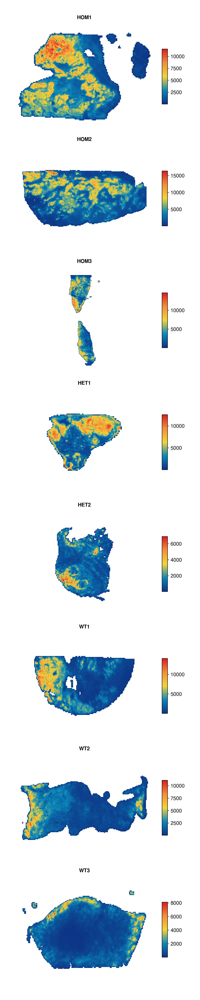

In [111]:
plot_totalcounts_subplots(nrows=8, ncols=1)

## Cell types

### Scatterplots

In [55]:
def plot_color_channels_subplots(hexdfs, colors, channels, style="default", 
                                 replace=False, hex=[], title="", filter=None, 
                                 nrows=2, ncols=4, factor=2, bin_size=bin_size, save=False):
    plt.subplots(nrows, ncols, figsize=(2.5*factor*ncols,2*factor*nrows), dpi=300)
    for i,d in enumerate(datalist):
        basedf = alldfs[i].copy()
        df = hexdfs[i].copy()
        if replace:
            df.replace(hex[0],hex[1], inplace=True) 
        plt.subplot(nrows,ncols,i+1)
        #plt.figure(figsize=(2.5*factor,2*factor), dpi=300)
        r1, xlim, ylim, pad, addpadx, addpady, dot_size = adjust(df, d, factor=factor, bin_size=bin_size, subplot=True)
            
        if r1 > 1: # redefine ylim bc it's too fat
            ylim = (max(basedf["y"])+pad+addpady+1000, min(basedf["y"])-pad-addpady-1000)
        else: # r1 < 0, redefine xlim bc it's too tall
            xlim = (min(basedf["x"])-pad-addpadx, max(basedf["x"])+pad+addpadx)

        base = sns.scatterplot(data=basedf, x="x", y="y", linewidth=0, s=dot_size, marker="s", color="#f3f0f0")
        p = sns.scatterplot(data=df, x="x", y="y", hue=df.index.astype("category"), 
                            palette=sns.color_palette(df["hex"]),
                            linewidth=0, s=dot_size, marker="s", legend=False)
        if isinstance(xlim, tuple):
            plt.xlim(xlim)
            plt.ylim(max(basedf["y"])+addpady, min(basedf["y"])-addpady)
        elif isinstance(ylim, tuple):
            plt.xlim(min(basedf["x"])-addpadx, max(basedf["x"])+addpadx)
            plt.ylim(ylim)
        plt.xlabel("")
        plt.ylabel("")
        plt.xticks([])
        plt.yticks([])
        p.spines[['left', 'bottom']].set_visible(False)
        plt.title("{}".format(d), weight="bold", fontsize=12)
    plt.suptitle("{}".format(title), weight="bold", fontsize=15)
        
    if save:
        if (filter == "mutation") or (filter == "neoantigen"):
            print(filter)
            plt.savefig(f"/stereoseq/all_samples/images/paper1/Supp.bin{bin_size}.scatter.celltypes.{colors}.{d}.{filter}.pdf", format="pdf", dpi=300)
        elif colors == "RGB":
            plt.savefig(f"/stereoseq/all_samples/images/paper1/1A.bin{bin_size}.scatter.celltypes.{colors}.{d}.pdf", format="pdf", dpi=300)
        elif colors == "CMYK":
            plt.savefig(f"/stereoseq/all_samples/images/paper1/3A.bin{bin_size}.scatter.celltypes.{colors}.{d}.pdf", format="pdf", dpi=300)
    plt.show()

#### Fig 1a, Cell Types

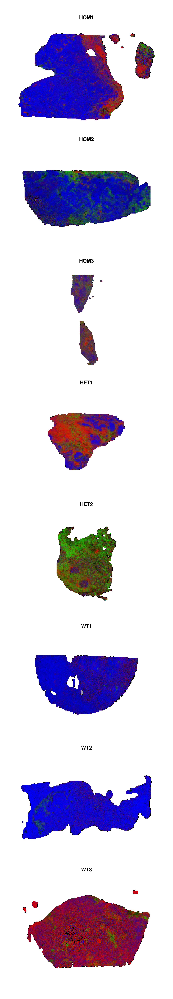

In [349]:
plot_color_channels_subplots(rgbdfs2, "RGB", rgb_channels, nrows=8, ncols=1)

#### Fig 5a

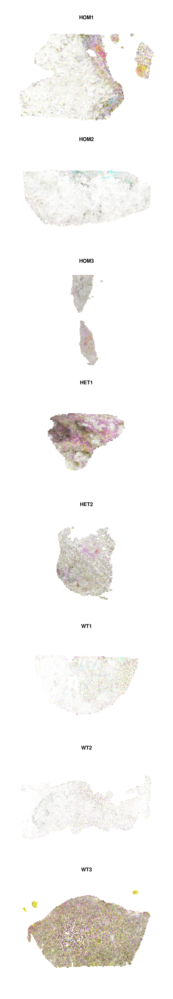

In [350]:
plot_color_channels_subplots(cmykdfs2, "CMYK", cmyk_channels, nrows=8, ncols=1)

### Clustermap

In [70]:
def plot_celltypes2_clustermap2(w, type, figsize=(6,5), cmap="vlag", save=False):
    df = w.copy()
    status = df.pop("status")
    row_lut = dict(zip(status.unique(), palette7))
    row_colors = status.map(row_lut)
    col_lut = dict(zip(subsets["main"].unique(), ["g","b","r","k"]))

    if type == "subset":
        df1 = subsets.filter(["subset","minor","major","main"]).drop_duplicates("subset")
        df1.index = df1["subset"]
        df1 = df1.drop(columns="subset")
        col_colors = df1.main.map(col_lut)
    elif type == "minor":
        df1 = subsets.filter(["minor","major","main"]).drop_duplicates("minor")
        df1.index = df1.minor
        df1 = df1.drop(columns="minor")
        col_colors = df1.main.map(col_lut)
    elif type == "major":
        df1 = subsets.filter(["major","main"]).drop_duplicates("major")
        df1.index = df1.major
        df1 = df1.drop(columns="major")
        col_colors = df1.main.map(col_lut)
    elif type == "main":
        col_lut = dict(zip(subsets[type].unique(), ["r","g","b","k"]))
        col_colors = pd.Series(df.columns, index=df.columns).map(col_lut)

    # 1. Row clustering (cluster samples)
    corr_rows = np.corrcoef(df)               # Pearson correlation
    dist_rows = 1 - corr_rows                # 1 – correlation
    dist_rows_cond = squareform(dist_rows, checks=False)
    row_linkage = linkage(dist_rows_cond, method='average')
    
    # 2. Column clustering (cluster cell types)
    corr_cols = np.corrcoef(df.T)
    dist_cols = 1 - corr_cols
    dist_cols_cond = squareform(dist_cols, checks=False)
    col_linkage = linkage(dist_cols_cond, method='average')
    
    # 3. Clustermap
    g = sns.clustermap(df, 
                       row_linkage=row_linkage,
                       col_linkage=col_linkage,
                       cmap=cmap, 
                       standard_scale=1, #z_score=1,
                       row_colors=row_colors, 
                       col_colors=col_colors,
                       dendrogram_ratio=(.15, .2),
                       cbar_pos=(1.05, .2, .03, .2), cbar_kws={"label":"score"},
                       linewidths=0.5,
                       #vmin=0, vmax=1,
                       figsize=figsize)
    from matplotlib.patches import Patch
    handles1 = [Patch(facecolor=row_lut[name]) for name in row_lut]
    plt.legend(handles1, row_lut, title="A3B status", title_fontproperties={"weight":"bold"},
               bbox_to_anchor=(1.22, .7), bbox_transform=plt.gcf().transFigure, loc='upper right')

    if save:
        g.figure.savefig(f"/stereoseq/all_samples/images/thesis/bin{bin_size}.clustermap.celltypes.{type}.png", format="png", dpi=600)

#### Fig 1b

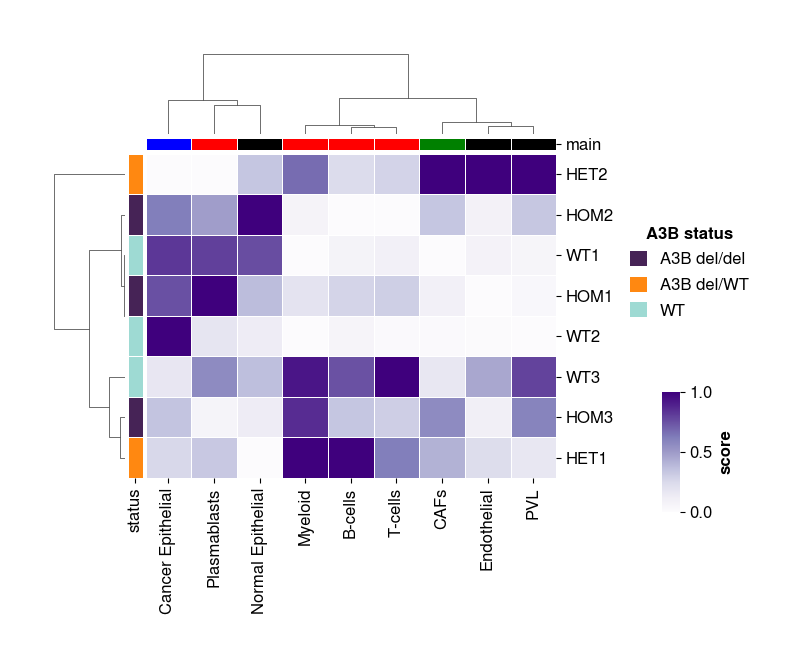

In [351]:
plot_celltypes2_clustermap2(weightsmajoravg2, "major", figsize=(6,6), cmap="Purples") 

#### Supp Fig 1b

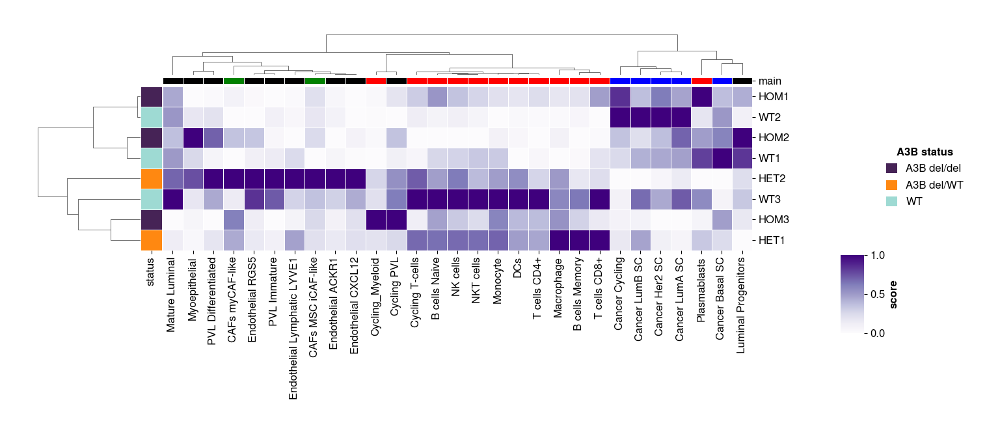

In [352]:
plot_celltypes2_clustermap2(weightsminoravg2, "minor", figsize=(12,6), cmap="Purples") 

In [72]:
def plot_celltypes2_immune_clustermap2(w, type, figsize=(6,5), cmap="vlag", save=False):
    #df = weightsavg.copy()
    #fig, ax = plt.subplots()
    df = w.copy()
    status = df.pop("status")
    row_lut = dict(zip(status.unique(), palette7))
    row_colors = status.map(row_lut)
    clus = pd.Series(["homogeneous","homogeneous","heterogeneous","heterogeneous","heterogeneous","homogeneous","homogeneous","heterogeneous"],
         index=datalist)
    clus.name = "clus"
    row_lut2 = dict(zip(["homogeneous","heterogeneous"], ["#9EE493","#E16F7C"]))
    row_colors2 = clus.map(row_lut2)
    
    col_lut = dict(zip(subsets_immune_caf.major.unique(), ["green","magenta","black","cyan","yellow"]))

    if type == "subset":
        df = df.filter(subsets_immune_caf["name"].unique())
        df1 = subsets_immune_caf.filter(["name","minor","major","main","immuno"]).drop_duplicates("name")
        df1.index = df1["name"]
        df1 = df1.drop(columns="name")
        col_colors = df1.major.map(col_lut)
        # col_colors2 = df1.immuno.map(col_lut2)
    elif type == "minor":
        df1 = subsets_immune_caf.filter(["minor","major","main"]).drop_duplicates("minor")
        df1.index = df1.minor
        df1 = df1.drop(columns="minor")
        col_colors = df1.major.map(col_lut)
    elif type == "major":
        df1 = subsets_immune_caf.filter(["major","main"]).drop_duplicates("major")
        df1.index = df1.major
        df1 = df1.drop(columns="major")
        col_colors = df1.major.map(col_lut)
    elif type == "main":
        col_lut = dict(zip(subsets_immune_caf[type].unique(), ["magenta","key","cyan","yellow"]))
        col_colors = pd.Series(df.columns, index=df.columns).map(col_lut)

    if type != "subset":
        df = df.filter(subsets_immune_caf[type].unique())
    
    # 1. Row clustering (cluster samples)
    corr_rows = np.corrcoef(df)               # Pearson correlation
    dist_rows = 1 - corr_rows                # 1 – correlation
    dist_rows_cond = squareform(dist_rows, checks=False)
    row_linkage = linkage(dist_rows_cond, method='average')
    
    # 2. Column clustering (cluster cell types)
    corr_cols = np.corrcoef(df.T)
    dist_cols = 1 - corr_cols
    dist_cols_cond = squareform(dist_cols, checks=False)
    col_linkage = linkage(dist_cols_cond, method='average')
    
    # 3. Clustermap
    g = sns.clustermap(df, 
                       # row_linkage=row_linkage,
                       # col_linkage=col_linkage,
                       cmap=cmap, 
                       standard_scale=1, #z_score=1,
                       row_colors=[row_colors, row_colors2], 
                       col_colors=col_colors,
                       dendrogram_ratio=(.05, .25),
                       cbar_pos=(1.05, .2, .03, .2), cbar_kws={"label":"correlation distance"},
                       linewidths=0.5,
                       #vmin=0, vmax=1,
                       figsize=figsize)
    from matplotlib.patches import Patch
    handles1 = [Patch(facecolor=row_lut[name]) for name in row_lut]
    plt.legend(handles1, row_lut, title="A3B status", title_fontproperties={"weight":"bold"},
               bbox_to_anchor=(1.22, .7), bbox_transform=plt.gcf().transFigure, loc='upper right')

    if save:
        g.figure.savefig(f"/stereoseq/all_samples/images/thesis/bin{bin_size}.clustermap.celltypes.{type}.immune.png", format="png", dpi=600)

In [73]:
subsets_immune_caf = subsets[(subsets["main"]=="Immune") | (subsets["main"]=="CAF")]
subsets_immune_caf.major.unique()

array(['CAFs', 'B-cells', 'Myeloid', 'Plasmablasts', 'T-cells'],
      dtype=object)

#### Fig 5b

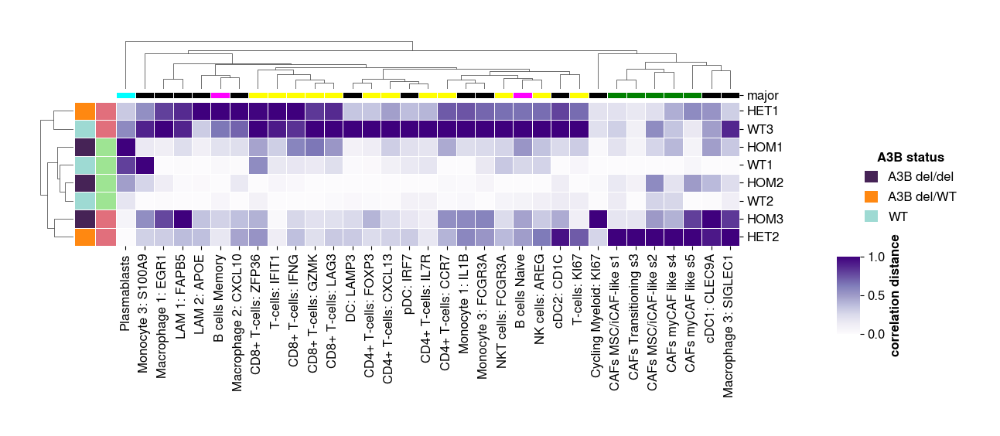

In [353]:
plot_celltypes2_immune_clustermap2(weightsavg2, "subset", figsize=(10,5), cmap="Purples")

### Barplots

#### Supp Fig 1a

Text(0, 0.5, 'cell type score')

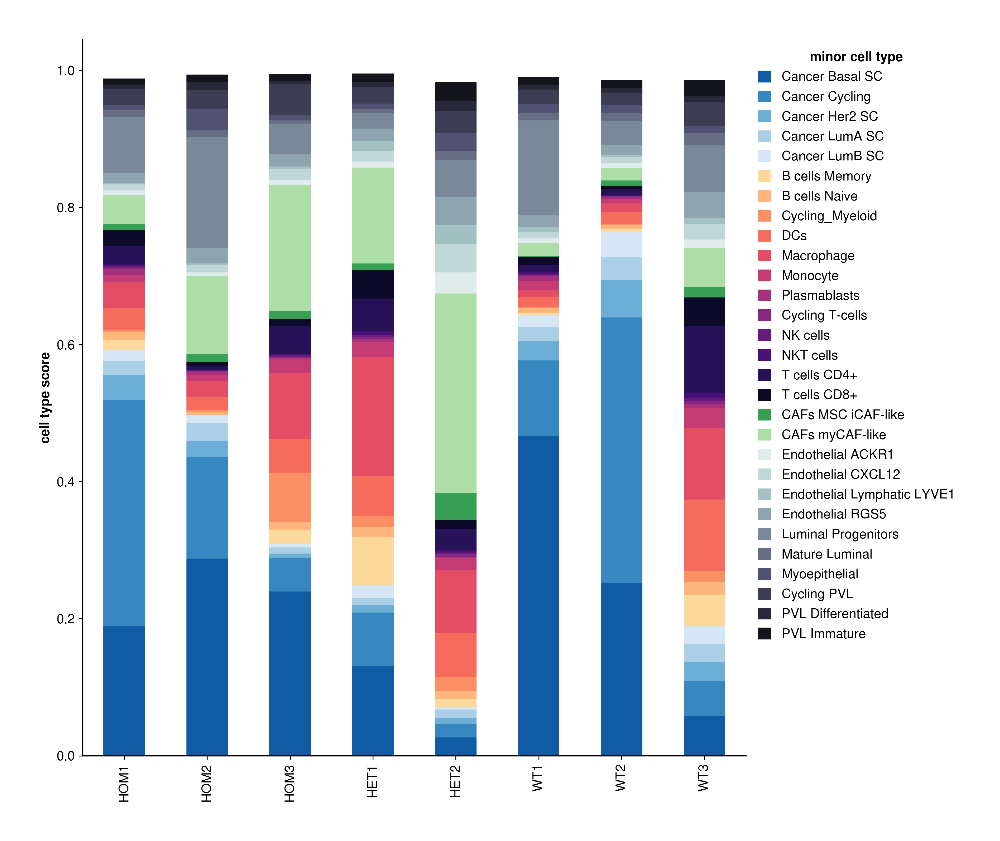

In [354]:
mains = ["Cancer","Immune","CAF","Others"]

n_colors = []
subs = []
for ct,color in zip(mains,["Blues","magma","Greens","bone"]):
    n = len(subsets[subsets["main"]==ct].minor.unique())
    n_colors.extend(sns.color_palette(f"{color}_r", n_colors=n)[:])
    subs.extend(subsets[subsets["main"]==ct].minor.unique())

barrrr = pd.DataFrame(index=subs)
for i,d in enumerate(datalist):
    barrrr[d] = weightsminor2[i].filter(subs).mean().to_list()

fig, ax = plt.subplots(figsize=(12,10), dpi=300)
barrrr.T.plot(kind="bar", stacked=True, color=n_colors, ax=ax)
plt.legend(bbox_to_anchor=(1,1), title="minor cell type", title_fontproperties={"weight":"bold"})#.remove()
plt.ylabel("cell type score")

# plt.savefig("/stereoseq/all_samples/images/paper1/celltypes.minor.bar.pdf", format="pdf", dpi=300)

In [94]:
def plot_celltype_bar(cell, cat, weights, res="subset", pad=False, palette=colormaps["glasbey_hv"], save=False):
    barrrr = pd.DataFrame(index=subsets[subsets[cat]==cell][res].unique())
    for i,d in enumerate(datalist):
        barrrr[d] = weights[i].filter(subsets[subsets[cat]==cell][res].unique()).mean().to_list()
    
    fig, ax = plt.subplots(figsize=(8,5), dpi=300)
    if pad:
        tot = 1-barrrr.sum()
        tot.name = "tot"
        barrrr = barrrr.append(tot) ### total to buff
        color = palette[:len(subsets[subsets[cat]==cell][res].unique())+1]
        color.insert(-1, "#ffffff")
    else:
        color = palette
    barrrr.T.plot(kind="bar", stacked=True, color=color, ax=ax)
    plt.legend(title="{} subtypes".format(cell),
                 loc="best", bbox_to_anchor=(1,1), markerscale=2, #draggable=True,
                   fancybox=False, edgecolor="w", title_fontproperties={'weight':'bold'})
    plt.xlabel("sample")
    plt.xticks(rotation=45)
    plt.ylabel("Cell type score")
    # plt.show()
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/5C.{cell}.{cat}.bar.sample.pdf", format="pdf", dpi=300)

#### Supp Fig 10a

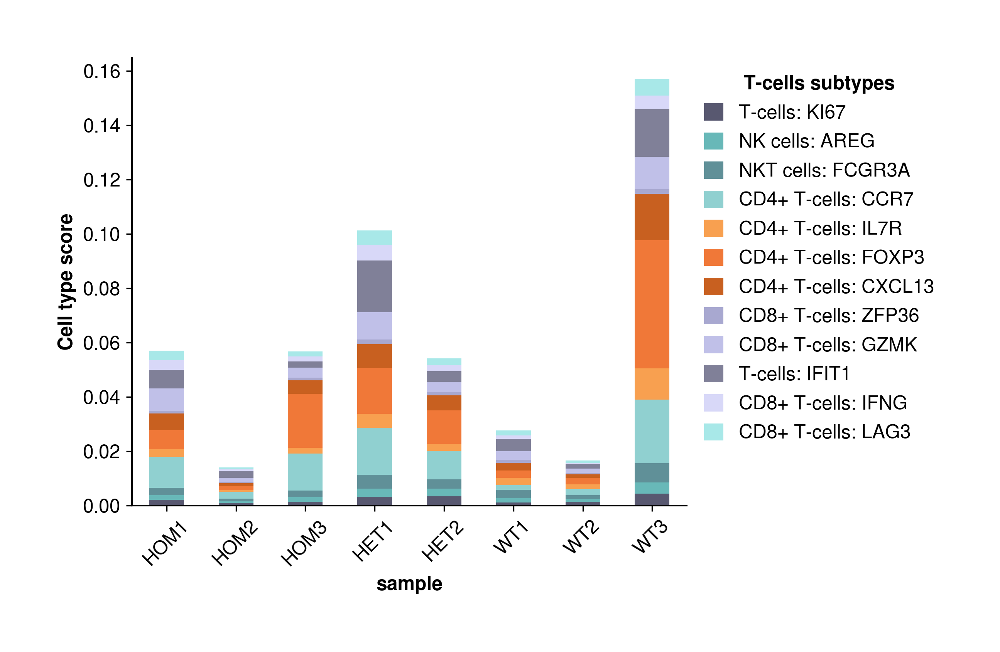

In [355]:
plot_celltype_bar("T-cells", "major", weights2, res="name", palette=palette4)

In [104]:
def plot_mean_celltype_bar(cell, dfs, cat1="minor", cat2="subset", group="status", palette=colormaps["glasbey_hv"], save=False):
    fig, ax = plt.subplots(figsize=(6,4)) #, dpi=300
    pd.concat(dfs).groupby(by=group, sort=False).mean().filter(subsets[subsets[cat1]==cell][cat2].unique()).plot(
        kind="bar", stacked=True, color=palette, ax=ax)
    ax.legend(title="{} subtypes".format(cell),
                 loc="best", bbox_to_anchor=(1.6,.5), 
              markerscale=2, #draggable=True,
                   fancybox=False, edgecolor="w", title_fontproperties={'weight':'bold'})
    ax.set_xlabel("")
    ax.set_ylabel("Cell type score")
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/5C.{cell}.{cat1}.bar.{group}.pdf", format="pdf", dpi=300)

#### Fig 5c

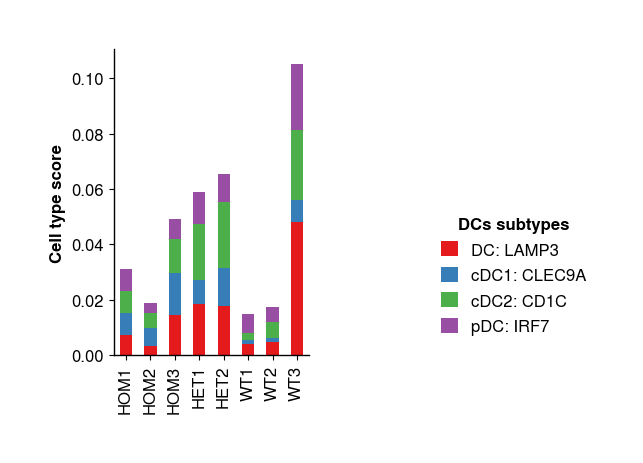

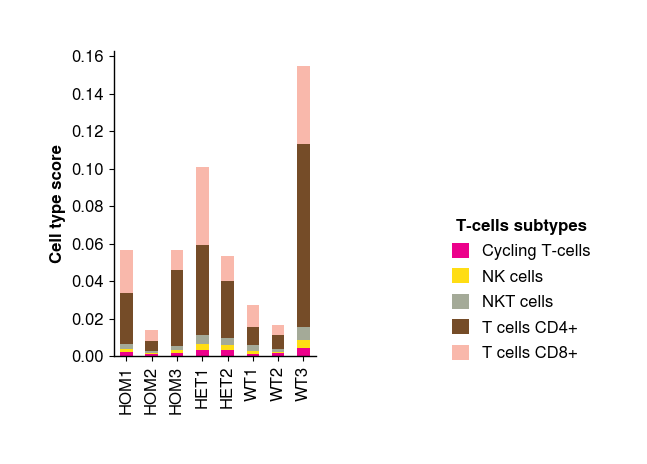

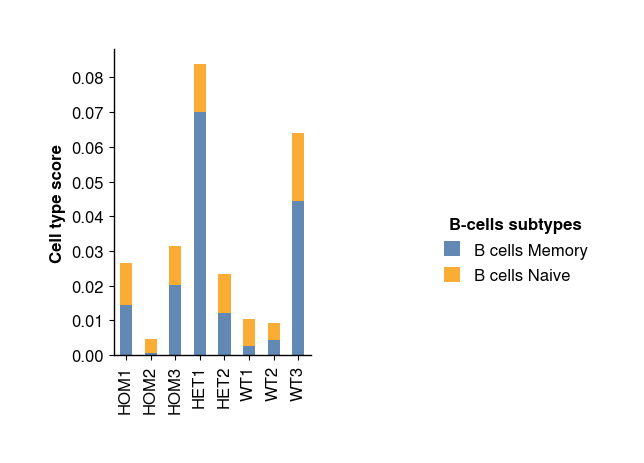

In [356]:
plot_mean_celltype_bar("DCs", weights2, cat2="name", group="batch", palette=sns.color_palette("Set1"))
plot_mean_celltype_bar("T-cells", weightsminor2, cat1="major", cat2="minor", group="batch", palette=sns.color_palette(palette8))
plot_mean_celltype_bar("B-cells", weightsminor2, cat1="major", group="batch", palette=sns.color_palette(["#6288B4","#FBAC34"]))

#### Supp Fig 10b

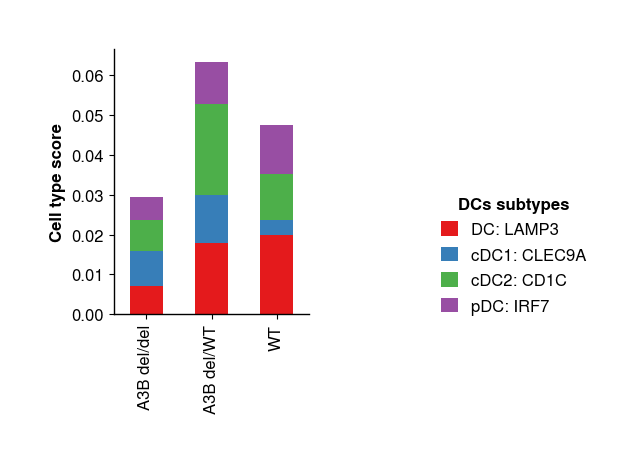

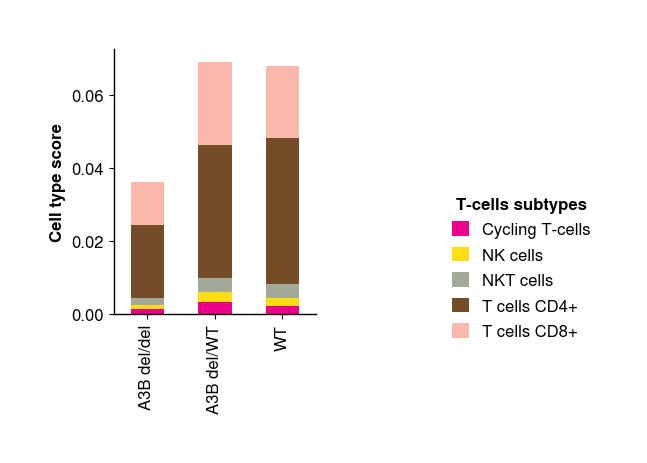

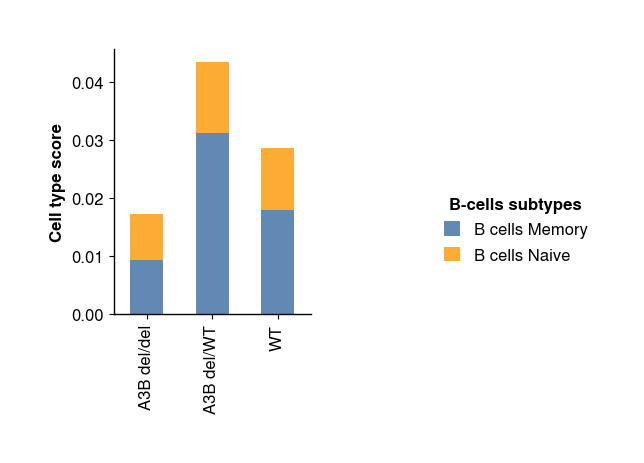

In [357]:
plot_mean_celltype_bar("DCs", weights2, cat2="name", palette=sns.color_palette("Set1"))
plot_mean_celltype_bar("T-cells", weightsminor2, cat1="major", cat2="minor", palette=sns.color_palette(palette8))
plot_mean_celltype_bar("B-cells", weightsminor2, cat1="major", palette=sns.color_palette(["#6288B4","#FBAC34"]))

In [84]:
def plot_zoom_scatter_celltypes_bar(df1, df2, cat="subset", plot=True, s=50, figsize=(12,7), width_ratios=[1,4], title="", save=False): # (12,7)
    df2["x"] = df1["x"].to_list()
    df2["y"] = df1["y"].to_list()
    df1_zoom = zoom_df(df1)
    df2_zoom = zoom_df(df2)
    filter = subsets[cat]
    if plot:
        fig, ax = plt.subplots(1,2, figsize=figsize, width_ratios=width_ratios, dpi=300)
        g = sns.scatterplot(data=df2_zoom, x="x", y="y", #linewidth=0,
                        hue=df2_zoom.index.astype("category"), 
                            palette=sns.color_palette(df2_zoom["hex"]),
                        s=120, marker="s", legend=False,
                        ax=ax[0])
        ax[0].invert_yaxis()
        ax[0].set_xlabel("")
        ax[0].set_ylabel("")
        g.spines[['top', 'right']].set_visible(True)

        df1_zoom.filter(filter.unique()).mean().sort_values().to_frame().tail(35).plot(kind="bar", color="coral", ax=ax[1]) #.to_list()
        plt.axhline(df1_zoom.filter(filter.unique()).mean().mean())
    else:
        fig, ax = plt.subplots(1,1,figsize=figsize, dpi=300)
        df1_zoom.filter(filter.unique()).mean().sort_values().to_frame().tail(20).plot(kind="barh", color="coral", ax=ax) #.to_list()
        plt.axvline(df1_zoom.filter(filter.unique()).mean().mean())
    
    plt.legend(bbox_to_anchor=(1,1)).remove()
    plt.xlabel("score")

    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/Supp.8.{title}.zoom.scatter.composition.pdf", format="pdf", dpi=300)

#### Supp Fig 9a

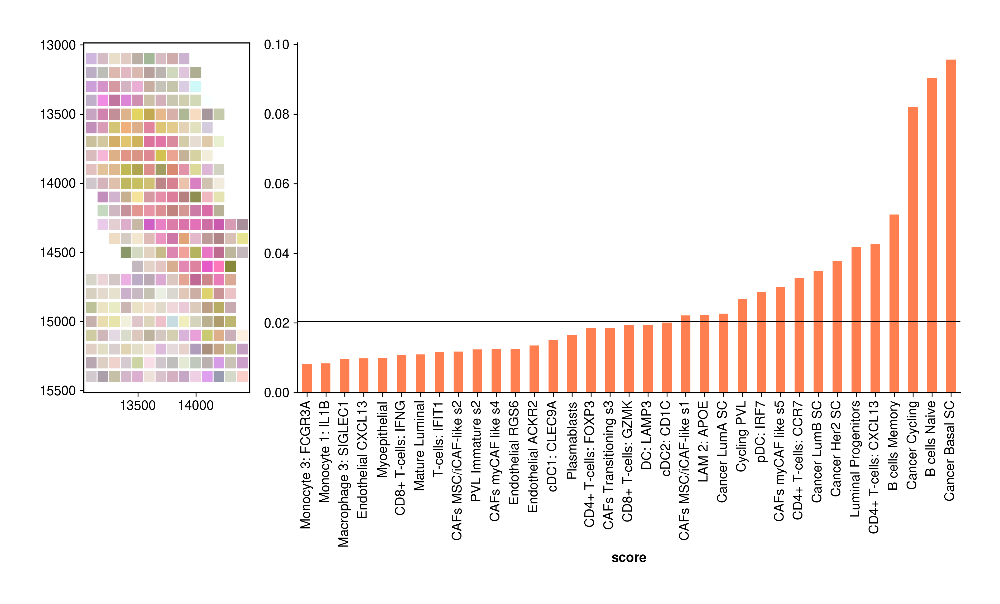

In [358]:
def zoom_df(df):
    return df[(df["x"]>13000) & (df["x"]<14500) & (df["y"]<15500) & (df["y"]>13000)]
plot_zoom_scatter_celltypes_bar(weights2[0], cmykdfs2[0], cat="name", title="HOM1_TLS1")

#### Supp Fig 9b

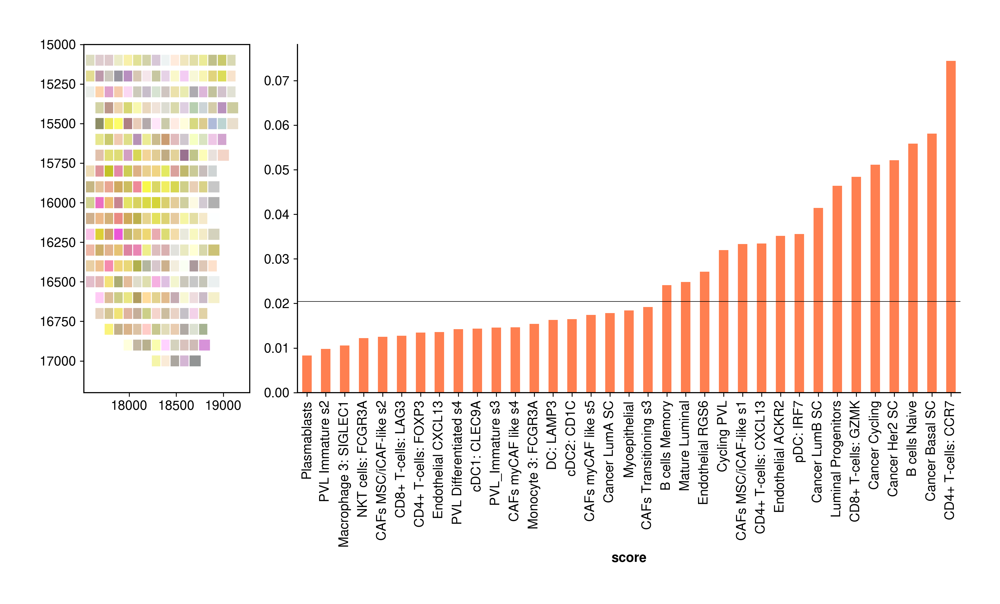

In [359]:
def zoom_df(df):
    return df[(df["x"]>17500) & (df["y"]<17500) & (df["y"]>15000)]
plot_zoom_scatter_celltypes_bar(weights2[0], cmykdfs2[0], cat="name", title="HOM1_TLS2")

#### Supp Fig 11d

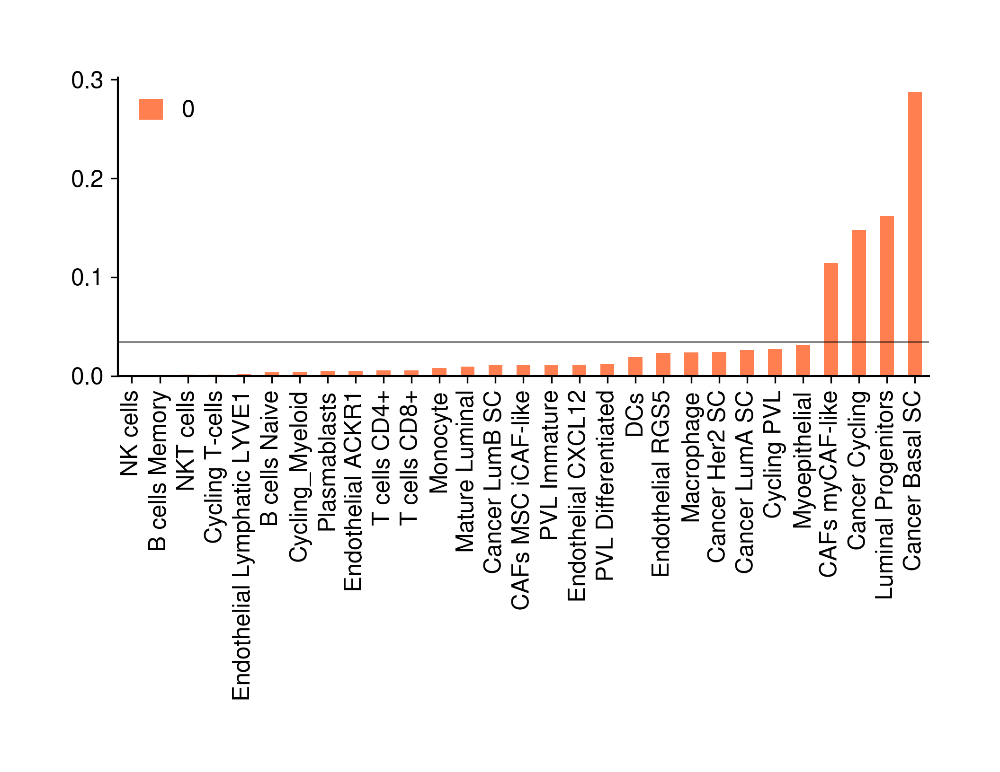

In [360]:
fig, ax = plt.subplots(dpi=300)
df = weightsminor2[1].copy()
df.filter(subsets.minor.unique()).mean().sort_values().to_frame().tail(35).plot(kind="bar", color="coral", ax=ax) #.to_list()
plt.axhline(df.filter(subsets.minor.unique()).mean().mean())
# plt.savefig("/stereoseq/all_samples/images/paper1/Supp.8.HOM2.minor.composition.pdf", format="pdf", dpi=300)

### Correlation

In [345]:
gsva_scores = pd.read_csv("/stereoseq/all_samples/rnaseq/gsva.scores.csv", index_col=0).T
gsva_scores.index = datalist

In [346]:
def plot_reg_ssgsea_celltype(cell1, cell2, weightsavg, color="red", save=True):
    plt.figure(figsize=(3,3))
    sns.regplot(x=gsva_scores[cell1], y=weightsavg[cell2], color=color)
    p = sc.stats.pearsonr(gsva_scores[cell1], weightsavg[cell2])
    ci = p.confidence_interval(0.95)
    plt.title(f'{cell2}, r={p.statistic:.2f}')
    plt.xlabel("ssGSEA")
    plt.ylabel("RCTD result")

    if save:
        plt.savefig("/stereoseq/all_samples/images/paper1/{}.correlation.RCTD.ssGSEA.pdf".format(cell1), format="pdf", dpi=300)
    return ci

#### Supp Fig 1c

ConfidenceInterval(low=0.10873842902093864, high=0.9528830991055797)

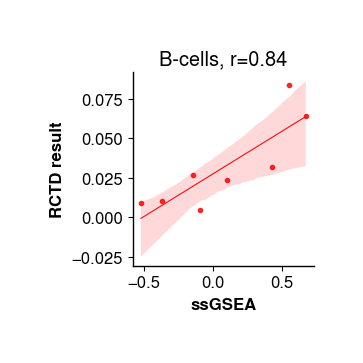

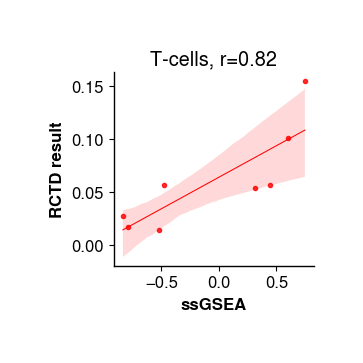

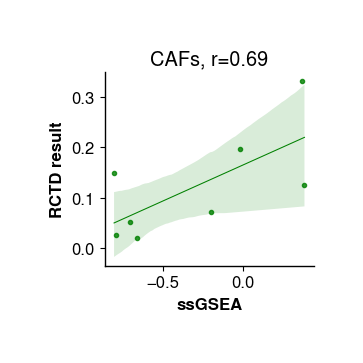

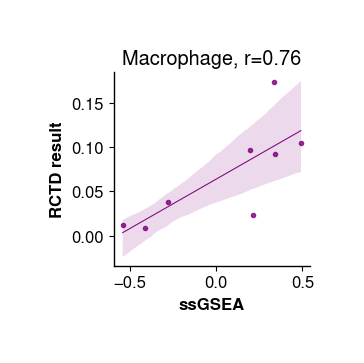

In [361]:
plot_reg_ssgsea_celltype("B_cells", "B-cells", weightsmajoravg2)
plot_reg_ssgsea_celltype("T_cells", "T-cells", weightsmajoravg2)
plot_reg_ssgsea_celltype("CAF", "CAFs", weightsmajoravg2, color="green")
plot_reg_ssgsea_celltype("Macrophages", "Macrophage", weightsminoravg2, color="purple")

## Gene expression

### Scatterplots

In [115]:
## function to plot cell type scatter w/ colour choice
def plot_scatter_gene_subplots(gene, palette="magma_r", dark=False, cbar=False, factor=2, 
                               nrows=4, ncols=2, save=False):
    if cbar:
        width = 3
    else:
        width = 2.5
    plt.subplots(nrows, ncols, figsize=(width*factor*ncols,2*factor*nrows), dpi=300)
    
    for i,d in enumerate(datalist):
        plt.subplot(nrows,ncols,i+1)
        #plt.figure(figsize=(2.5*factor,2*factor), dpi=300)
        df = alldfs[i]

        r1, xlim, ylim, pad, addpadx, addpady, dot_size = adjust(df, d, factor=factor, bin_size=bin_size, subplot=True)
        if r1 > 1: # redefine ylim bc it's too fat
            ylim = (max(df["y"])+pad+addpady+1000, min(df["y"])-pad-addpady-1000)
        else: # r1 < 0, redefine xlim bc it's too tall
            xlim = (min(df["x"])-pad-addpadx, max(df["x"])+pad+addpadx)

        if isinstance(gene, str):
            try: df["gene"] = allcounts[i][gene].to_list()
            except KeyError:
                print("gene not found")
        else:
            try: df["gene"] = allcounts[i].filter(gene).sum(axis=1).to_list()
            except KeyError:
                print("gene not found")
            
        #base = sns.scatterplot(data=df, x="x", y="y", color="#f3f0f0", linewidth=0, s=dot_size, marker="s")
        g = sns.scatterplot(data=df, x="x", y="y", hue="gene", hue_norm=(0,10),
                            #hue_norm=(0,10*len(gene)), 
                            legend=False, linewidth=0, s=dot_size, marker="s", palette=palette)

        if isinstance(xlim, tuple):
            plt.xlim(xlim)
            plt.ylim(max(df["y"])+addpady, min(df["y"])-addpady)
        elif isinstance(ylim, tuple):
            plt.xlim(min(df["x"])-addpadx, max(df["x"])+addpadx)
            plt.ylim(ylim)
        plt.xlabel("")
        plt.ylabel("")
        plt.xticks([])
        plt.yticks([])
        g.spines[['left', 'bottom']].set_visible(False)
        # if dark:
        #     plt.title("{}".format(d), weight="bold", fontsize=12, color="white")
        # else:
        #     plt.title("{}".format(d), weight="bold", fontsize=12, color="black")
        if cbar:
            #norm = plt.Normalize(0, 10*len(gene))
            norm = plt.Normalize(0, 10)
            sm = plt.cm.ScalarMappable(cmap=palette, norm=norm)
            sm.set_array([])
            #p.get_legend().remove()
            cb = g.figure.colorbar(sm, shrink=.5, aspect=12) # location="bottom"
            #cb.ax.tick_params(color="white")
    
    plt.suptitle("{}".format(gene), weight="bold", style="italic", fontsize=15, color="black")
    # plt.subplots_adjust(wspace=-10)
    plt.tight_layout()
    # plt.show()
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/bin{bin_size}.{gene}.scatter.subplots.pdf", format="pdf", dpi=300)

#### Fig 2a

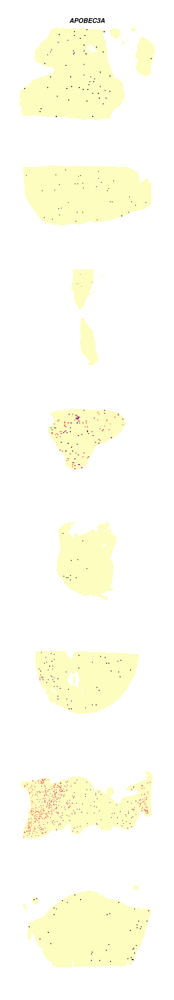

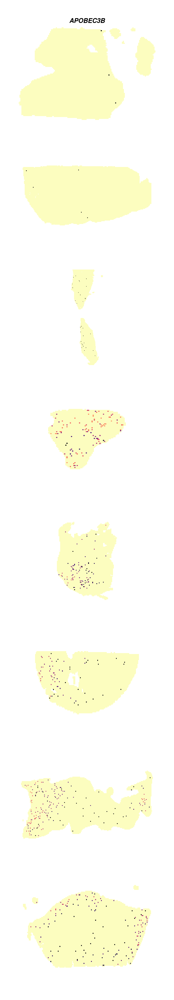

In [362]:
for gene in ["APOBEC3A","APOBEC3B"]:
    plot_scatter_gene_subplots(gene, cbar=False, nrows=8, ncols=1)

#### Supp Fig 2

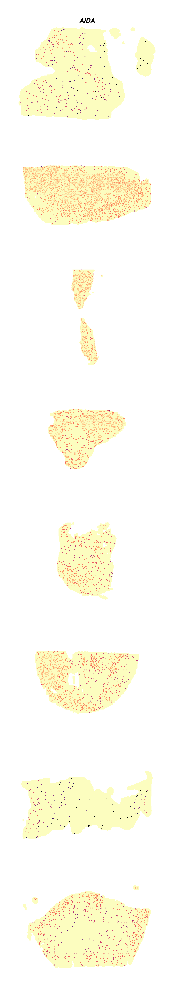

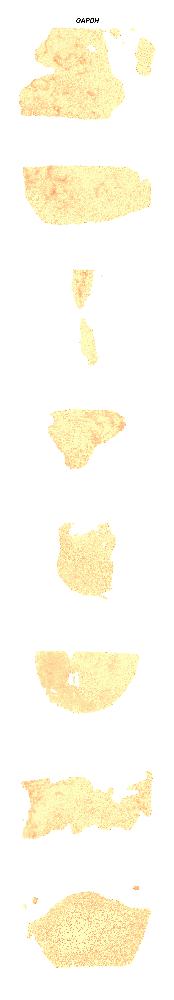

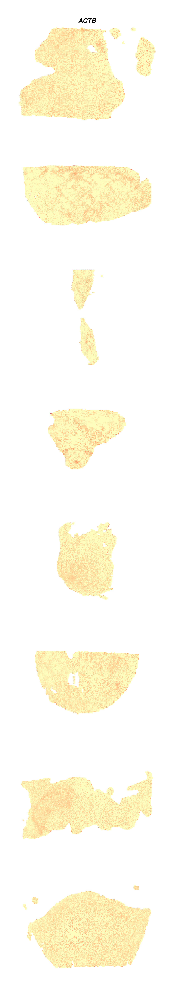

In [363]:
for gene in ["AIDA","GAPDH","ACTB"]:
    plot_scatter_gene_subplots(gene, cbar=False, nrows=8, ncols=1)

#### Supp Fig 11b,c

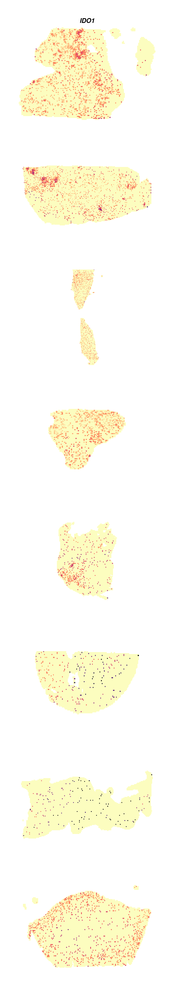

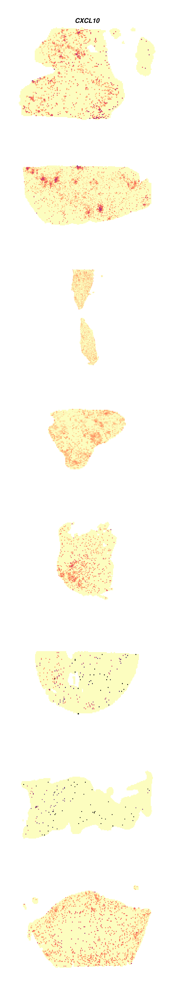

In [364]:
for gene in ["IDO1","CXCL10"]:
    plot_scatter_gene_subplots(gene, cbar=False, nrows=8, ncols=1)

### Barplots

In [138]:
def plot_bar_gene_custom_data_subplots(genes, din, group="batch", filter=False, figsize=(4,4), annot=False, title="", palette="husl", save=False):
    # plt.subplots(1,len(genes),figsize=figsize, sharey=True, dpi=300)
    dfs = []
    labels = []
    for i,gene in enumerate(genes):
        g = din[gene]
        if filter:
            # din[din[gene]<0][gene] = 0
            # print(din)
            g[g<0] = 0
        df = pd.DataFrame(index=din.index)
        df["score"] = g.to_list()
        df["gene"] = gene
        df[group] = din[group].to_list()
        # print(df.head(1))
        dfs.append(df)

        if group == "status":
            df1 = df[df.status=="A3B del/del"]
            df2 = df[df.status=="A3B del/WT"]
            df3 = df[df.status=="WT"]
            kk = sc.stats.kruskal(df1["score"],df2["score"],df3["score"])
        # print(gene, kk, significance_stars(kk.pvalue))
        labels.append(significance_stars(kk.pvalue))
        
    plt.figure(figsize=figsize, dpi=300)
    ax = sns.barplot(data=pd.concat(dfs), x="gene", y="score", hue=group, hue_order=["A3B del/del", "A3B del/WT", "WT"],
                fill=True, linewidth=2, #width=.5,
                # dodge=True, gap=1, 
                palette=palette)
    # plt.xticks(rotation=45)
    plt.xticks(style="italic", rotation=0)
    plt.legend(#title="A3Bdel status", title_fontproperties={"weight":"bold"},
                   bbox_to_anchor=(1.02,.9), bbox_transform=plt.gcf().transFigure, loc='upper right')

    if annot:
        ax.bar_label(ax.containers[0], labels=labels, label_type='edge', padding=20, size=10)
    plt.title(title)

    plt.show()
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/genes.{title}.bar.pdf", format="pdf", dpi=300)
    
    return df

#### Fig 5d

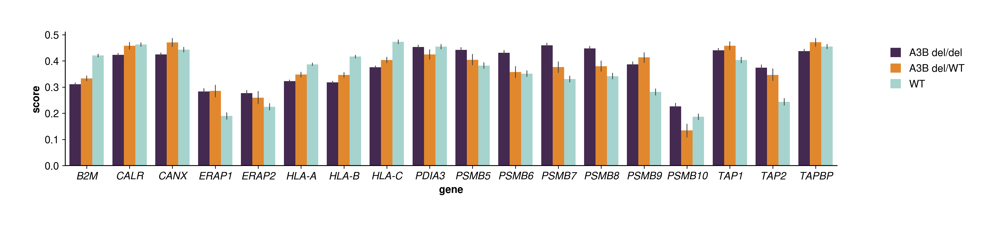

In [365]:
df = pd.concat([pd.concat(alldfs), pd.concat([allcountscombined.filter(apm_lit1)], axis=1)], axis=1)
df["Cancer Epithelial"] = pd.concat(weightsmajor2)["Cancer Epithelial"]
df1 = df[df["Cancer Epithelial"]>0.01]
_=plot_bar_gene_custom_data_subplots(apm_lit1, df1, filter=True, group="status", 
                                    # title="apm genes expressed in the cancer epithelium",
                                    figsize=(15,3), annot=False, palette=palette7)

### Boxplots

In [212]:
def plot_genes_box(genes, hue="carrier_status", count="norm", figsize=(10,3), filter=True, adjust=None, stat=False, palette=["#CCB9D3","#FAECCF"], save=False):
    cc = []
    if count == "norm":
        dfs = allcounts
    elif count == "raw":
        dfs = rawcounts
    ccs = []
    for gene in genes:
        semic = []
        for i,d in enumerate(datalist):
            df = dfs[i].filter([gene])
            df["sample"] = d
            df["status"] = status[i]
            df["carrier_status"] = carrier_status[i]
            df["gene"] = gene
            df["score"] = df[gene] #min_max_scaler(np.log(df[gene]+1))
            df.drop(gene, axis=1, inplace=True)
            #mu = np.log(df["normlog%s"%muttype]+1) #df["normlog%s"%muttype].median() log+1 #.00000001
            #df[muttype] = min_max_scaler(mu)
            semic.append(df)
        cc = pd.concat(semic, axis=0)
        if filter:
            cc = cc[cc["score"]>0]
        ccs.append(cc)
    ccss = pd.concat(ccs)
    #ccs_melt = ccss.melt(id_vars=["sample","status","carrier_status"], value_vars=genes, var_name="gene", value_name="expression_score")
    plt.figure(figsize=figsize, dpi=300) #figsize=(8,4)
    sns.boxplot(ccss, x="gene", y="score", hue=hue, palette=palette, fliersize=1) #palette="PRGn"
    plt.legend(#title="A3Bdel status", title_fontproperties={"weight":"bold"},
                   bbox_to_anchor=(1,.9), bbox_transform=plt.gcf().transFigure, loc='upper right') #(1,.9)
    if adjust is not None:
        plt.ylim(adjust[0],adjust[1])
    plt.xlabel("gene")
    plt.xticks(style="italic")
    plt.ylabel("expression Z-score")
    if save:
        plt.savefig("/stereoseq/all_samples/images/paper1/bin{0}.{1}.genes.box.pdf".format(bin_size, genes), format="pdf", dpi=300)
    # plt.show()
    if stat:
        if hue == "carrier_status":
            df1 = ccss[ccss.carrier_status=="carrier"]
            df2 = ccss[ccss.carrier_status=="non-carrier"]
            for gene in genes:
                print(gene, len(df1), len(df1[df1.gene==gene]), len(df2), len(df2[df2.gene==gene]))
                mwu = sc.stats.mannwhitneyu(df1[df1.gene==gene]["score"],df2[df2.gene==gene]["score"])
                print(gene, mwu, significance_stars(mwu.pvalue))
                interpret_test(mwu.statistic, len(df1[df1.gene==gene]), len(df2[df2.gene==gene]), group1="carrier", group2="non-carrier")
        elif hue == "status":
            df1 = ccss[ccss.status=="A3B del/del"]
            df2 = ccss[ccss.status=="A3B del/WT"]
            df3 = ccss[ccss.status=="WT"]
            for gene in genes:
                print(gene, len(df1), len(df1[df1.gene==gene]), len(df2), len(df2[df2.gene==gene]), len(df3), len(df3[df3.gene==gene]))
                kk = sc.stats.kruskal(df1[df1.gene==gene]["score"],df2[df2.gene==gene]["score"],df3[df3.gene==gene]["score"])
                print(gene, kk, significance_stars(kk.pvalue))

#### Supp Fig 10c

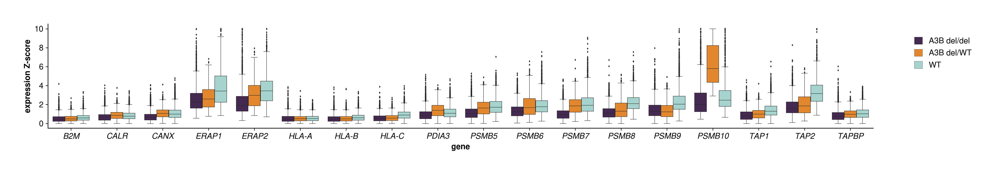

In [366]:
plot_genes_box(apm_lit1, hue="status", palette=palette7, figsize=(20,3))

### Forestplots

In [190]:
def gee_genes(genes, filter=False, filter_cell=False):
    resdfs = []
    for gene in genes:
        df = pd.concat(alldfs)
        df["gene"] = allcountscombined[gene] #
        df["group"] = pd.Categorical(df["status"], categories=["A3B del/del", "A3B del/WT", "WT"])
        if filter_cell:
            df["cell"] = pd.concat(weightsmajor2)["Cancer Epithelial"].to_list()
            df = df[df["cell"]>0.01]
        if filter:
            df = df[df["gene"]>0]
        
        cov_struct = Exchangeable()
        
        model = smf.gee(
            formula = "gene ~ group",
            groups = "batch",
            data = df,
            family = sm.families.Gaussian(),
            cov_struct = cov_struct
        )
        
        result = model.fit()
        # print("\n",gene)
        # print(result.summary())
    
        tmpdf = pd.DataFrame(index=["A3B del/del", "A3B del/WT", "WT"])
        tmpdf["gene"] = gene
        tmpdf["pvalues"] = result.pvalues.to_list()
        tmpdf["beta"] = result.params.to_list()
        tmpdf["ci_low"] = result.conf_int()[0].to_list()
        tmpdf["ci_high"] = result.conf_int()[1].to_list()
        tmpdf["data"] = "Full"
        tmpdf["n"] = df.groupby(by="status", sort=False).count()["total_counts"].to_list()
        resdfs.append(tmpdf.reset_index())
    resdf = pd.concat(resdfs)
    return resdf

In [195]:
def plot_gee_forest(resdf, genes, groups=["A3B del/WT","WT"], figsize=(8,3), annot=False, 
                    fmt="o", xlim=0, xlim_gap=.2, pval_gap=.5):
    ### forest plot
    # Genes in order of appearance (top to bottom)
    
    colors = {"A3B del/del":"#462356", "A3B del/WT":"#FF8811", "WT":"#9EDAD3"} # Blue for het, Green for WT
    # datasets = ["Full","Non-zero"]
    # markers = {'Full': 'o', 'Non-zero': 's'}
    
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    
    # Set vertical spacing per gene cluster
    y_base = np.arange(len(genes)) * 2.5  # Space genes out
    offset = {groups[0]: 0.4, groups[1]: -0.4} # Shift points slightly up/down
    
    # Plot null reference line at 0 (No effect)
    ax.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
    
    # Loop and plot points + CIs
    for idx, gene in enumerate(reversed(genes)): # Reverse to list top-to-bottom
        y_center = y_base[idx]
        
        for grp in groups:
            row = resdf[(resdf["gene"] == gene) & (resdf["index"] == grp)]
            if row.empty:
                continue
                
            y_pos = y_center + offset[grp]
            beta = row["beta"].values[0]
            ci_low = row["ci_low"].values[0]
            ci_high = row["ci_high"].values[0]
            p_val = row["pvalues"].values[0]
            n_samples = row["n"].values[0]
            
            # Error bar plot
            ax.errorbar(
                x=beta, y=y_pos,
                xerr=[[beta - ci_low], [ci_high - beta]],
                fmt=fmt, color=colors[grp], ecolor=colors[grp],
                elinewidth=2, capsize=4, markersize=7, label=grp if idx == 0 else ""
            )

            if annot:
                annotation = f"N = {n_samples}"
                ax.text(-xlim+xlim_gap, y_pos, annotation, va='center', fontsize=7, color='#2c3e50')
            
            # Annotate text: "β = X.XX (p = X.XXX)"
            p_text = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"
            annotation = f"β = {beta:+.3g} ({p_text})"
            
            # Position text to the right of the error bar
            ax.text(ci_high + pval_gap, y_pos, annotation, va='center', fontsize=8.5, color='#2c3e50')
    
    # Y-axis styling
    ax.set_yticks(y_base)
    ax.set_yticklabels(reversed(genes), fontsize=11, style="italic")
    # ax.set_title('GEE APM Spatial Gene Expression (Cancer Epithelium) across A3Bdel statuses', fontsize=12, fontweight='bold', pad=15)
    
    # Formatting limits and grid
    ax.set_xlim(-xlim,xlim) # Adjust based on your min/max Beta values
    # ax.grid(axis='x', linestyle=':', alpha=0.6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Add Legend
    # ax.legend(title='Contrast vs A3B del/del', bbox_to_anchor=(1.2,1), fontsize=8, loc='upper right')
    
    plt.tight_layout()
    plt.savefig(f"/stereoseq/all_samples/images/paper1/Fig2b_updated_gene_exp_forest_plot.pdf", dpi=300, format="pdf")
    plt.show()

#### Fig 2b

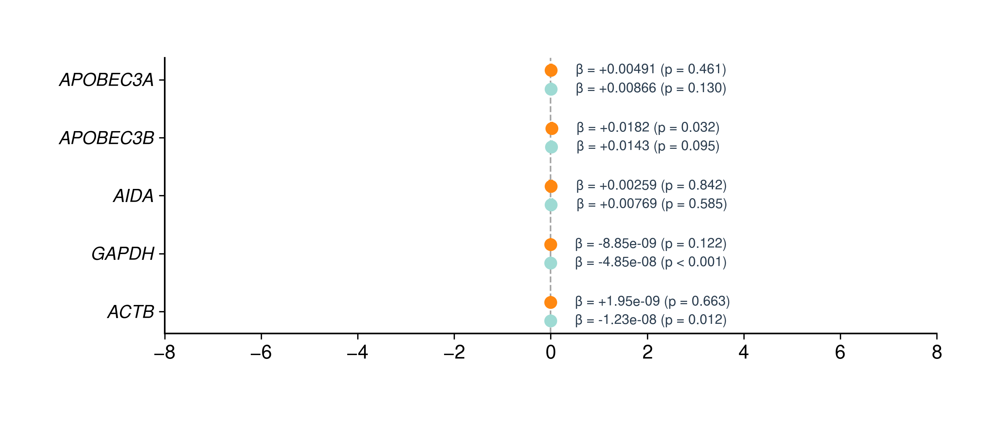

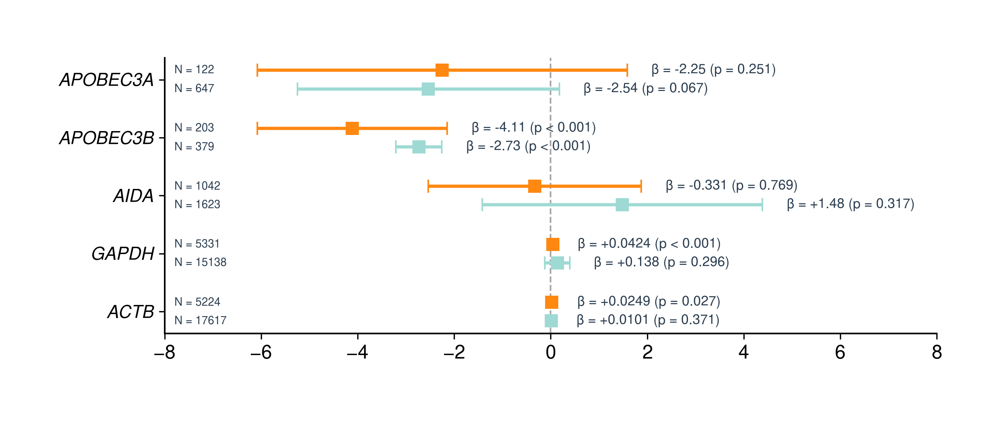

In [367]:
genes = ["APOBEC3A","APOBEC3B","AIDA","GAPDH","ACTB"]
plot_gee_forest(gee_genes(genes), genes, xlim=8)
plot_gee_forest(gee_genes(genes, filter=True), genes, annot=True, fmt="s", xlim=8)

#### Supp Fig 12a

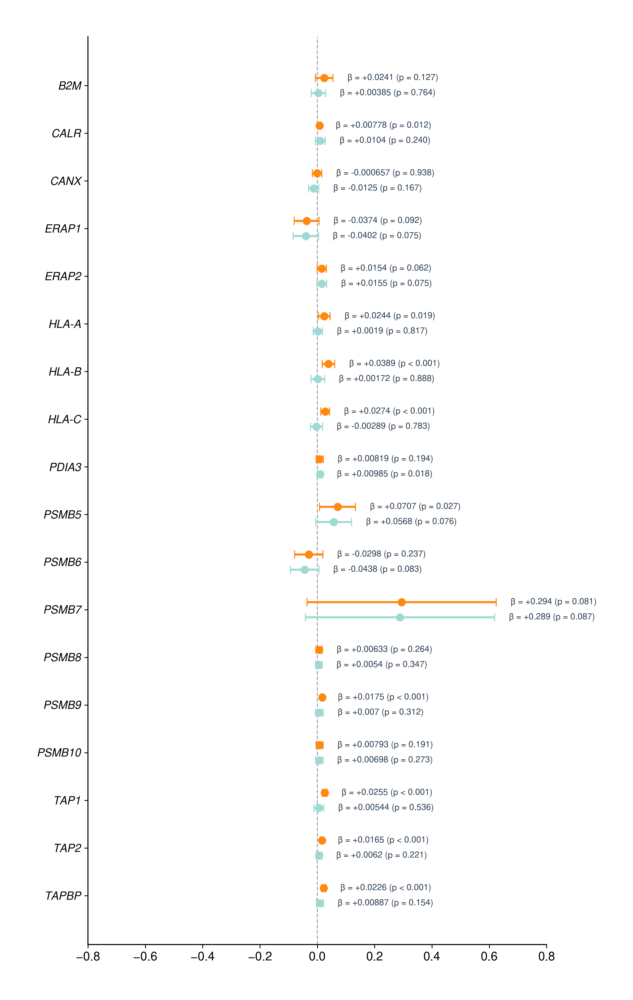

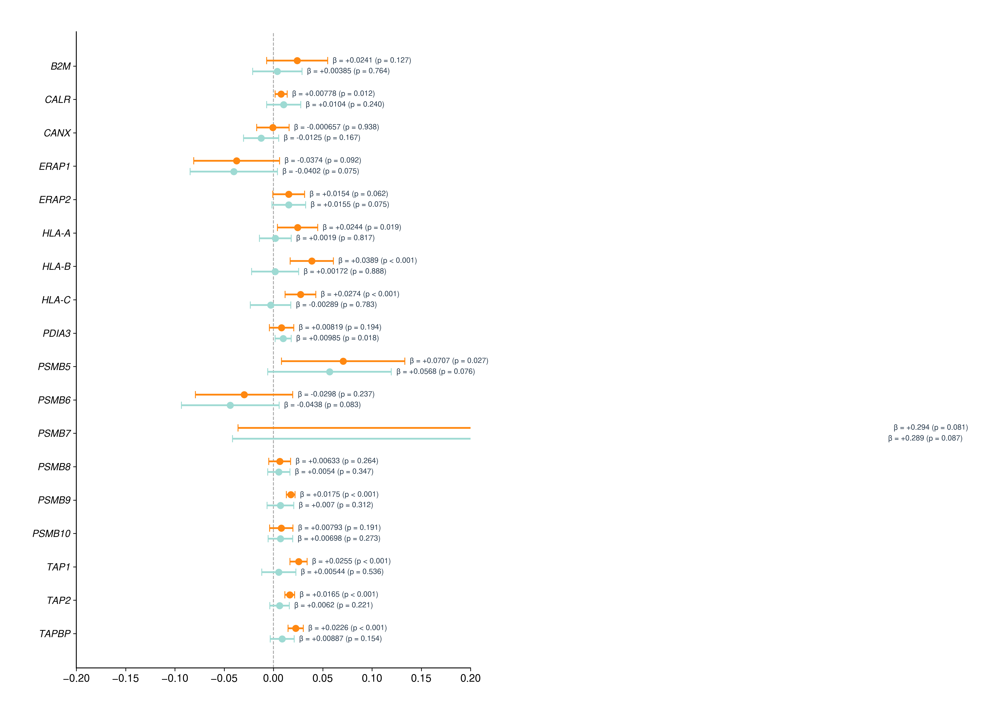

In [368]:
plot_gee_forest(gee_genes(apm_lit1, filter_cell=True), apm_lit1, figsize=(8,13), xlim=.8, xlim_gap=.01, pval_gap=.05)
plot_gee_forest(gee_genes(apm_lit1, filter_cell=True), apm_lit1, figsize=(8,13), xlim=.2, xlim_gap=.01, pval_gap=.005)

#### Supp Fig 12b

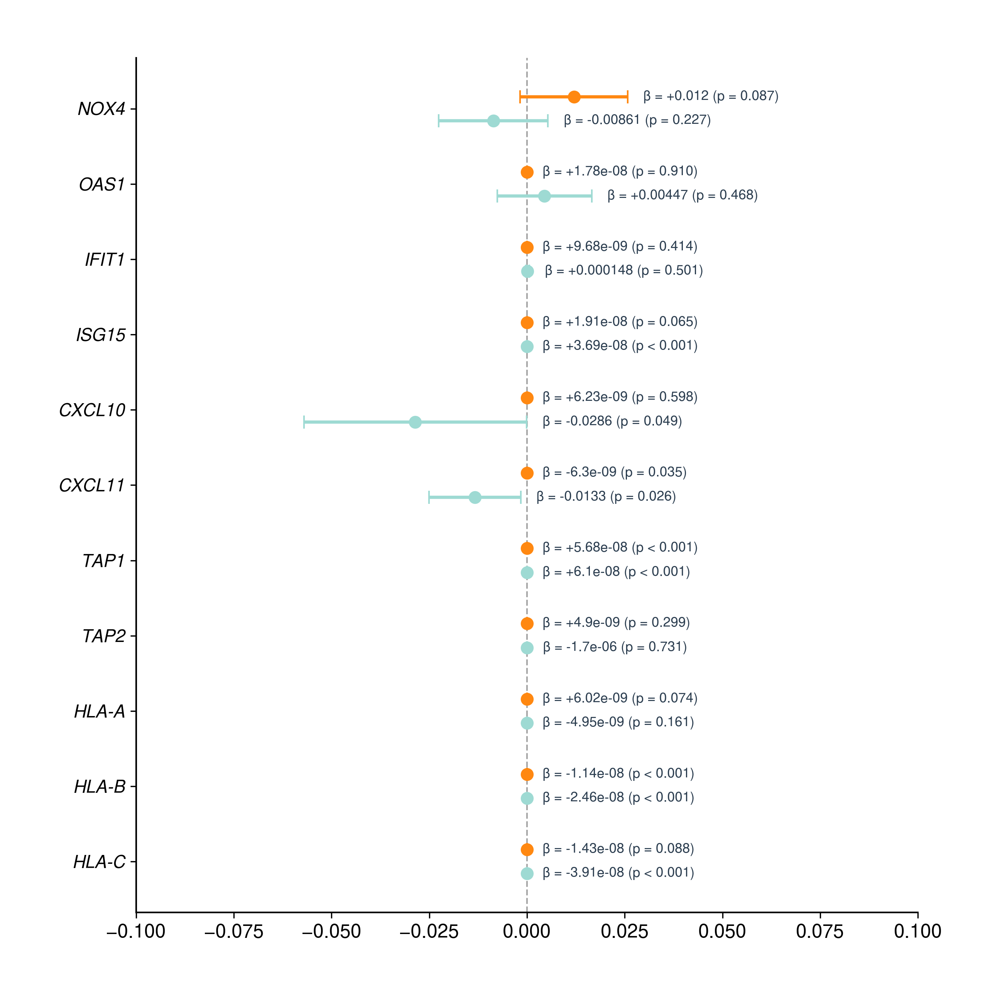

In [369]:
genes = ["NOX4","OAS1","IFIT1","ISG15","CXCL10","CXCL11","TAP1","TAP2","HLA-A","HLA-B","HLA-C"]
plot_gee_forest(gee_genes(genes), genes, figsize=(8,8), xlim=.1, pval_gap=.004)

### Heatmaps

In [148]:
def plot_genes_celltype2_heatmap(genes, cat="major", z=True, t=False, palette="viridis", square=True, shrink=.5, figsize=(8,8), save=False):
    if cat == "major":
        ct = weightsmajortypes2.copy()
    elif cat == "minor":
        ct = weightsminortypes2.copy()

    if isinstance(genes, dict):
        allcountscombinedfiltered = allcountscombined.filter([element for innerList in list(genes.values()) for element in innerList])
        df = pd.DataFrame(index=allcountscombinedfiltered.columns)
        for n,major in enumerate(genes.keys()):
            df[major] = allcountscombinedfiltered.loc[ct[ct.majortype==major].index].mean().to_list()
    elif isinstance(genes, list):
        allcountscombinedfiltered = allcountscombined.filter(genes)
        df = pd.DataFrame(index=allcountscombinedfiltered.columns)
        for n,catnum in enumerate(sorted_subtypes[cat].unique()):
            df[catnum] = allcountscombinedfiltered.loc[ct[ct["{}type".format(cat)]==catnum].index].mean().to_list()

    if z:
        df = df.apply(zscore, axis=1)
        title = "Expression Z-score"
    else:
        title = "Score"

    if t:
        df = df.T

    plt.figure(figsize=figsize, dpi=300)
    h = sns.heatmap(df, square=square, cmap=palette, center=0,
                    cbar_kws={"shrink":shrink, "aspect":10, "label":title}) #shrink=.5, aspect=10

    if t:
        plt.xticks(rotation=90, style="italic") 
    else:
        plt.yticks(rotation=0, style="italic") 
    
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/1D.bin{bin_size}.markers.celltype.heatmap.pdf", format="pdf", dpi=300)
    plt.show()
    return df

#### Fig 1c

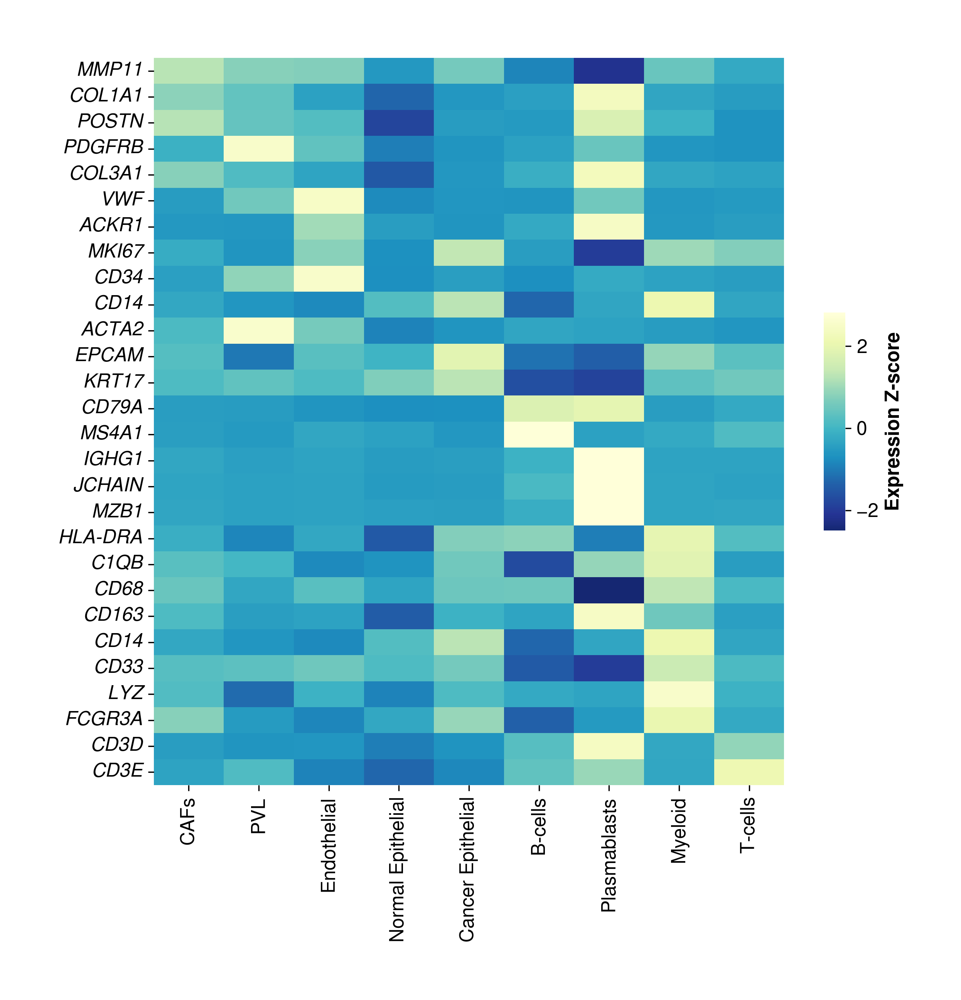

In [370]:
_=plot_genes_celltype2_heatmap(lineage_markers3, palette="YlGnBu_r", shrink=.3, square=False, figsize=(8,8))

In [186]:
def plot_gene_celltypes_vis3(genes, type="major", palette="magma", z=True, figsize=(9,4), save=False):
    if type == "major":
        df1 = pd.concat(weightsmajor2)
    elif type == "minor":
        df1 = pd.concat(weightsminor2)
    df3 = pd.DataFrame(index=sorted_subtypes[type].unique())
    for gene in genes:
        df1["score"] = allcountscombined[gene].to_list()
        weights_gene_ratio = []
        for cell in sorted_subtypes[type].unique():
            df2 = df1[df1[cell]>0.01].sum()
            # print(cell, df2["score"])
            weights_gene_ratio.append(df2["score"] / df2[cell] * 100) ## 
        df3[gene] = weights_gene_ratio
    if z:
        df3 = df3.fillna(0).apply(zscore, axis=0)
    plt.figure(figsize=figsize, dpi=300)
    sns.heatmap(data=df3.drop("Plasmablasts", axis=0).T, 
                cmap=palette, #vmax=1.3,
                robust=True, #center=0, 
                square=True, annot=True, #fmt="d",
                cbar_kws={"shrink":.5, "label":"Weight-normalised\ngene expression Z-score"})
    plt.xlabel("")
    plt.yticks(rotation=0, style="italic") 

    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/2D.major.celltypes2.genes2.{genes}.pdf", format="pdf", dpi=300)
    return df3

#### Fig 2c

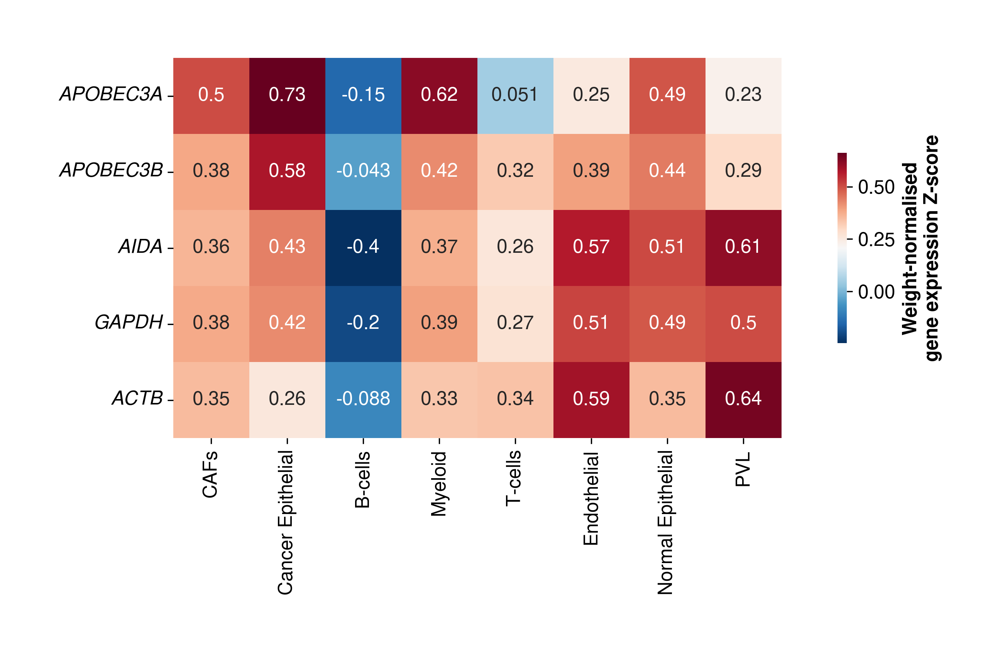

In [371]:
_=plot_gene_celltypes_vis3(["APOBEC3A","APOBEC3B","AIDA","GAPDH","ACTB"], palette="RdBu_r", figsize=(10,5))

### Correlation

In [206]:
def gee_gene_corr(gene1, gene2, filter=False, save=False):
    for i,d in enumerate(datalist[:2]):
        df = pd.concat([allcounts[i].filter([gene1,gene2]),alldfs[i]], axis=1)
        if filter:
            df = df[(df[gene1]>0) & (df[gene2]>0)]
        
        # df = df[(df[gene1]>0) & (df[gene2]>0)]
        # print(df.groupby(by="batch").size())
        formula = f"{gene1} ~ {gene2}"
    
        gee_cor_model = smf.gee(
            formula = formula,
            groups = "batch",
            data = df,
            family = sm.families.Gaussian(), #link=sm.families.links.Identity()
            cov_struct = sm.cov_struct.Exchangeable()
        )
        
        gee_cor_res = gee_cor_model.fit()
        print(f"{d} {gene1} {gene2} r {gee_cor_res.params[gene2]:.4f}, p = {gee_cor_res.pvalues[gene2]:.3g}")
        # print("r", gee_cor_res.params['CGAS'], "se", gee_cor_res.bse['CGAS'], "p value", gee_cor_res.pvalues['CGAS'])
        # print(gee_cor_res.summary())
        print(sc.stats.spearmanr(a=df[gene1],b=df[gene2]))
        plt.figure(figsize=(3,3), dpi=300)
        sns.scatterplot(data=df, x=gene1, y=gene2, s=15, color="orange")
        plt.title(f"r = {gee_cor_res.params[gene2]:.2f}, p = {gee_cor_res.pvalues[gene2]:.3g}")
        if save:
            plt.savefig(f"/stereoseq/all_samples/images/paper1/{d}.SuppFig10a.updated.IDO1.CXCL10.pdf", dpi=300, format="pdf")
        plt.show()

#### Supp Fig 11a

HOM1 CXCL10 IDO1 r 0.1966, p = 0
SignificanceResult(statistic=0.19197586131154648, pvalue=5.090703170944187e-69)


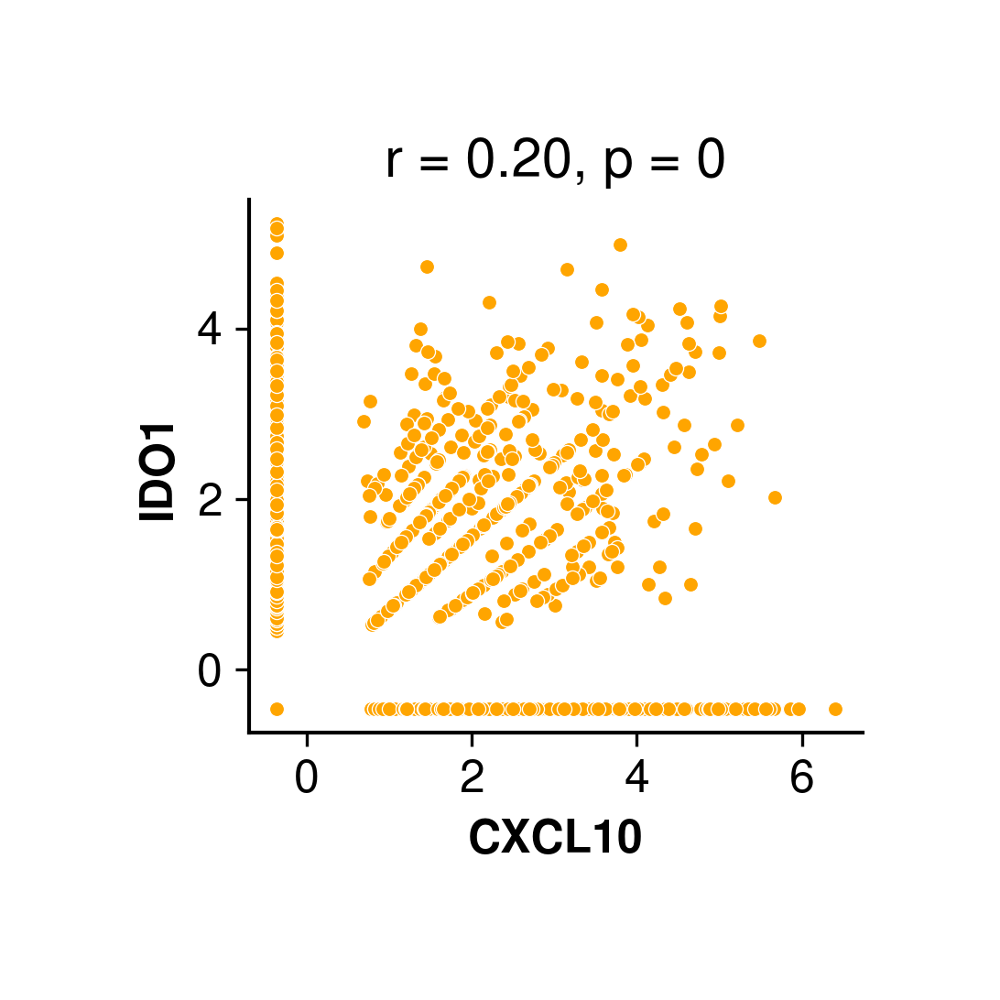

HOM2 CXCL10 IDO1 r 0.2594, p = 0
SignificanceResult(statistic=0.21669037756254053, pvalue=9.074039456180435e-140)


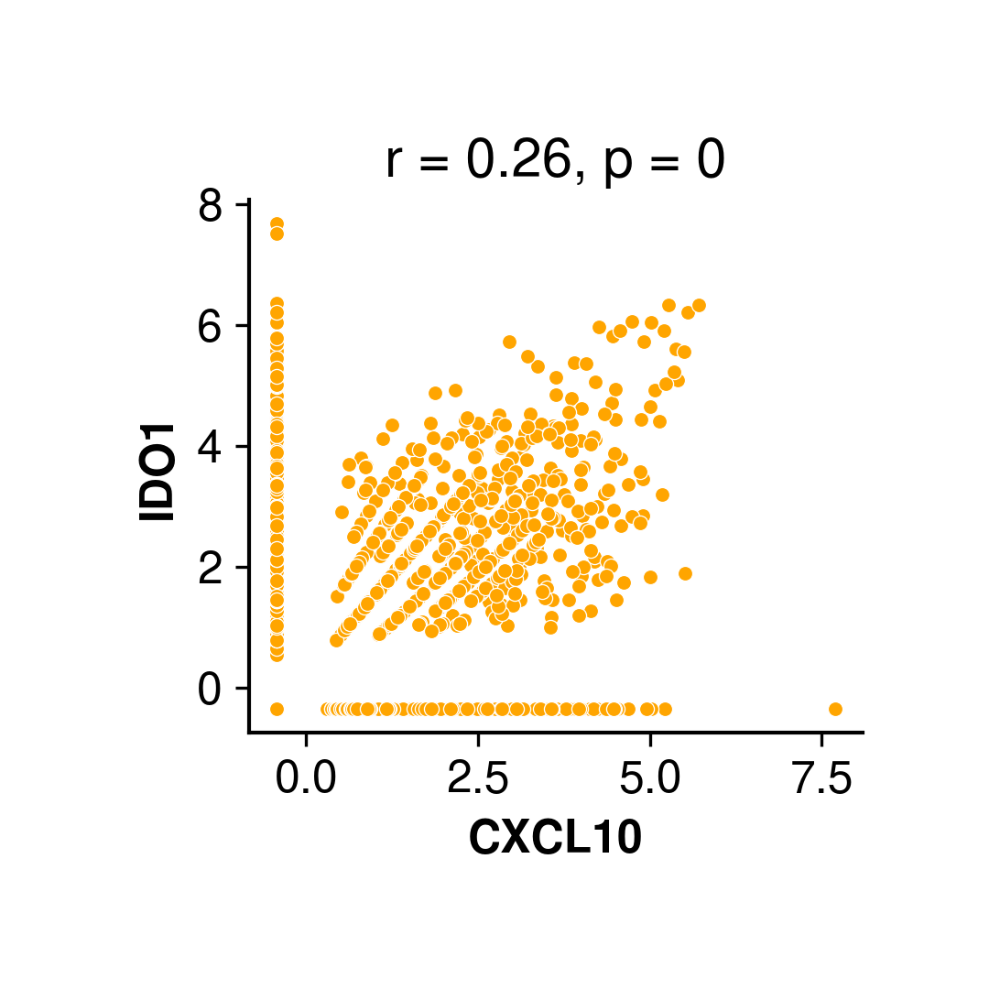

In [372]:
gee_gene_corr("CXCL10", "IDO1", filter=False)

In [208]:
def calculate_spatial_coexpression(data, g1, g2, neighbors_key="spatial_neighbors"):
    """
    Calculates spatial lag correlation and bivariate Moran's I between 2 genes in Stereopy.
    """
    # Extract log-normalized matrix & spatial connectivities graph
    expr_matrix = data.exp_matrix.toarray() if hasattr(data.exp_matrix, "toarray") else data.exp_matrix
    gene_list = list(data.gene_names)
    
    idx_a = gene_list.index(g1)
    idx_b = gene_list.index(g2)
    
    x = expr_matrix[:, idx_a]
    y = expr_matrix[:, idx_b]
    
    # Retrieve connectivity matrix (W) from Stereopy's result dictionary
    adj_matrix = data.tl.result[neighbors_key]['connectivities']
    
    # Row-normalize spatial weight matrix
    row_sums = np.array(adj_matrix.sum(axis=1)).flatten()
    row_sums[row_sums == 0] = 1.0
    W_norm = adj_matrix.multiply(1.0 / row_sums[:, np.newaxis])
    
    # 1. Spatial Lag Correlation: Gene A vs neighbor average of Gene B
    y_spatial_lag = W_norm @ y
    neighborhood_corr = np.corrcoef(x, y_spatial_lag)[0, 1]
    
    # 2. Bivariate Moran's I
    z_x = x - np.mean(x)
    z_y = y - np.mean(y)
    bivariate_moran = np.sum(z_x * (W_norm @ z_y)) / np.sqrt(np.sum(z_x**2) * np.sum(z_y**2))
    
    return neighborhood_corr, bivariate_moran

In [211]:
gene_a = "CXCL10"
gene_b = "IDO1"
corrs = pd.DataFrame(index=["spatial neighbourhood lag correlation","bivariate moran's i","pearson","spearman"])
for i,d in enumerate(datalist):
    tmp = []
    lag_corr, moran_i = calculate_spatial_coexpression(alldata[i], gene_a, gene_b)
    # print(f"Spatial Neighborhood Lag Correlation ({gene_a} vs Neighbor {gene_b}): {lag_corr:.4f}")
    # print(f"Bivariate Moran's I ({gene_a} & {gene_b}): {moran_i:.4f}")
    # print(f"Pearson correlation ({gene_a} & {gene_b}): {sc.stats.pearsonr(x=allcounts[i][gene_a], y=allcounts[i][gene_b]).statistic:.4f}")
    # print(f"Spearman correlation ({gene_a} & {gene_b}): {sc.stats.spearmanr(a=allcounts[i][gene_a], b=allcounts[i][gene_b]).statistic:.4f}")
    tmp.append(lag_corr)
    tmp.append(moran_i)
    tmp.append(sc.stats.pearsonr(x=allcounts[i][gene_a], y=allcounts[i][gene_b]).statistic)
    tmp.append(sc.stats.spearmanr(a=allcounts[i][gene_a], b=allcounts[i][gene_b]).statistic)
    corrs[d] = tmp
corrs

,HOM1,HOM2,HOM3,HET1,HET2,WT1,WT2,WT3
spatial neighbourhood lag correlation,0.256807,0.451805,0.208314,0.385451,0.256312,-0.011574,0.004093,0.128918
bivariate moran's i,0.100899,0.193000,0.057811,0.123924,0.080115,-0.002589,0.000981,0.036746
pearson,0.196559,0.259431,0.100817,0.202902,0.115412,0.003283,-0.004502,0.047742
spearman,0.191976,0.216690,0.124700,0.214900,0.169729,0.018281,0.002332,0.083761


## Mutations

### Scatterplots

In [226]:
def plot_all_mutations3_subplots(dfs, filter=False, threshold=0, palette="magma_r", 
                                 no_base=False, cbar=True, title="", factor=2, 
                                 nrows=4, ncols=2, bin_size=bin_size, save=False):
    if cbar:
        width = 3
    else:
        width = 2.5
    plt.subplots(nrows, ncols, figsize=(width*factor*ncols,2*factor*nrows), dpi=300)
    # print(bin_size)
    for i,d in enumerate(datalist):
        df = dfs[i].copy()
        plt.subplot(nrows,ncols,i+1)
        r1, xlim, ylim, pad, addpadx, addpady, dot_size = adjust(df, d, factor=factor, bin_size=bin_size, subplot=True)
        #print(dot_size)
        
        if r1 > 1: # redefine ylim bc it's too fat
            ylim = (max(df["y"])+pad+addpady+1000, min(df["y"])-pad-addpady-1000)
        else: # r1 < 0, redefine xlim bc it's too tall
            xlim = (min(df["x"])-pad-addpadx, max(df["x"])+pad+addpadx)
    
        found = True
        try: 
            hue = df["normlogfiltered"]
        except KeyError:
            found = False
        if found:
            if filter:
                df1 = df[df["normlogfiltered"]>threshold]
                hue = df1["normlogfiltered"]
            else:
                df1 = df.copy()
            
            if no_base:
                df1 = df[df["normlogfiltered"]>threshold]
                hue = df1["normlogfiltered"]
                p = sns.scatterplot(data=alldfs[i], x="x", y="y", linewidth=0, s=dot_size, marker="s", color="#f3f0f0")
                p = sns.scatterplot(data=df1, x="x", y="y", hue=hue, hue_norm=(0,1), #legend=False,
                                linewidth=0, s=dot_size+10, marker="s", palette=palette)
            else:
                p = sns.scatterplot(data=df1, x="x", y="y", hue=hue, hue_norm=(0,1), #legend=False,
                                linewidth=0, s=dot_size, marker="s", palette=palette)
            if len(df1) > 0:
                p.get_legend().remove()
        else:
            p = sns.scatterplot(data=alldfs[i], x="x", y="y", linewidth=0, s=dot_size, marker="s", color="#f3f0f0")
            
        p.spines[['left', 'bottom']].set_visible(False)
        
        if isinstance(xlim, tuple):
            plt.xlim(xlim)
            plt.ylim(max(df["y"])+addpady, min(df["y"])-addpady)
        elif isinstance(ylim, tuple):
            plt.xlim(min(df["x"])-addpadx, max(df["x"])+addpadx)
            plt.ylim(ylim)
        plt.xlabel("")
        plt.ylabel("")
        plt.xticks([])
        plt.yticks([])

        if cbar:
            #norm = plt.Normalize(0, 10*len(gene))
            norm = plt.Normalize(0, 1)
            sm = plt.cm.ScalarMappable(cmap=palette, norm=norm)
            sm.set_array([])
            #p.get_legend().remove()
            cb = p.figure.colorbar(sm, shrink=.5, aspect=12) #, location="bottom"
            #cb.ax.tick_params(color="white")
        # plt.title("{}".format(d), weight="bold", fontsize=12)
    
    #p.get_legend().remove()
    # plt.suptitle("{} somatic mutations".format(muttype), weight="bold", fontsize=15)
    # if threshold > 0:
    #     plt.suptitle("{} somatic mutations > {}".format(muttype, threshold), weight="bold", fontsize=20)
    # if title != "":
    #     plt.suptitle(title, weight="bold", fontsize=15)
    plt.tight_layout()
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/bin{bin_size}.{title}.somatic.mutations.scatter.subplots.pdf", format="pdf", dpi=300)
    plt.show()

#### Fig 3a

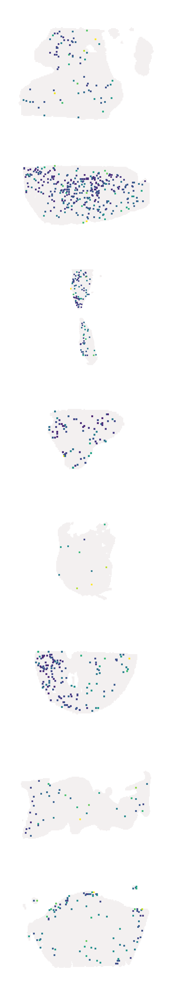

In [373]:
plot_all_mutations3_subplots(apobec, title="APOBEC mutations", cbar=False, nrows=8, ncols=1, 
                             palette="viridis", no_base=True)

#### Supp Fig 4a

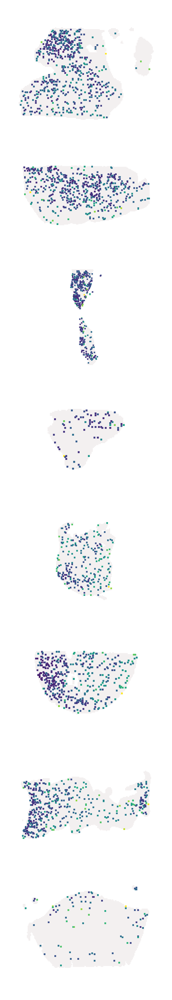

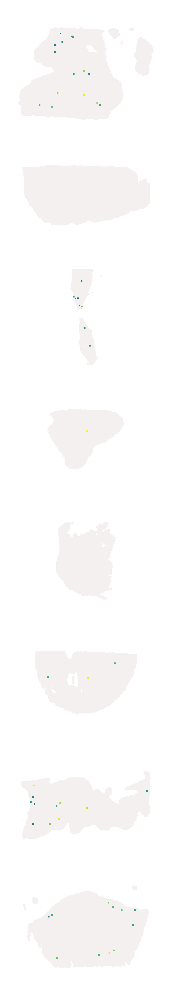

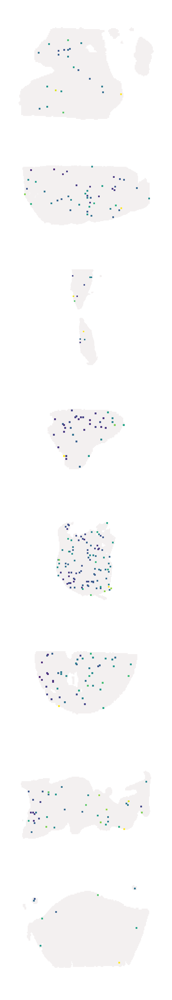

In [374]:
plot_all_mutations3_subplots(sbs1, title="SBS1 mutations", cbar=False, nrows=8, ncols=1, 
                             palette="viridis", no_base=True)
plot_all_mutations3_subplots(sbs10, title="SBS10a mutations", cbar=False, nrows=8, ncols=1, 
                             palette="viridis", no_base=True)
plot_all_mutations3_subplots(sbs2_editing, title="RNA editing SBS2 mutations", cbar=False, nrows=8, ncols=1, 
                             palette="viridis", no_base=True)

In [223]:
def plot_multiple_mutations_subplots(mutdfs, colors=[], threshold=0, palette="magma_r", 
                                     title="", factor=2, nrows=4, ncols=2,
                                     bin_size=bin_size, save=False):
    plt.subplots(nrows, ncols, figsize=(2.5*factor*ncols,2*factor*nrows), dpi=300)
    # print(bin_size)
    
    for i,d in enumerate(datalist):
        df = alldfs[i].copy()
        plt.subplot(nrows,ncols,i+1)
        r1, xlim, ylim, pad, addpadx, addpady, dot_size = adjust(df, d, factor=factor, bin_size=bin_size, subplot=True)

        if r1 > 1: # redefine ylim bc it's too fat
            ylim = (max(df["y"])+pad+addpady+1000, min(df["y"])-pad-addpady-1000)
        else: # r1 < 0, redefine xlim bc it's too tall
            xlim = (min(df["x"])-pad-addpadx, max(df["x"])+pad+addpadx)
        
        p = sns.scatterplot(data=df, x="x", y="y", linewidth=0, s=dot_size, marker="s", color="#f3f0f0")
        for k,dfs in enumerate(mutdfs):
            df = dfs[i]
            found = True
            try: hue = df["normlogfiltered"]
            except KeyError:
                found = False
            
            if found:
                df1 = df[df["normlogfiltered"]>threshold]
                p = sns.scatterplot(data=df1, x="x", y="y", color=colors[k],
                                linewidth=0, s=dot_size+10, marker="s", palette=palette)
                
            p.spines[['left', 'bottom']].set_visible(False)
        
        if isinstance(xlim, tuple):
            plt.xlim(xlim)
            plt.ylim(max(df["y"])+addpady, min(df["y"])-addpady)
        elif isinstance(ylim, tuple):
            plt.xlim(min(df["x"])-addpadx, max(df["x"])+addpadx)
            plt.ylim(ylim)
        plt.xlabel("")
        plt.ylabel("")
        plt.xticks([])
        plt.yticks([])

        # norm = plt.Normalize(0, 1)
        # sm = plt.cm.ScalarMappable(cmap=palette, norm=norm)
        # sm.set_array([])
        # p.figure.colorbar(sm, shrink=.5, aspect=12)
        # plt.title("{}".format(d), weight="bold", fontsize=12)
    
    #p.get_legend().remove()
    # plt.suptitle("{} somatic mutations".format(muttype), weight="bold", fontsize=20)
    if threshold > 0:
        plt.suptitle("{} somatic mutations > {}".format(muttype, threshold), weight="bold", fontsize=20)
    if title != "":
        plt.suptitle(title, weight="bold", fontsize=15)
    plt.tight_layout()
    if save:
        plt.savefig(f"/stereoseq/all_samples/paper1/bin{bin_size}.{d}.{muttype}.somatic.mutations.{title}.scatter.subplots.pdf", format="pdf", dpi=300)
    # plt.show()

#### Fig 3b

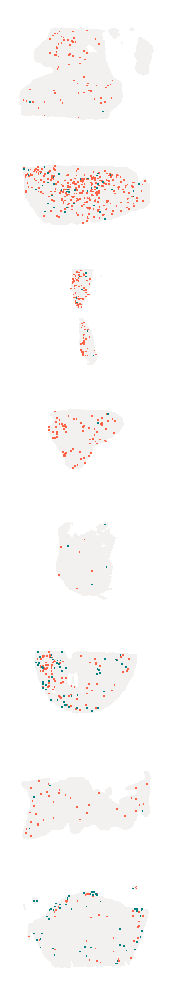

In [375]:
plot_multiple_mutations_subplots([sbs2,sbs13], colors=["tomato","teal"], nrows=8, ncols=1)

In [286]:
def plot_all_mutations4_subplots(dfs, filter=False, threshold=0, palette="magma_r", 
                                 no_base=False, cbar=True, title="", factor=2, 
                                 nrows=2, ncols=4, bin_size=bin_size, save=False):
    if cbar:
        width = 3
    else:
        width = 2.5
    plt.subplots(nrows, ncols, figsize=(width*factor*ncols,2*factor*nrows), dpi=300)
    # print(bin_size)
    for i,d in enumerate(datalist):
        df = dfs[i].copy()
        df[["unique_mutations"]] = df[["unique_mutations"]].fillna(0)
        plt.subplot(nrows,ncols,i+1)
        r1, xlim, ylim, pad, addpadx, addpady, dot_size = adjust(df, d, factor=factor, bin_size=bin_size, subplot=True)
        #print(dot_size)
        
        if r1 > 1: # redefine ylim bc it's too fat
            ylim = (max(df["y"])+pad+addpady+1000, min(df["y"])-pad-addpady-1000)
        else: # r1 < 0, redefine xlim bc it's too tall
            xlim = (min(df["x"])-pad-addpadx, max(df["x"])+pad+addpadx)
    
        found = True
        try: 
            hue = df["unique_mutations"]
        except KeyError:
            found = False
        if found:
            if filter:
                df1 = df[df["unique_mutations"]>threshold]
                hue = df1["unique_mutations"]
            else:
                df1 = df.copy()
            
            if no_base:
                df1 = df[df["unique_mutations"]>threshold]
                hue = df1["unique_mutations"]
                p = sns.scatterplot(data=alldfs[i], x="x", y="y", linewidth=0, s=dot_size, marker="s", color="#f3f0f0")
                p = sns.scatterplot(data=df1, x="x", y="y", hue=hue, hue_norm=(hue.min(), hue.max()), #legend=False,
                                linewidth=0, s=dot_size, marker="s", palette=palette)
            else:
                p = sns.scatterplot(data=df1, x="x", y="y", hue=hue, hue_norm=(hue.min(), hue.max()), #legend=False,
                                linewidth=0, s=dot_size, marker="s", palette=palette)
            if len(df1) > 0:
                p.get_legend().remove()
        else:
            p = sns.scatterplot(data=alldfs[i], x="x", y="y", linewidth=0, s=dot_size, marker="s", color="#f3f0f0")
            
        p.spines[['left', 'bottom']].set_visible(False)
        
        if isinstance(xlim, tuple):
            plt.xlim(xlim)
            plt.ylim(max(df["y"])+addpady, min(df["y"])-addpady)
        elif isinstance(ylim, tuple):
            plt.xlim(min(df["x"])-addpadx, max(df["x"])+addpadx)
            plt.ylim(ylim)
        plt.xlabel("")
        plt.ylabel("")
        plt.xticks([])
        plt.yticks([])

        if cbar:
            #norm = plt.Normalize(0, 10*len(gene))
            norm = plt.Normalize(hue.min(), hue.max())
            sm = plt.cm.ScalarMappable(cmap=palette, norm=norm)
            sm.set_array([])
            #p.get_legend().remove()
            cb = p.figure.colorbar(sm, shrink=.5, aspect=12) #, location="bottom"
            #cb.ax.tick_params(color="white")
        plt.title("{}".format(d), weight="bold", fontsize=12)
    
    #p.get_legend().remove()
    # plt.suptitle("{} somatic mutations".format(muttype), weight="bold", fontsize=15)
    # if threshold > 0:
    #     plt.suptitle("{} somatic mutations > {}".format(muttype, threshold), weight="bold", fontsize=20)
    if title != "":
        plt.suptitle(title, weight="bold", fontsize=15)
    plt.tight_layout()
    if save:
        # plt.savefig("/stereoseq/all_samples/images/paper1/bin{0}.{1}.somatic.mutations.scatter.subplots.pdf".format(bin_size, title), format="pdf", dpi=300)
        plt.savefig(f"/stereoseq/all_samples/images/paper1/bin{bin_size}.{title}.somatic.mutations.scatter.subplots.png", format="png", dpi=300)
    plt.show()

In [287]:
def white_to_inferno_r(n=256, white_frac=.15):
    inferno = matplotlib.cm.get_cmap("inferno_r", n)
    colors = inferno(np.linspace(0, 1, n))
    cutoff = int(n * white_frac)
    # Blend white into the low end
    for i in range(cutoff):
        alpha = i / cutoff
        colors[i, :3] = (1 - alpha) * np.array([1, 1, 1]) + alpha * colors[i, :3]
    return matplotlib.colors.LinearSegmentedColormap.from_list(
        "white_inferno_r", colors
    )

In [288]:
# writer = pd.ExcelWriter("unique_mutations.xlsx")
ums = []
for i,d in enumerate(datalist):
    df = all_muts[i].copy()
    df["chr:pos"] = df.apply(lambda row: str(row["chromosome"]) + ":" + str(row["position"]), axis=1)
    unique_mutations = df.groupby(by=["round_x","round_y","chr:pos","change"]).size().groupby(by=["round_x","round_y"]).size().reset_index()
    unique_mutations.rename(columns={0:"unique_mutations"}, inplace=True)
    unique_mutations.sort_values(by="unique_mutations", ascending=False, inplace=True)
    ums.append(big_mut_list_list[0][i].merge(unique_mutations, left_on=["x","y"], right_on=["round_x","round_y"], how="left"))
    # print(unique_mutations)
    # big_mut_list_list[0][i].merge(unique_mutations, left_on=["x","y"], right_on=["round_x","round_y"], how="left").to_excel(writer, sheet_name=d, index=False)
# writer.close()

#### Supp Fig 3b

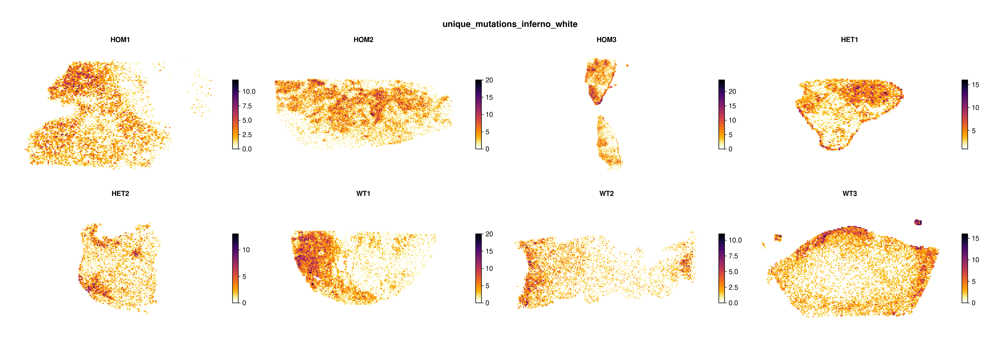

In [376]:
plot_all_mutations4_subplots(ums, title="unique_mutations_inferno_white", 
                             cbar=True, no_base=False, palette=white_to_inferno_r(white_frac=.15)) #turbo

### Barplots

In [232]:
def plot_all_bar_mutation(muttype, mut="mutation", group="sample", annot=False, palette="Set3", title="", save=False):
    if mut == "mutation":
        df = big_mut_list[muttypes.index(muttype)].copy()
    elif mut == "apobec":
        df = pd.concat(apobec)
    elif mut == "sbs2":
        df = pd.concat(sbs2)
    elif mut == "sbs13":
        df = pd.concat(sbs13)
    elif mut == "sbs1":
        df = pd.concat(sbs1)
    elif mut == "sbs10":
        df = pd.concat(sbs10)
    elif mut == "sbs4":
        df = pd.concat(sbs4)
    elif mut == "sbs2_editing":
        df = pd.concat(sbs2_editing)
    else:
        df = filter_all_mutations(muttype, mut=mut) 
    plt.figure(figsize=(6,3), dpi=300) #(4,4) #6,2.5 #4.5,3
    ax = sns.barplot(data=df, x=group, y="normlogfiltered", palette=palette)
    # plt.title("{} mutations".format(muttype), weight="bold")
    plt.xlabel("")
    plt.ylabel("mutation score")
    if annot:
        if group == "status":
            pairs = [("A3B del/del", "A3B del/WT"), ("A3B del/del", "WT"), ("A3B del/WT", "WT")]
        elif x == "sample":
            pairs = list(itertools.combinations(datalist, 2))
        annotator = Annotator(ax, pairs, data=df, x=group, y="normlogfiltered")
        annotator.configure(test='Mann-Whitney', text_format='star', loc='inside',
                           line_height=.05, line_offset_to_group=.01, line_offset=.01
                           )
        annotator.apply_and_annotate()
    plt.title(f"{title}", weight="bold")
    plt.show()
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/3D.bin{bin_size}.{muttype}.bar.{group}.pdf", format="pdf", dpi=300)

#### Fig 3d

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A3B del/del vs. A3B del/WT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.298e-07 U_stat=1.131e+08
A3B del/WT vs. WT: Mann-Whitney-Wilcoxon test two-sided, P_val:4.228e-01 U_stat=1.015e+08
A3B del/del vs. WT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.765e-12 U_stat=3.525e+08


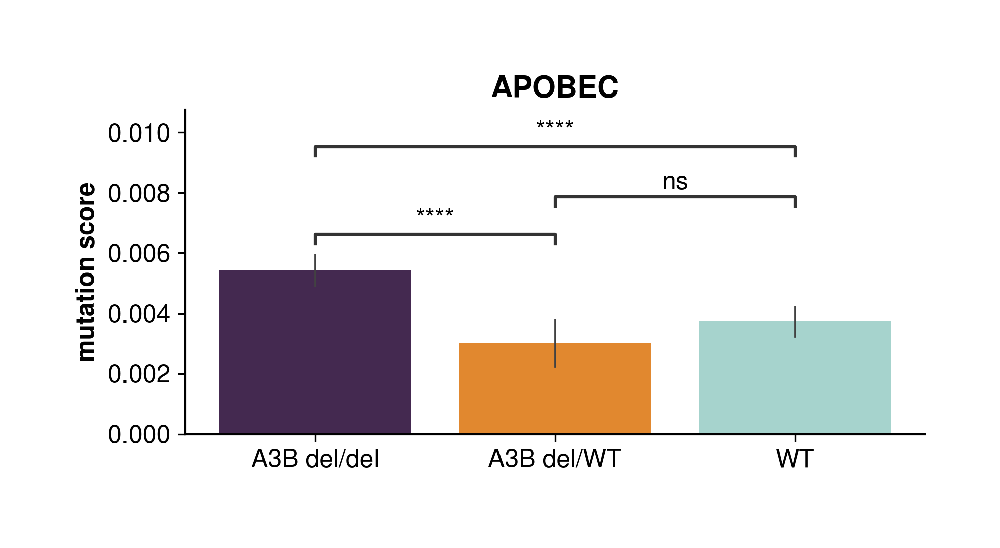

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A3B del/del vs. A3B del/WT: Mann-Whitney-Wilcoxon test two-sided, P_val:7.371e-07 U_stat=1.130e+08
A3B del/WT vs. WT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.855e-02 U_stat=1.019e+08
A3B del/del vs. WT: Mann-Whitney-Wilcoxon test two-sided, P_val:5.659e-27 U_stat=3.535e+08


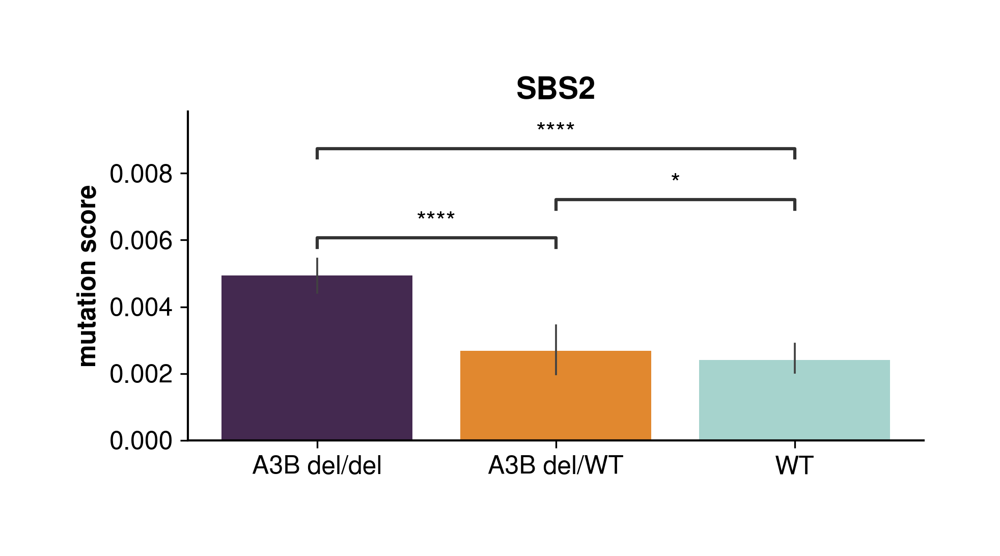

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A3B del/del vs. A3B del/WT: Mann-Whitney-Wilcoxon test two-sided, P_val:3.034e-02 U_stat=1.122e+08
A3B del/WT vs. WT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.340e-06 U_stat=1.013e+08
A3B del/del vs. WT: Mann-Whitney-Wilcoxon test two-sided, P_val:8.632e-08 U_stat=3.490e+08


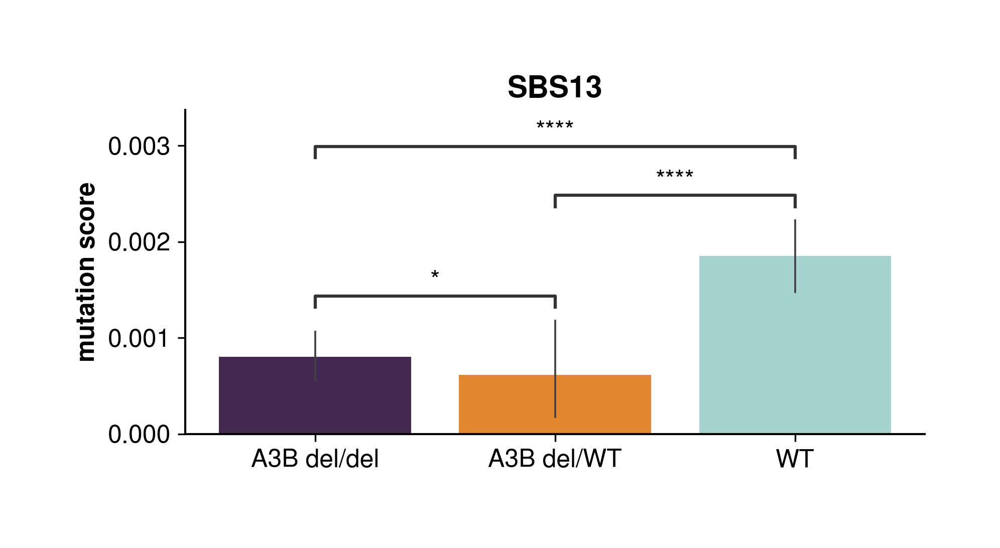

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A3B del/del vs. A3B del/WT: Mann-Whitney-Wilcoxon test two-sided, P_val:3.034e-02 U_stat=1.122e+08
A3B del/WT vs. WT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.340e-06 U_stat=1.013e+08
A3B del/del vs. WT: Mann-Whitney-Wilcoxon test two-sided, P_val:8.632e-08 U_stat=3.490e+08


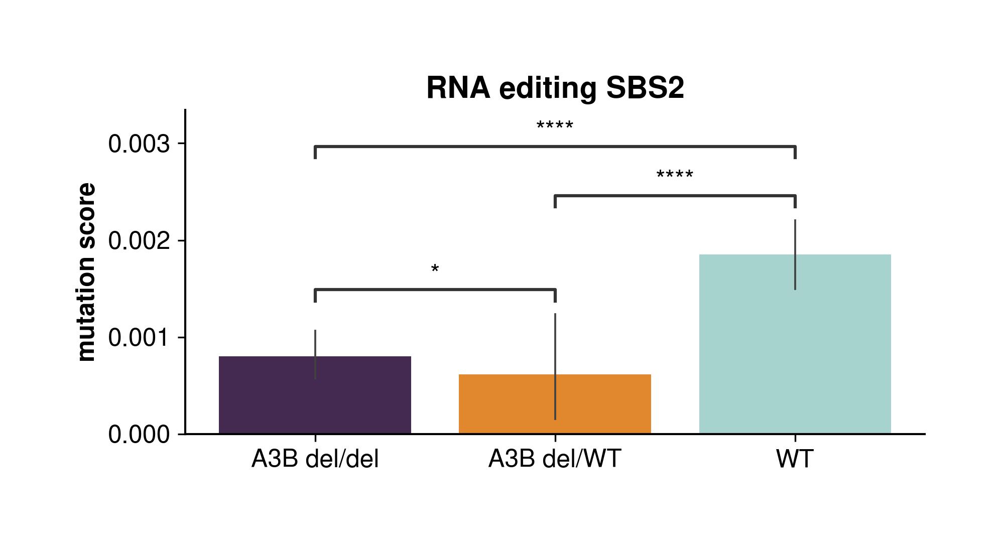

In [377]:
plot_all_bar_mutation("apobec", mut="apobec", group="status", annot=True, title="APOBEC", palette=palette7)
plot_all_bar_mutation("sbs2", mut="sbs2", group="status", annot=True, title="SBS2", palette=palette7)
plot_all_bar_mutation("sbs13", mut="sbs13", group="status", annot=True, title="SBS13", palette=palette7)
plot_all_bar_mutation("sbs2_editing", mut="sbs13", group="status", annot=True, title="RNA editing SBS2", palette=palette7)

#### Supp Fig 4b

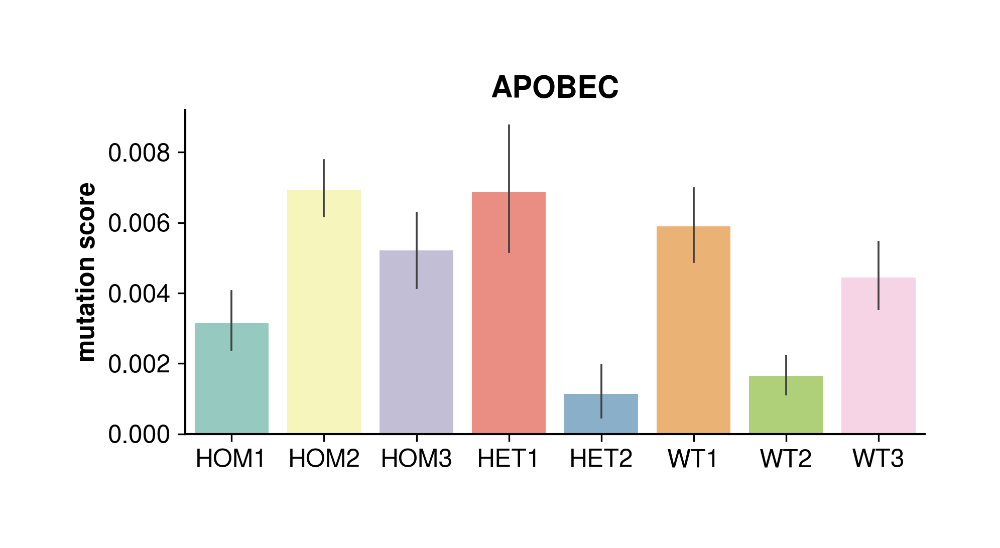

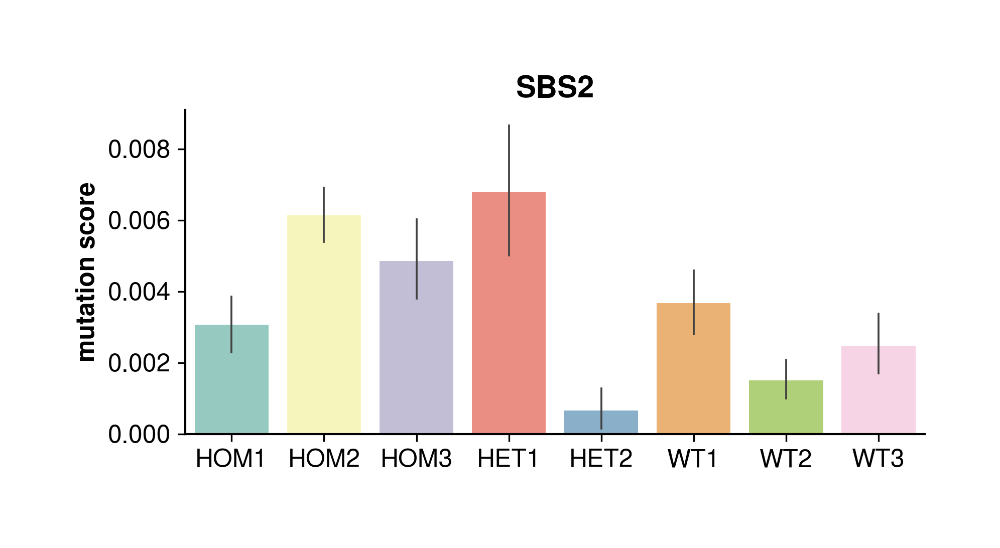

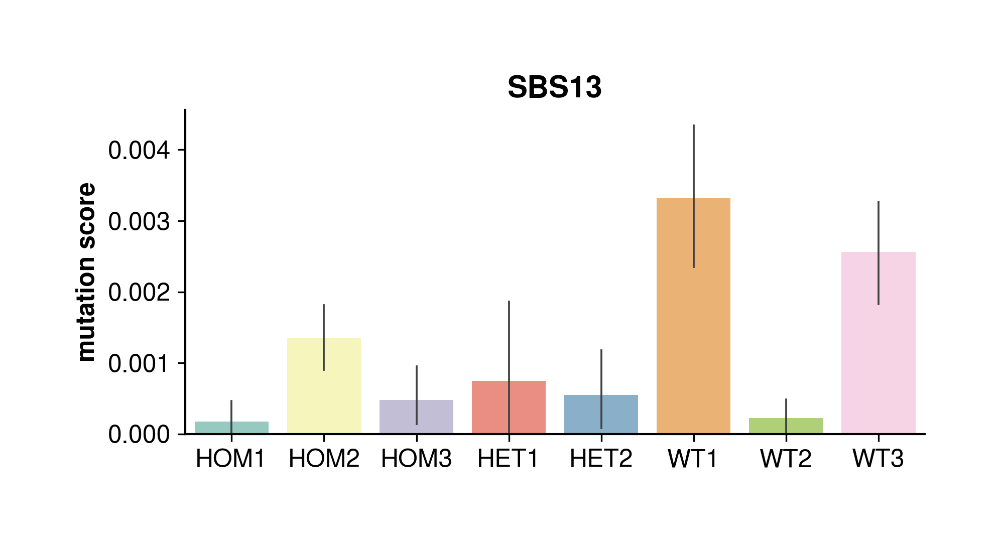

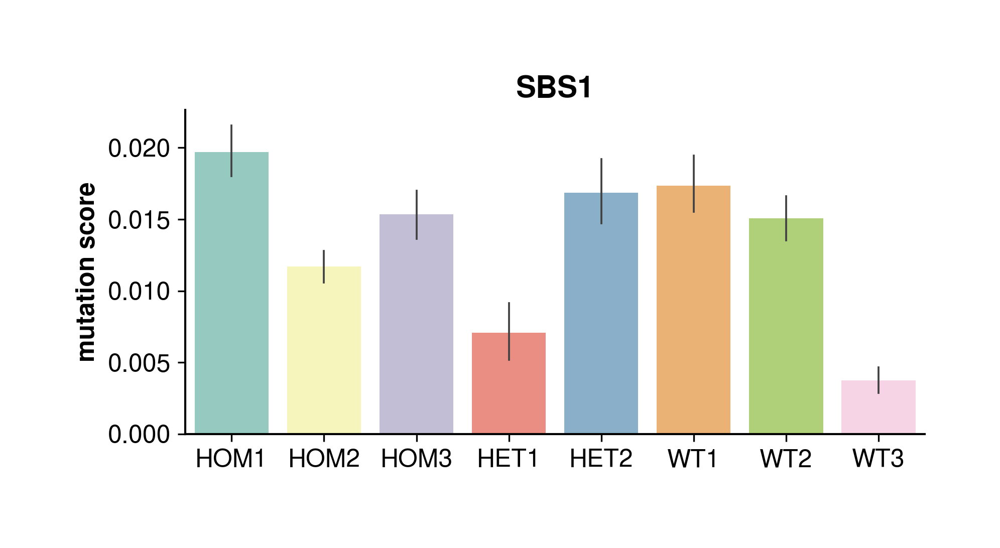

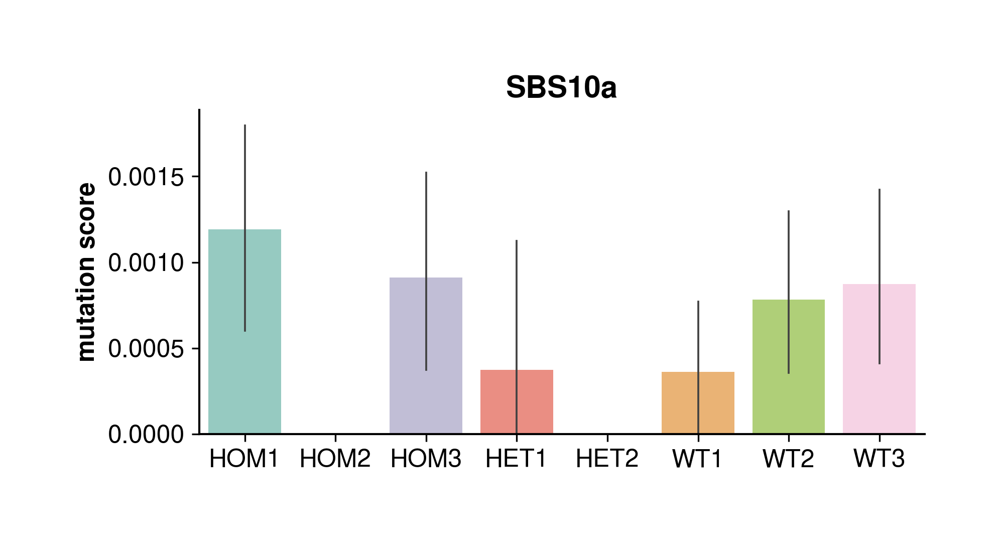

KeyError: 'concat'

In [378]:
plot_all_bar_mutation("apobec", mut="apobec", group="sample", annot=False, title="APOBEC", palette="Set3")
plot_all_bar_mutation("sbs2", mut="sbs2", group="sample", annot=False, title="SBS2", palette="Set3")
plot_all_bar_mutation("sbs13", mut="sbs13", group="sample", annot=False, title="SBS13", palette="Set3")
plot_all_bar_mutation("sbs1", mut="sbs1", group="sample", annot=False, title="SBS1", palette="Set3")
plot_all_bar_mutation("sbs10", mut="sbs10", group="sample", annot=False, title="SBS10a", palette="Set3")
plot_all_bar_mutation("concat", mut="concat", group="sample", annot=False, title="RNA editing SBS2", palette="Set3")

In [229]:
def plot_bar_mutations(col, col_value=None, filter=False, group=None, title=""):
    if filter:
        plt.figure(figsize=(4,4)) #, dpi=300
        # df = all_all_muts[all_all_muts[col]==col_value].groupby(group, sort=False).size().reset_index()
        df = pd.DataFrame(index=datalist).join(all_all_muts[all_all_muts[col]==col_value].groupby(group, sort=False).size().reset_index().set_index(group))
        sns.barplot(df, y=df.index, x=0)
        plt.title(col_value, weight="bold")
        plt.xlabel("Number of transcripts")
    else:
        nrows = 4
        ncols = 2
        factor = 1
        plt.subplots(nrows, ncols, figsize=(5*ncols*factor,3.5*nrows*factor), dpi=300)
        for i,d in enumerate(datalist):
            plt.subplot(nrows,ncols,i+1)
            df = all_muts[i].groupby(col).size().reset_index().sort_values(0, ascending=False).head(10)
            sns.barplot(df, y=col, x=0)
            plt.title(d, weight="bold")
            plt.xlabel("Number of transcripts")
        plt.suptitle(title, weight="bold", fontsize=15)
    plt.show()

    return df

#### Supp Fig 3a

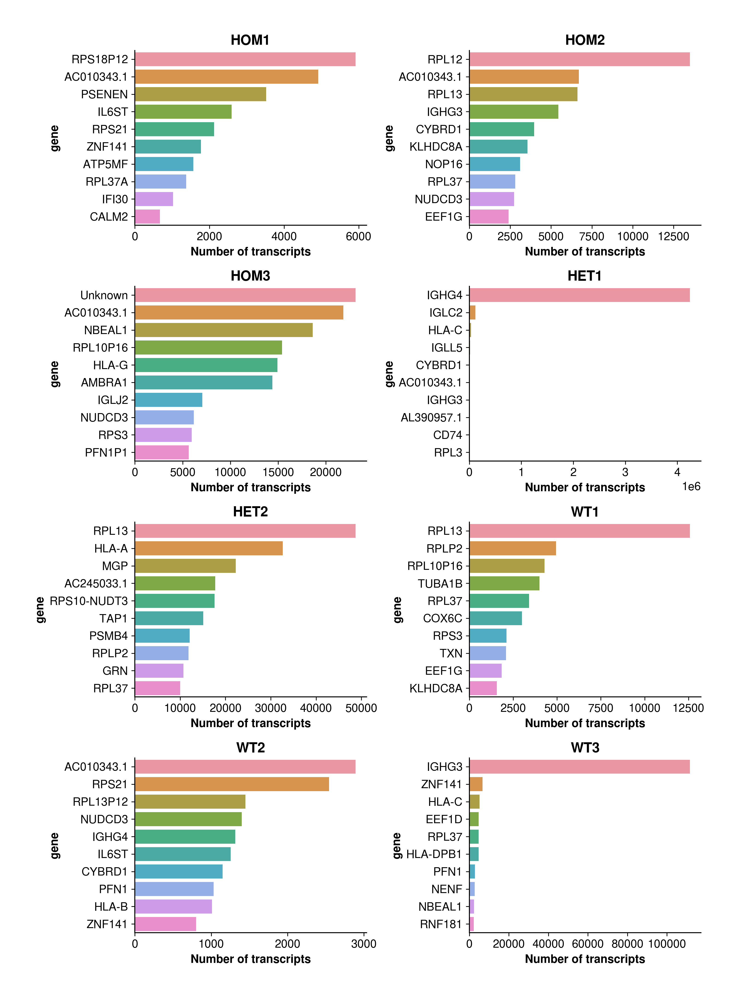

,gene,0
551,IGHG3,111626
1309,ZNF141,6639
510,HLA-C,5194
371,EEF1D,4742
997,RPL37,4691
512,HLA-DPB1,4671
837,PFN1,2871
761,NENF,2675
745,NBEAL1,2395
979,RNF181,2297


In [379]:
plot_bar_mutations("gene")

### Heatmaps

In [240]:
def plot_mutation_celltypes_vis2(df, muttypes, palette="magma", split=False, t=False, figsize=(10,5), save=False):
    if split:
        gp = pd.DataFrame(index=sorted_subtypes.major.unique())
        for i,d in enumerate(datalist):
            dff = df[i]
            dff["majortype"] = weightsmajortypes2_list[i]["majortype"].to_list()
            df1 = dff[dff[muttypes]>0]
            gp[d] = df1.groupby(by="majortype", sort=False, group_keys=True).count().reindex(sorted_subtypes.major.unique(), fill_value=0).x.to_list()
        plt.figure(figsize=figsize, dpi=300)
        sns.heatmap(data=gp.T, cmap=palette, annot=True, fmt="d",
                    cbar_kws={"shrink":.3, "label":"bin count"}, square=True)
        plt.xlabel("")
    else:
        gp = pd.DataFrame(index=sorted_subtypes.major.unique())
        df["majortype"] = weightsmajortypes2["majortype"].to_list()
        for j,muttype in enumerate(muttypes):
            df1 = df[df[muttype]>0]
            gp[muttype] = df1.groupby(by="majortype", sort=False, group_keys=True).count().reindex(sorted_subtypes.major.unique(), fill_value=0).x.to_list()
        plt.figure(figsize=figsize, dpi=300)
        sns.heatmap(data=gp.T, cmap=palette, annot=True, fmt="d",
                    cbar_kws={"shrink":.3, "label":"Bin count"}, square=True)
        plt.xlabel("")
    
    if save:
        plt.savefig("/stereoseq/all_samples/images/paper1/mutation.{muttypes}.celltypes.heatmap.pdf", format="pdf", dpi=300)

#### Fig 3e

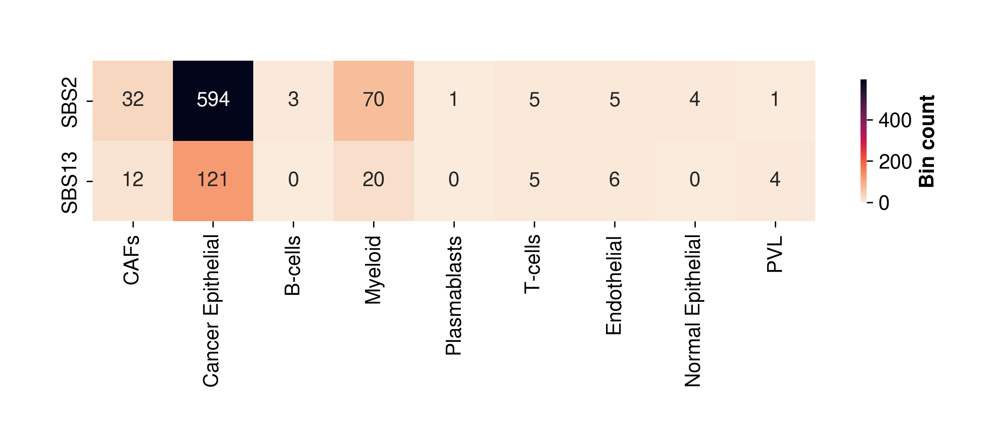

In [380]:
plot_mutation_celltypes_vis2(big_mut_list_together_sigs, ["SBS2","SBS13"], figsize=(8,4), palette="rocket_r")

#### Supp Fig 5

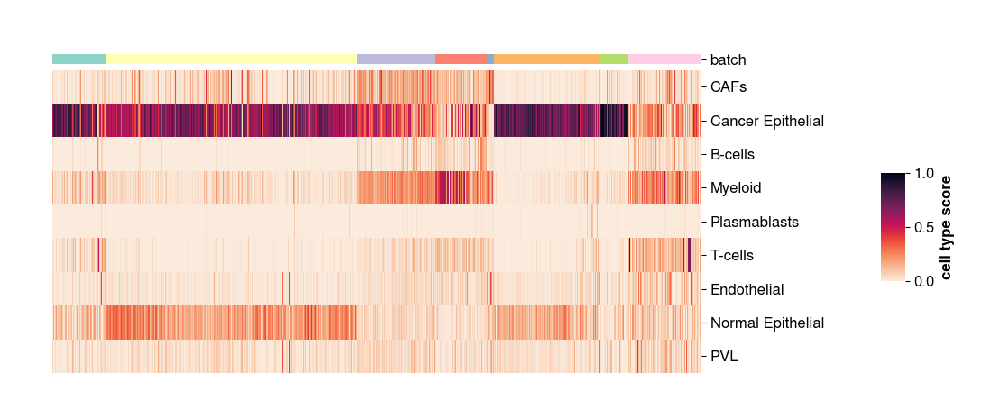

In [381]:
df1 = pd.concat(weightsmajor2)
df2 = pd.concat(apobec)
df1["score"] = df2["normlogfiltered"].to_list()
df3 = df1[df1["score"]>0]
df3['sample'] = pd.Categorical(df3['batch'], categories=datalist, ordered=True).codes
# df4 = df3.filter(sorted_subtypes["major"].unique())
# df4['sample'] = pd.Categorical(df3['batch'], categories=datalist, ordered=True).codes
# df4 = df3.filter(sorted_subtypes["major"].unique()) * df3["score"]
# for cell in sorted_subtypes["major"].unique():
#     df4[cell] = df3[cell] * df3["score"]
# df4
# plt.figure(figsize=(10,3), dpi=300)
# sns.heatmap(data=df4.T, cmap="rocket_r", cbar_kws={"shrink":.5, "label":"cell type score"})

row_lut = dict(zip(datalist, sns.color_palette("Set3").as_hex()[:]))
row_colors = df3["batch"].map(row_lut)
pp = sns.clustermap(data=df3.filter(sorted_subtypes["major"].unique()).T, cmap="rocket_r", 
               col_colors=row_colors, xticklabels=False, vmin=0, vmax=1, 
               row_cluster=False, col_cluster=False, figsize=(9,4), dendrogram_ratio=(.01,.01), #12,4
               cbar_pos=(1.05, .3, .03, .3), cbar_kws={"label":"cell type score"})
# pp.savefig("/stereoseq/all_samples/images/paper1/Supp.mutation.APOBEC.celltypes.bins.heatmap.annot.pdf", dpi=300)
# plt.yticks([])

### Violinplots

In [279]:
tca_muts = []
for muttype in ["TCA","YTCA","RTCA"]:
    dfs = []
    for i,d in enumerate(datalist):
        j = muttypes.index(muttype)
        df = big_mut_list_list[j][i].copy()
        mu = np.log(df["normlogfiltered"]+1) #df["normlog%s"%muttype].median() log+1 #.00000001
        # df[muttype] = min_max_scaler(mu)
        df[muttype] = df["normlogfiltered"]
        dfs.append(df)
    alldf = pd.concat(dfs)
    tca_muts.append(alldf)

tca_mut = pd.concat(tca_muts, axis=1)
tca_mut = tca_mut[tca_mut.TCA>0]
tca_mut = tca_mut.loc[:,~tca_mut.columns.duplicated()].copy()
tca_mut_melt = big_mut_list_together[big_mut_list_together["TCA"]>0].melt(id_vars=["sample","status","carrier_status"], 
                                                                          value_vars=["YTCA","RTCA"], var_name="mutation", 
                                                                          value_name="score")

#### Fig 3c

Text(0, 0.5, 'mutation score')

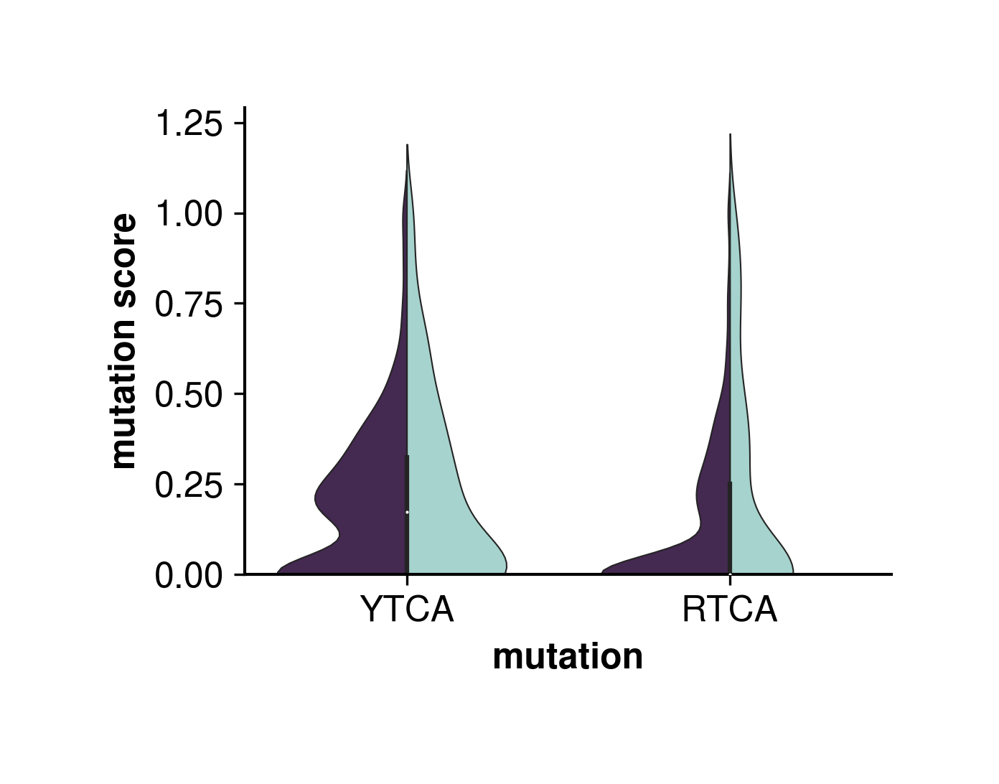

In [246]:
plt.figure(figsize=(4,3), dpi=300) #6,4
sns.violinplot(tca_mut_melt, x="mutation", y="score", hue="carrier_status",
               split=True, density_norm="width", palette=['#462356','#9EDAD3'])
plt.legend(title="A3Bdel status", title_fontproperties={"weight":"bold"},
               bbox_to_anchor=(1.05,.9), bbox_transform=plt.gcf().transFigure, loc='upper right').remove()
plt.ylim(0)
plt.xlabel("mutation")
plt.ylabel("mutation score")

# for k,med in enumerate(tca_mut_melt.groupby(by=["mutation","carrier_status"]).median().score):
#     plt.axhline(med, color=sns.color_palette("Set3")[k], ls="--")
# for k,med in enumerate(tca_mut_melt.groupby(by=["mutation","carrier_status"]).mean().score):
#     plt.axhline(med, color=sns.color_palette("Set3")[k], ls="-.")
# plt.savefig("/stereoseq/all_samples/images/3C.bin{0}.carrier.YTCA.RTCA.violin.annot.pdf".format(bin_size), format="pdf", dpi=600)

### Forestplots

In [311]:
def gee_mutations(df, muts, g="carrier_status", filter=False, filter_cell=False):
    resdfs = []
    if g == "carrier_status":
        groups = ["non-carrier","carrier"]
    elif g == "status":
        groups = ["A3B del/del", "A3B del/WT", "WT"]
    for mut in muts:
        df["mut"] = df[mut].to_list()
        df["group"] = pd.Categorical(df[g], categories=groups)
        if filter:
            df = df[df["gene"]>0]
        # print(df[df["gene"]>0].groupby(by="status", sort=False).count()["total_counts"])
        print(mut, df.groupby(by=g, sort=False).count()["total_counts"])
        
        cov_struct = Exchangeable()
        
        model = smf.gee(
            formula = "mut ~ group",
            groups = "sample",
            data = df,
            family = sm.families.Gaussian(),
            cov_struct = cov_struct
        )
        
        result = model.fit()
        # print("\n",mut)
        # print(result.summary())
    
        tmpdf = pd.DataFrame(index=groups)
        tmpdf["mut"] = mut
        tmpdf["pvalues"] = result.pvalues.to_list()
        tmpdf["beta"] = result.params.to_list()
        tmpdf["ci_low"] = result.conf_int()[0].to_list()
        tmpdf["ci_high"] = result.conf_int()[1].to_list()
        tmpdf["data"] = "Full"
        resdfs.append(tmpdf.reset_index())
    resdf = pd.concat(resdfs)
    return resdf

In [273]:
def plot_gee_forest_mutation(resdf, muts, g="carrier_status", groups=["carrier"], 
                             figsize=(8,3), xlim=0, xlim_gap=0, pval_gap=0):
    if g == "carrier_status":
        colors = {"carrier":"#462356", "non-carrier":"#9EDAD3"}
        offset = {"carrier": 0.3, "non-carrier": -0.3} # Shift points slightly up/down
    elif g == "status":
        colors = {"A3B del/del":"#462356", "A3B del/WT":"#FF8811", "WT":"#9EDAD3"}
        offset = {groups[0]: 0.3, groups[1]: -0.3} # Shift points slightly up/down

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    
    # Set vertical spacing per gene cluster
    y_base = np.arange(len(muts)) * 2.  # Space genes out
    
    
    # Plot null reference line at 0 (No effect)
    ax.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
    
    # Loop and plot points + CIs
    for idx, mut in enumerate(reversed(muts)): # Reverse to list top-to-bottom
        y_center = y_base[idx]
        
        for grp in groups:
            row = resdf[(resdf["mut"] == mut) & (resdf["index"] == grp)]
            if row.empty:
                continue
                
            y_pos = y_center + offset[grp]
            beta = row["beta"].values[0]
            ci_low = row["ci_low"].values[0]
            ci_high = row["ci_high"].values[0]
            p_val = row["pvalues"].values[0]
            
            # Error bar plot
            ax.errorbar(
                x=beta, y=y_pos,
                xerr=[[beta - ci_low], [ci_high - beta]],
                fmt='o', color=colors[grp], ecolor=colors[grp],
                elinewidth=2, capsize=4, markersize=7, label=grp if idx == 0 else ""
            )
            
            # Annotate text: "β = X.XX (p = X.XXX)"
            p_text = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"
            annotation = f"β = {beta:+.3g} ({p_text})"
            
            # Position text to the right of the error bar
            ax.text(ci_high + pval_gap, y_pos, annotation, va='center', fontsize=8.5, color='#2c3e50')
    
    # Y-axis styling
    ax.set_yticks(y_base)
    ax.set_yticklabels(reversed(muts), fontsize=11, fontweight='bold')
    ax.set_xlabel('GEE Effect Size (β Coefficient vs. carrier Reference)', fontsize=10, fontweight='bold')
    # ax.set_title('GEE Spatial Somatic Mutation across A3Bdel statuses', fontsize=12, fontweight='bold', pad=15)
    
    # Formatting limits and grid
    # ax.set_xlim(-.05,.05) # Adjust based on your min/max Beta values
    # ax.grid(axis='x', linestyle=':', alpha=0.6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Add Legend
    # ax.legend(bbox_to_anchor=(1.1,1), fontsize=8, loc='upper right')
    
    plt.tight_layout()
    plt.savefig(f"/stereoseq/all_samples/images/paper1/{d}.Fig3c.TCA.GEE.forestplot.pdf", dpi=300, format="pdf")
    plt.show()

#### Supp Fig 8a

YTCA carrier_status
carrier        546
non-carrier    169
Name: total_counts, dtype: int64
RTCA carrier_status
carrier        546
non-carrier    169
Name: total_counts, dtype: int64


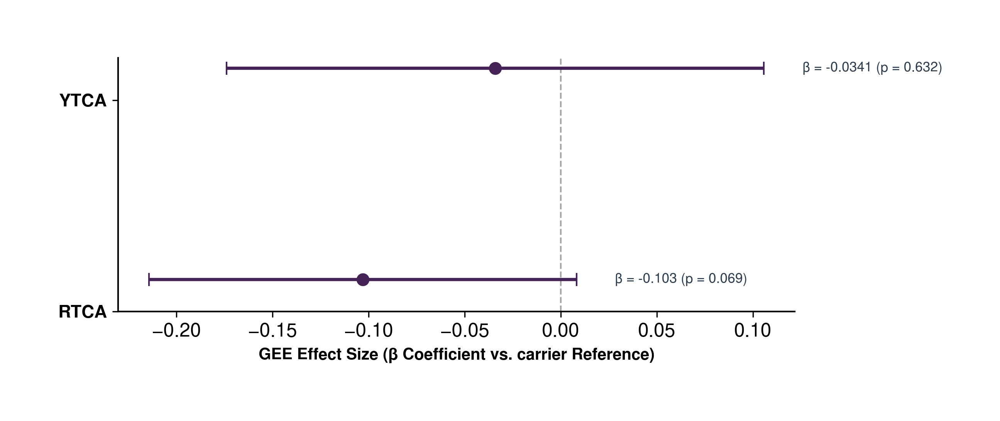

In [382]:
plot_gee_forest_mutation(gee_mutations(tca_mut, ["YTCA","RTCA"], g="carrier_status"), ["YTCA","RTCA"], pval_gap=.02)

#### Supp Fig 8b

APOBEC status
A3B del/del    27784
A3B del/WT      8070
WT             25186
Name: total_counts, dtype: int64
SBS2 status
A3B del/del    27784
A3B del/WT      8070
WT             25186
Name: total_counts, dtype: int64
SBS13 status
A3B del/del    27784
A3B del/WT      8070
WT             25186
Name: total_counts, dtype: int64
RNA-SBS2 status
A3B del/del    27784
A3B del/WT      8070
WT             25186
Name: total_counts, dtype: int64


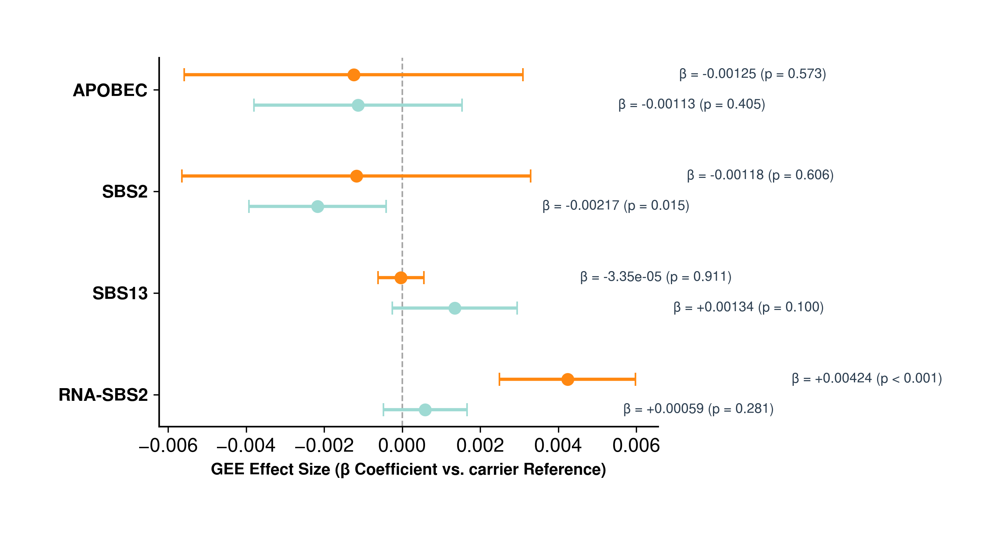

In [383]:
muts = ["APOBEC","SBS2","SBS13","RNA-SBS2"]
plot_gee_forest_mutation(gee_mutations(big_mut_list_together_sigs, muts, g="status"), muts, g="status", 
                         figsize=(8,4), groups=['A3B del/WT', 'WT'], pval_gap=.004)

## Neoantigens

### Scatterplots

In [290]:
def plot_all_neoantigens3_subplots(dfs, filter=False, threshold=0, palette="magma_r", 
                                   no_base=False, cbar=True, title="", factor=2, 
                                   nrows=2, ncols=4, bin_size=bin_size, save=False):
    if cbar:
        width = 3
    else:
        width = 2.5
    plt.subplots(nrows, ncols, figsize=(width*factor*ncols,2*factor*nrows), dpi=300)
    # print(bin_size)
    for i,d in enumerate(datalist):
        df = dfs[i].copy()
        plt.subplot(nrows,ncols,i+1)
        r1, xlim, ylim, pad, addpadx, addpady, dot_size = adjust(df, d, factor=factor, bin_size=bin_size, subplot=True)
        #print(dot_size)
        
        if r1 > 1: # redefine ylim bc it's too fat
            ylim = (max(df["y"])+pad+addpady+1000, min(df["y"])-pad-addpady-1000)
        else: # r1 < 0, redefine xlim bc it's too tall
            xlim = (min(df["x"])-pad-addpadx, max(df["x"])+pad+addpadx)
    
        found = True
        try: hue = df["normlogfiltered"]
        except KeyError:
            found = False
        if found:
            if filter:
                df1 = df[df["normlogfiltered"]>threshold]
                hue = df1["normlogfiltered"]
            else:
                df1 = df.copy()
            
            if no_base:
                df1 = df[df["normlogfiltered"]>threshold]
                hue = df1["normlogfiltered"]
                p = sns.scatterplot(data=df, x="x", y="y", linewidth=0, s=dot_size, marker="s", color="#f3f0f0")
                p = sns.scatterplot(data=df1, x="x", y="y", hue=hue, hue_norm=(0,1), #legend=False,
                                linewidth=0, s=dot_size, marker="s", palette=palette)
            else:
                p = sns.scatterplot(data=df1, x="x", y="y", hue=hue, hue_norm=(0,1), #legend=False,
                                linewidth=0, s=dot_size, marker="s", palette=palette)
            p.get_legend().remove()
        else:
            p = sns.scatterplot(data=df, x="x", y="y", linewidth=0, s=dot_size, marker="s", color="#f3f0f0")
            
        p.spines[['left', 'bottom']].set_visible(False)
        
        if isinstance(xlim, tuple):
            plt.xlim(xlim)
            plt.ylim(max(df["y"])+addpady, min(df["y"])-addpady)
        elif isinstance(ylim, tuple):
            plt.xlim(min(df["x"])-addpadx, max(df["x"])+addpadx)
            plt.ylim(ylim)
        plt.xlabel("")
        plt.ylabel("")
        plt.xticks([])
        plt.yticks([])

        if cbar:
            #norm = plt.Normalize(0, 10*len(gene))
            norm = plt.Normalize(0, 10)
            sm = plt.cm.ScalarMappable(cmap=palette, norm=norm)
            sm.set_array([])
            #p.get_legend().remove()
            cb = p.figure.colorbar(sm, shrink=.5, aspect=12) #, location="bottom"
            #cb.ax.tick_params(color="white")
        # plt.title("{}".format(d), weight="bold", fontsize=12)

    plt.tight_layout()
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/bin{bin_size}.neoantigens.scatter.subplots.pdf", format="pdf", dpi=300)
    # plt.show()

#### Fig 4a

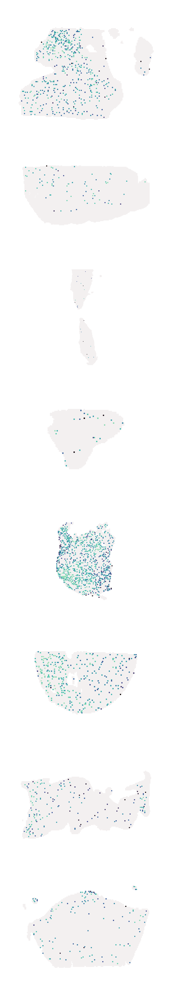

In [384]:
plot_all_neoantigens3_subplots(all_neo_list, cbar=False, no_base=True, palette="mako_r", nrows=8, ncols=1)

In [296]:
def plot_transcript_neoantigens_subplots(data, filter=False, threshold=0, palette="magma_r", no_base=False, cbar=True, title="", factor=2, bin_size=bin_size, save=False):
    nrows = 2
    ncols = 4
    if cbar:
        width = 3
    else:
        width = 2.5
    plt.subplots(nrows, ncols, figsize=(width*factor*ncols,2*factor*nrows), dpi=300)
    # print(bin_size)
    for i,d in enumerate(datalist):
        k = data[data["sample_x"]==d]
        df = alldfs[i]
        plt.subplot(nrows,ncols,i+1)
        found = True
        r1, xlim, ylim, pad, addpadx, addpady, dot_size = adjust(df, d, factor=factor, bin_size=bin_size, subplot=True)
        
        if r1 > 1: # redefine ylim bc it's too fat
            ylim = (max(df["y"])+pad+addpady+1000, min(df["y"])-pad-addpady-1000)
        else: # r1 < 0, redefine xlim bc it's too tall
            xlim = (min(df["x"])-pad-addpadx, max(df["x"])+pad+addpadx)
    
        # found = True
        # try: hue = df["normlogfiltered"]
        # except KeyError:
        #     found = False
        if found:
            if filter:
                kk = k[k["normlogfiltered"]>threshold]
                hue = kk["normlogfiltered"]
            else:
                kk = k.copy()
            
            if no_base:
                kk = k[k["normlogfiltered"]>threshold]
                hue = kk["normlogfiltered"]
                p = sns.scatterplot(data=df, x="x", y="y", linewidth=0, s=dot_size, marker="s", color="#f3f0f0")
                p = sns.scatterplot(data=kk, x="x", y="y", hue=hue, hue_norm=(0,1), #legend=False,
                                linewidth=0, s=dot_size, marker="s", palette=palette)
            else:
                p = sns.scatterplot(data=kk, x="x", y="y", hue=hue, hue_norm=(0,1), #legend=False,
                                linewidth=0, s=dot_size, marker="s", palette=palette)
        else:
            p = sns.scatterplot(data=df, x="x", y="y", linewidth=0, s=dot_size, marker="s", color="#f3f0f0")
            
        p.spines[['left', 'bottom']].set_visible(False)
        
        if isinstance(xlim, tuple):
            plt.xlim(xlim)
            plt.ylim(max(df["y"])+addpady, min(df["y"])-addpady)
        elif isinstance(ylim, tuple):
            plt.xlim(min(df["x"])-addpadx, max(df["x"])+addpadx)
            plt.ylim(ylim)
        plt.xlabel("")
        plt.ylabel("")
        plt.xticks([])
        plt.yticks([])
        plt.title("{}".format(d), weight="bold", fontsize=12)

        if cbar:
            #norm = plt.Normalize(0, 10*len(gene))
            norm = plt.Normalize(0, 10)
            sm = plt.cm.ScalarMappable(cmap=palette, norm=norm)
            sm.set_array([])
            #p.get_legend().remove()
            cb = p.figure.colorbar(sm, shrink=.5, aspect=12) #, location="bottom"
            #cb.ax.tick_params(color="white")
        else:
            try: p.get_legend().remove()
            except AttributeError:
                continue

    if title != "":
        plt.suptitle(title, weight="bold", fontsize=15)
    plt.tight_layout()
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/bin{bin_size}.neoantigens.{title}.scatter.subplots.pdf", format="pdf", dpi=300)
    # plt.show()

#### Supp Fig 6b

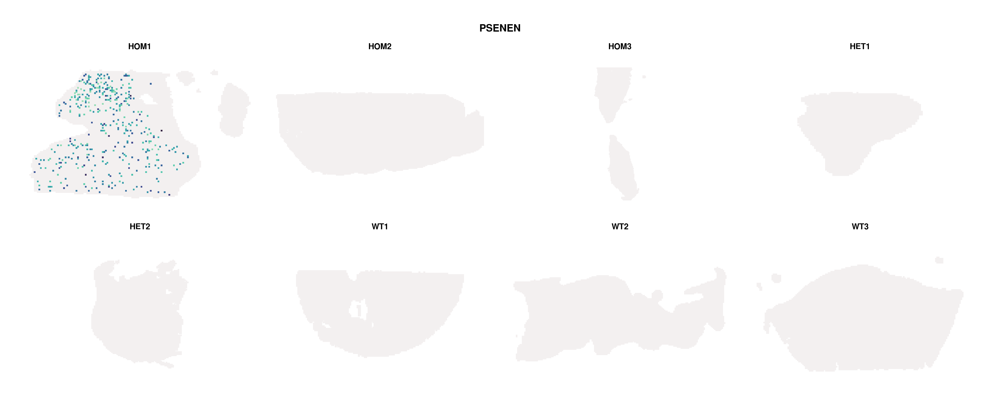

In [385]:
plot_transcript_neoantigens_subplots(neo_cancer[neo_cancer["gene"]=="PSENEN"], cbar=False, no_base=True, title="PSENEN", palette="mako_r")

### Barplots

#### Fig 4b

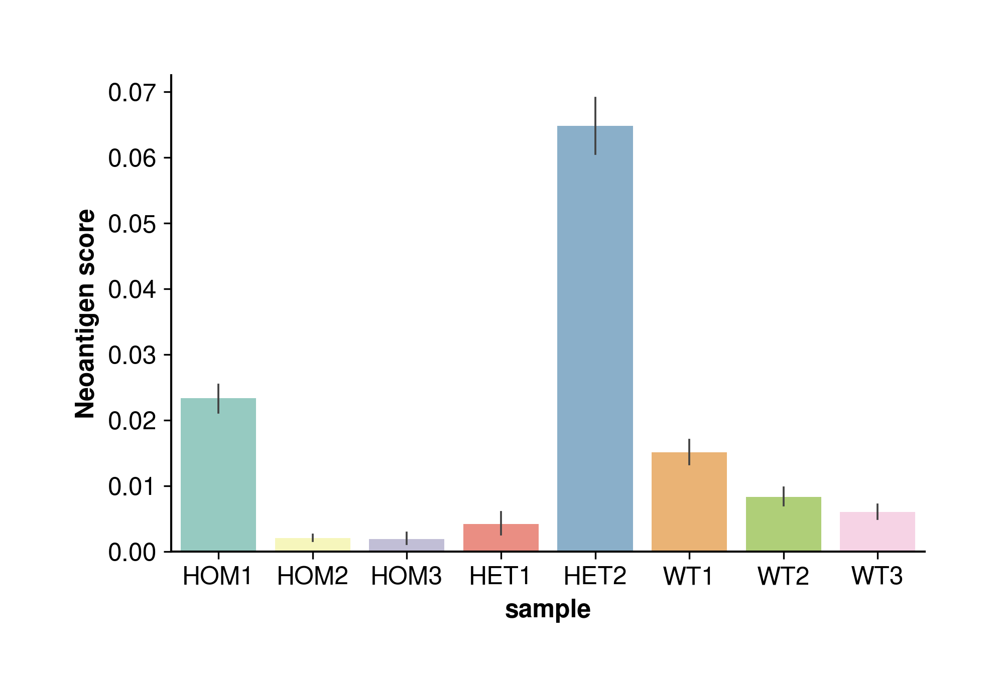

In [294]:
df = pd.concat(all_neo_list)
plt.figure(figsize=(6,4), dpi=300)
sns.barplot(data=df, x="sample", y="normlogfiltered", palette="Set3")
plt.ylabel("Neoantigen score")
plt.show()
# if save:
#     plt.savefig("/stereoseq/all_samples/images/paper1/4B.neoantigens.bar.{}.pdf".format(group), format="pdf", dpi=300)

In [301]:
def plot_neoantigen_bars2(df, split=False, fill=True, lim=None, title="", share=True, align="vertical", palette="Accent", save=False):
    df = df[(df["ref"]=="C") | (df["ref"]=="T")]
    df = df.sort_values("adjusted_trinucleotide")

    c_nuc = ['ACA', 'ACC', 'ACG', 'ACT', 
             'CCA', 'CCC', 'CCG', 'CCT', 
             'GCA', 'GCC', 'GCG', 'GCT', 
             'TCA', 'TCC', 'TCG', 'TCT']
    t_nuc = ['ATA', 'ATC', 'ATG', 'ATT', 
             'CTA', 'CTC', 'CTG', 'CTT', 
             'GTA', 'GTC', 'GTG', 'GTT', 
             'TTA', 'TTC', 'TTG', 'TTT']
    changes = ["C>A","C>G","C>T","T>A","T>C","T>G"]
    
    c_mut = df[df.change.isin(changes[:3])].groupby(by=["change","adjusted_trinucleotide"]).count()["total_counts"].unstack()
    t_mut = df[df.change.isin(changes[3:])].groupby(by=["change","adjusted_trinucleotide"]).count()["total_counts"].unstack()
    c_mut = c_mut.reindex(changes[:3])
    t_mut = t_mut.reindex(changes[3:])

    color = sns.color_palette(palette).as_hex()[:]

    if align == "vertical":
        if split:
            # fig = plt.figure(figsize=(10,15), dpi=300)
            # df.T.plot(kind="barh", subplots=True, legend=False, layout=(3,2), sharex=True, ax=plt.gca()) 
            fig, ax = plt.subplots(3, 2, figsize=(10,12.5), sharex=share, dpi=300) #(15,9)
            for i,c in enumerate(changes[:3]):
                c_mut.T.reindex(c_nuc).T.fillna(0).T[c].plot(kind="barh", title=c, legend=False, color=color[i], ax=ax[i,0]) 
            for i,c in enumerate(changes[3:]):
                t_mut.T.reindex(t_nuc).T.fillna(0).T[c].plot(kind="barh", title=c, legend=False, color=color[3+i], ax=ax[i,1]) 
        else:
            fig, ax = plt.subplots(6, 1, figsize=(5,25), sharex=share, dpi=300)
            for i,c in enumerate(changes[:3]):
                c_mut.T.reindex(c_nuc).T.fillna(0).T[c].plot(kind="barh", title=c, legend=False, color=color[i], ax=ax[i]) 
            for i,c in enumerate(changes[3:]):
                t_mut.T.reindex(t_nuc).T.fillna(0).T[c].plot(kind="barh", title=c, legend=False, color=color[3+i], ax=ax[3+i]) 
        if share:
            if lim is not None:
                plt.xlim(0,lim)
    elif align == "horizontal":
        fig, ax = plt.subplots(1, 6, figsize=(20,5), sharex=share, sharey=share, dpi=300)
        for i,c in enumerate(changes[:3]):
            c_mut.T.reindex(c_nuc).T.fillna(0).T[c].plot(kind="bar", title=c, legend=False, color=color[i], ax=ax[i]) 
        for i,c in enumerate(changes[3:]):
            t_mut.T.reindex(t_nuc).T.fillna(0).T[c].plot(kind="bar", title=c, legend=False, color=color[3+i], ax=ax[3+i]) 
        if share:
            if lim is not None:
                plt.ylim(0,lim)

    # plt.ylabel("number of mutations")
    plt.suptitle(title, weight="bold", x=0.1, y=.98, ha="left")
    plt.tight_layout()
    plt.show()
    if save:
        plt.savefig(f"/stereoseq/all_samples/images/paper1/4E.neoantigens.transcripts.{title}.adjusted_trinucleotide.pdf", format="pdf", dpi=300)
    # return df

#### Fig 4e

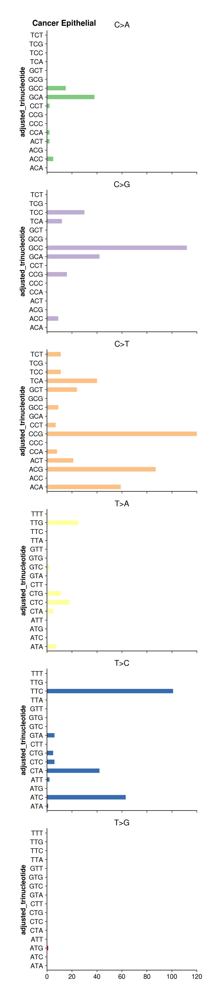

In [386]:
neo_cancer_grouped = plot_neoantigen_bars2(extract_neoantigens_celltypes("Cancer Epithelial", 
                     weightsmajortypes2, cat="majortype"), split=False, lim=120, title="Cancer Epithelial")

#### Supp Fig 7

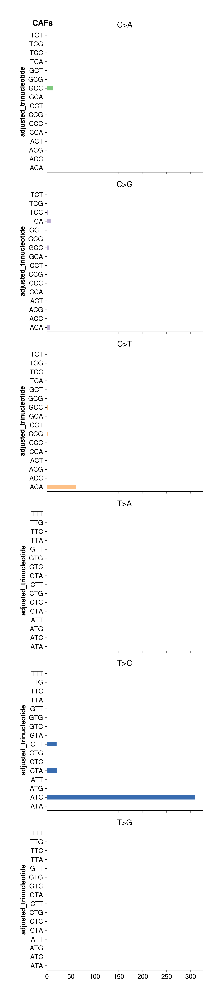

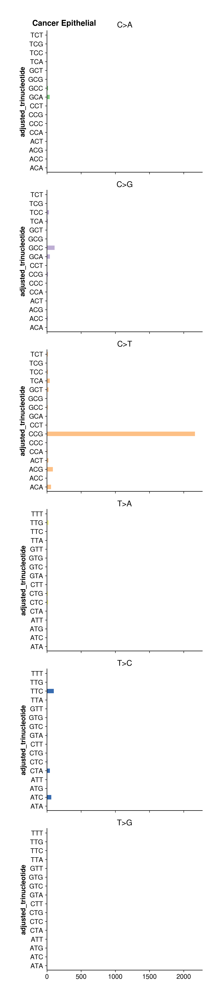

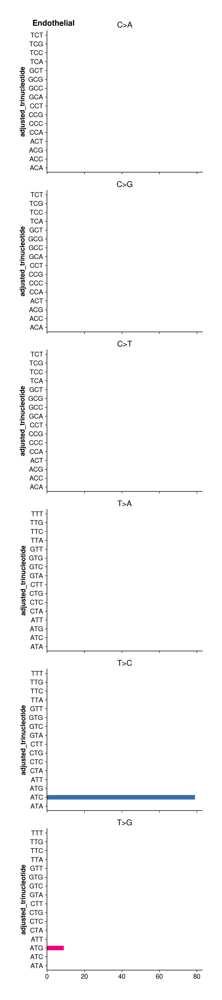

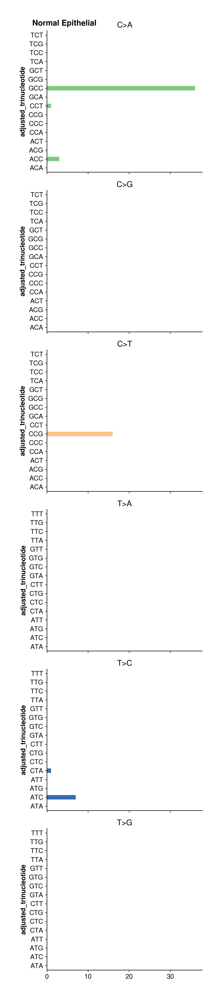

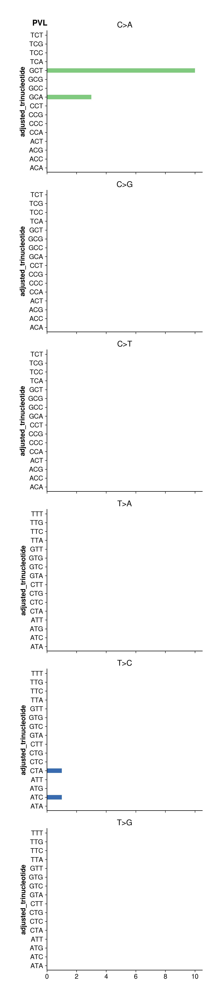

In [387]:
for cell in sorted_subtypes[sorted_subtypes.main!="Immune"].major.unique():
    plot_neoantigen_bars2(extract_neoantigens_celltypes(cell, weightsmajortypes2, cat="majortype"), title=cell)

### Boxplots

#### Fig 4c

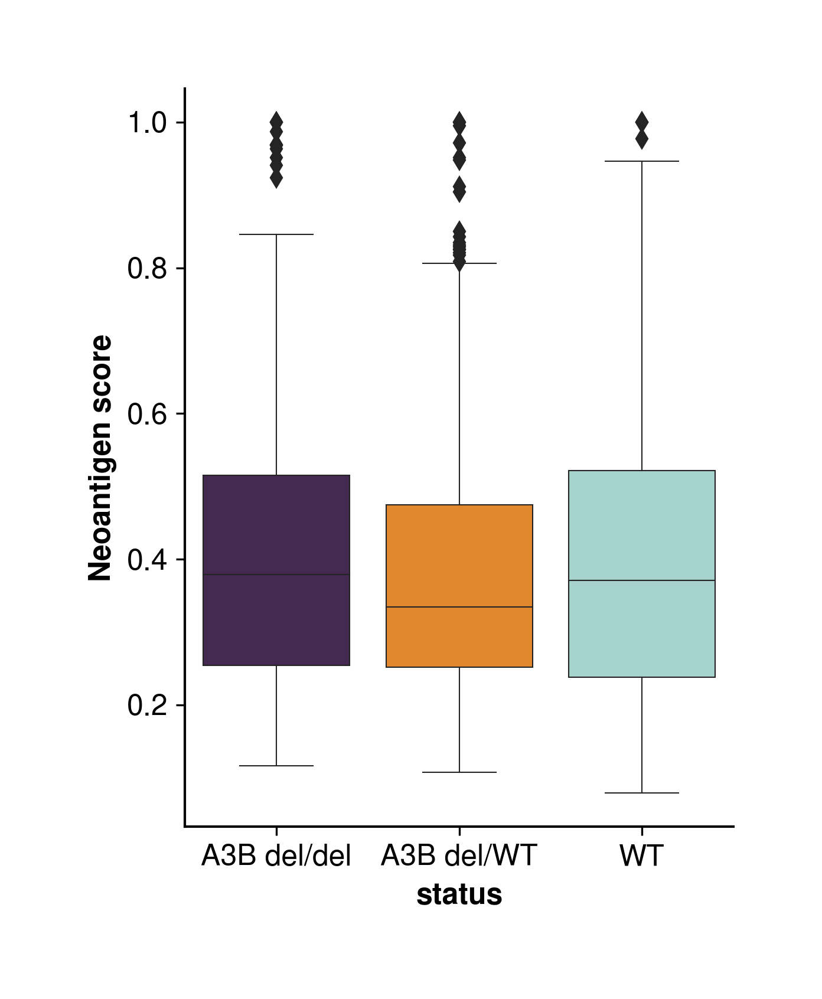

In [295]:
plt.figure(figsize=(4,5), dpi=300)
df = pd.concat(all_neo_list)
df = df[df["normlogfiltered"]>0]
ax = sns.boxplot(data=df, x="status", y="normlogfiltered", palette=palette7)
plt.ylabel("Neoantigen score")
plt.show()
# if save:
#     plt.savefig("/stereoseq/all_samples/images/paper1/4C.neoantigens.box.{}.pdf".format(x), format="pdf", dpi=300)

### Heatmap

#### Fig 4d

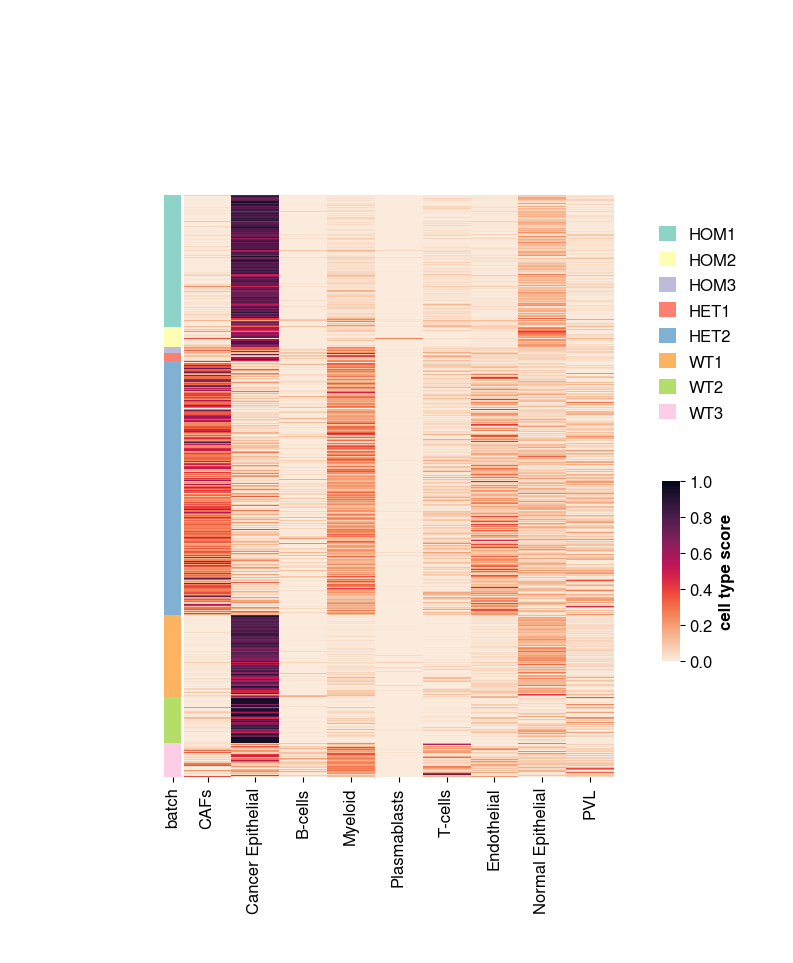

In [388]:
df1 = pd.concat(weightsmajor2)
df2 = big_neo_list[0]
df1["score"] = df2["normlogfiltered"].to_list()
df3 = df1[df1["score"]>0]
df3['sample'] = pd.Categorical(df3['batch'], categories=datalist, ordered=True).codes
# plt.figure(figsize=(6,8), dpi=300)
# sns.heatmap(data=df3.filter(["sample"]), cmap="Set3")
# plt.xticks([])
# plt.yticks([])

row_lut = dict(zip(datalist, sns.color_palette("Set3").as_hex()[:]))
row_colors = df3["batch"].map(row_lut)
pp = sns.clustermap(data=df3.filter(sorted_subtypes["major"].unique()), cmap="rocket_r", 
               row_colors=row_colors, yticklabels=False, vmin=0, vmax=1,
               row_cluster=False, col_cluster=False, figsize=(6,9),
               cbar_pos=(1.05, .3, .03, .2), cbar_kws={"label":"cell type score"})

from matplotlib.patches import Patch
handles = [Patch(facecolor=row_lut[name]) for name in row_lut]
plt.legend(handles, row_lut, #title="batch",
           bbox_to_anchor=(1.2, .8), bbox_transform=plt.gcf().transFigure, loc='upper right')
# pp.savefig("/stereoseq/all_samples/images/paper1/4D.neoantigens.celltypes.bins.heatmap.annot.pdf", dpi=300)

In [324]:
def plot_neoantigen_celltypes_vis2(df, palette="magma", t=False, save=False):
    gp = pd.DataFrame(index=sorted_subtypes.major.unique())
    df["majortype"] = weightsmajortypes2["majortype"].to_list()
    df1 = df[df["normlogfiltered"]>0]
    gp["neoantigen"] = df1.groupby(by="majortype", sort=False, group_keys=True).count().reindex(sorted_subtypes.major.unique(), fill_value=0).x.to_list()
    plt.figure(dpi=300)
    sns.heatmap(data=gp.T, cmap=palette, annot=True, fmt="d",
                cbar_kws={"shrink":.3, "label":"bin counts"}, square=True)
    plt.xlabel("")
    plt.yticks([])
    if save:
        plt.savefig("/stereoseq/all_samples/images/paper1/Supp.neoantigens.celltypes.bincounts.pdf", format="pdf", dpi=300)

#### Supp Fig 6a

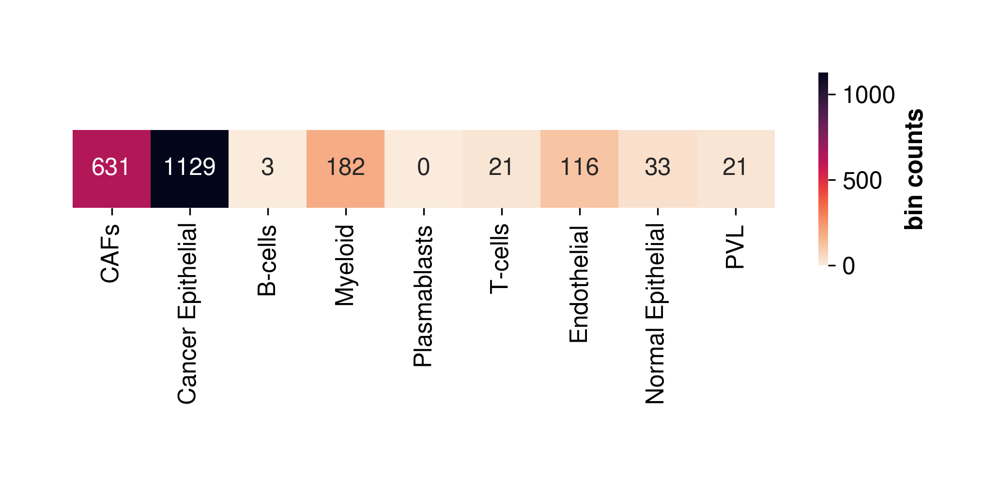

In [389]:
plot_neoantigen_celltypes_vis2(big_neo_list[0], palette="rocket_r")

### Forestplots

In [390]:
## non-zero bins

df = pd.concat(big_neo_list)
df["neo"] = df["normlogfiltered"].to_list()
df["group"] = pd.Categorical(df["status"], categories=["A3B del/del", "A3B del/WT", "WT"])
print(df[df["neo"]>0].groupby(by="status", sort=False).count()["total_counts"])
# print(df.groupby(by="status", sort=False).count()["total_counts"])

cov_struct = Exchangeable()

model = smf.gee(
    formula = "neo ~ group",
    groups = "sample",
    data = df[df["neo"]>0],
    family = sm.families.Gaussian(),
    cov_struct = cov_struct
)

result = model.fit()

# print(result.summary())

tmpdf = pd.DataFrame(index=["A3B del/del", "A3B del/WT", "WT"])
tmpdf["pvalues"] = result.pvalues.to_list()
tmpdf["beta"] = result.params.to_list()
tmpdf["ci_low"] = result.conf_int()[0].to_list()
tmpdf["ci_high"] = result.conf_int()[1].to_list()
tmpdf["data"] = "Full"
resdfneo2 = tmpdf.reset_index()

status
A3B del/del    581
A3B del/WT     960
WT             595
Name: total_counts, dtype: int64


#### Supp Fig 8c

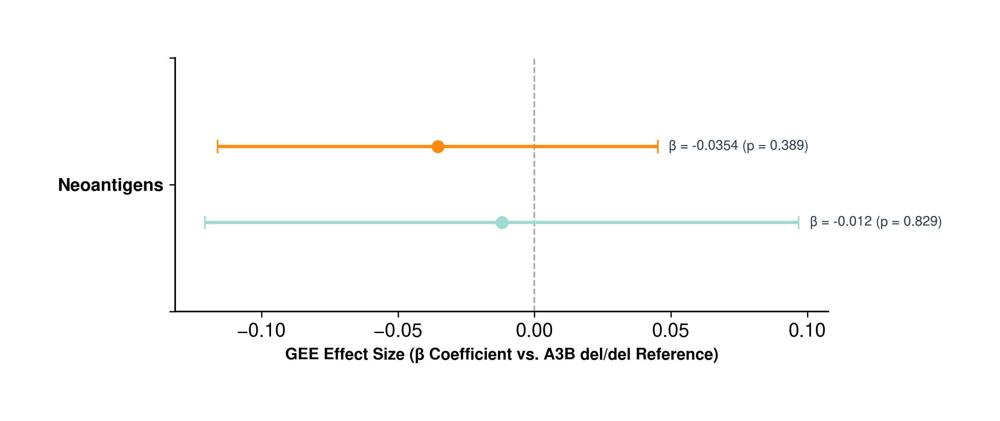

In [391]:
groups = ['A3B del/WT', 'WT']
colors = {"A3B del/del":"#462356", "A3B del/WT":"#FF8811", "WT":"#9EDAD3"}

fig, ax = plt.subplots(figsize=(8, 3), dpi=300)

# Set vertical spacing per gene cluster
offset = {'A3B del/WT': 0.3, 'WT': -0.3} # Shift points slightly up/down

# Plot null reference line at 0 (No effect)
ax.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)

# Loop and plot points + CIs
# for idx, mut in enumerate(reversed(muts)): # Reverse to list top-to-bottom
#     y_center = y_base[idx]
    
for grp in groups:
    row = resdfneo2[resdfneo2["index"] == grp]
    if row.empty:
        continue
        
    # y_pos = y_center + offset[grp]
    y_pos = 1 + offset[grp]
    beta = row["beta"].values[0]
    ci_low = row["ci_low"].values[0]
    ci_high = row["ci_high"].values[0]
    p_val = row["pvalues"].values[0]
    
    # Error bar plot
    ax.errorbar(
        x=beta, y=y_pos,
        xerr=[[beta - ci_low], [ci_high - beta]],
        fmt='o', color=colors[grp], ecolor=colors[grp],
        elinewidth=2, capsize=4, markersize=7, #label=grp if idx == 0 else ""
    )
    
    # Annotate text: "β = X.XX (p = X.XXX)"
    p_text = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"
    annotation = f"β = {beta:+.3g} ({p_text})"
    
    # Position text to the right of the error bar
    ax.text(ci_high + 0.004, y_pos, annotation, va='center', fontsize=8.5, color='#2c3e50')

# Y-axis styling
ax.set_yticks([0,1,2])
ax.set_yticklabels(["","Neoantigens",""], fontsize=11, fontweight='bold')
ax.set_xlabel('GEE Effect Size (β Coefficient vs. A3B del/del Reference)', fontsize=10, fontweight='bold')
# ax.set_title('GEE Spatial Neoantigens across A3Bdel statuses', fontsize=12, fontweight='bold', pad=15)

# Formatting limits and grid
# ax.set_xlim(-.1,.1) # Adjust based on your min/max Beta values
# ax.grid(axis='x', linestyle=':', alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Add Legend
ax.legend(bbox_to_anchor=(1.1,1), fontsize=8, loc='upper right')

plt.tight_layout()
# plt.savefig(f"/stereoseq/all_samples/images/paper1/{d}.Fig4c.neoantigens.nonzero.GEE.forestplot.pdf", dpi=300, format="pdf")
plt.show()

## ssGSEA

### Forestplots

In [332]:
ssgsea_a3a = pd.concat(ssgsea)
ssgsea_a3a["A3A_status"] = pd.qcut(ssgsea_a3a["APOBEC3A_INTERACTING_PROTEINS"], 2, labels=["A3A Low","A3A High"], duplicates="drop")

ssgsea_a3a_df = ssgsea_a3a.melt(id_vars=["sample","status","APOBEC3A_INTERACTING_PROTEINS","A3A_status"], 
                                                   value_vars=pathways, value_name="score", var_name="pathway", ignore_index=False)

In [392]:
## all bins
resdfs = []
df = ssgsea_a3a.copy()
df["group"] = pd.Categorical(df["A3A_status"], categories=["A3A Low","A3A High"])
for gene in final_pathways:

    cov_struct = Exchangeable()
    
    model = smf.gee(
        formula = f"{gene} ~ group",
        groups = "sample",
        data = df,#[df["gene"]>0],
        family = sm.families.Gaussian(),
        cov_struct = cov_struct
    )
    
    result = model.fit()
    # print("\n",gene)
    # print(result.summary())

    tmpdf = pd.DataFrame(index=["A3A Low","A3A High"])
    tmpdf["gene"] = gene
    tmpdf["pvalues"] = result.pvalues.to_list()
    tmpdf["beta"] = result.params.to_list()
    tmpdf["ci_low"] = result.conf_int()[0].to_list()
    tmpdf["ci_high"] = result.conf_int()[1].to_list()
    tmpdf["data"] = "Full"
    tmpdf["n"] = df.groupby(by="A3A_status", sort=False).size().to_list()
    resdfs.append(tmpdf.reset_index())
resdf_full = pd.concat(resdfs)

#### Fig 6a

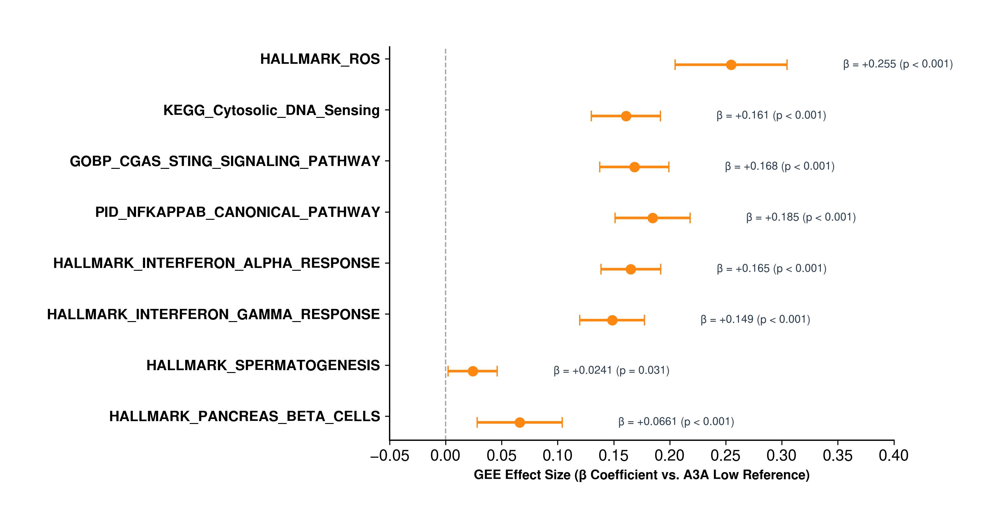

In [393]:
### forest plot
# Genes in order of appearance (top to bottom)
genes = final_pathways.copy()
groups = ["A3A High"]
colors = {"A3A Low":"#462356", "A3A High":"#FF8811"} # Blue for het, Green for WT
# datasets = ["Full","Non-zero"]
# markers = {'Full': 'o', 'Non-zero': 's'}

fig, ax = plt.subplots(figsize=(10,5), dpi=300)

# Set vertical spacing per gene cluster
y_base = np.arange(len(genes)) * 2.5  # Space genes out
offset = {'A3A Low': 0.3, 'A3A High': -0.3} # Shift points slightly up/down

# Plot null reference line at 0 (No effect)
ax.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
# ax.axvline(x=.2, color='lightblue', linestyle='--', linewidth=1, alpha=0.7)

# Loop and plot points + CIs
for idx, gene in enumerate(reversed(genes)): # Reverse to list top-to-bottom
    y_center = y_base[idx]
    
    for grp in groups:
        row = resdf_full[(resdf_full["gene"] == gene) & (resdf_full["index"] == grp)]
        if row.empty:
            continue
            
        y_pos = y_center + offset[grp]
        beta = row["beta"].values[0]
        ci_low = row["ci_low"].values[0]
        ci_high = row["ci_high"].values[0]
        p_val = row["pvalues"].values[0]
        n_samples = row["n"].values[0]
        
        # Error bar plot
        ax.errorbar(
            x=beta, y=y_pos,
            xerr=[[beta - ci_low], [ci_high - beta]],
            fmt='o', color=colors[grp], ecolor=colors[grp],
            elinewidth=2, capsize=4, markersize=7, label=grp if idx == 0 else ""
        )
        
        # Annotate text: "β = X.XX (p = X.XXX)"
        p_text = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"
        annotation = f"β = {beta:+.3g} ({p_text})"
        
        # Position text to the right of the error bar
        ax.text(ci_high + 0.05, y_pos, annotation, va='center', fontsize=8.5, color='#2c3e50')

# Y-axis styling
ax.set_yticks(y_base)
ax.set_yticklabels(reversed(genes), fontsize=11, fontweight='bold')
ax.set_xlabel('GEE Effect Size (β Coefficient vs. A3A Low Reference)', fontsize=10, fontweight='bold')
# ax.set_title('GEE pathway (Cancer Epithelium) across A3A status', fontsize=12, fontweight='bold', pad=15)

# Formatting limits and grid
ax.set_xlim(-.05,.4) # Adjust based on your min/max Beta values
# ax.grid(axis='x', linestyle=':', alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Add Legend
# ax.legend(title='Contrast vs A3A Low', bbox_to_anchor=(1.2,1), fontsize=8, loc='upper right')

plt.tight_layout()
# plt.savefig(f"/stereoseq/all_samples/images/paper1/Fig6a_ssgsea_pathways_forest_plot.updated.pdf", dpi=300, format="pdf")
plt.show()

## RNAseq

### Boxplots

In [339]:
tnbc = pd.read_csv("/stereoseq/code/RNAseq.TNBC.ids.txt", sep="\t", index_col=1).drop(columns=["Unnamed: 0"])
rnaseq = pd.read_csv("/stereoseq/all_samples/ssgsea/MyBrCa_TNBC.gsva_out.txt", sep="\t", index_col=0)
rnaseq["APOBEC3A"] = pd.read_csv("/stereoseq/all_samples/rnaseq/MyBrCa_Batch1_and_2_counts_voomed.txt", sep="\t", index_col=0).T["APOBEC3A"]

In [343]:
df = tnbc.join(rnaseq)
# df = df.filter(final_pathways)
df["A3A"] = pd.qcut(rnaseq["APOBEC3A"], 2, labels=["Low","High"])
xx = df[df["A3A"]=="Low"]
yy = df[df["A3A"]=="High"]
dfpathwaymelt = df.melt(id_vars="A3A", value_vars=final_pathways, value_name="score", var_name="pathway", ignore_index=True)

#### Fig 6b

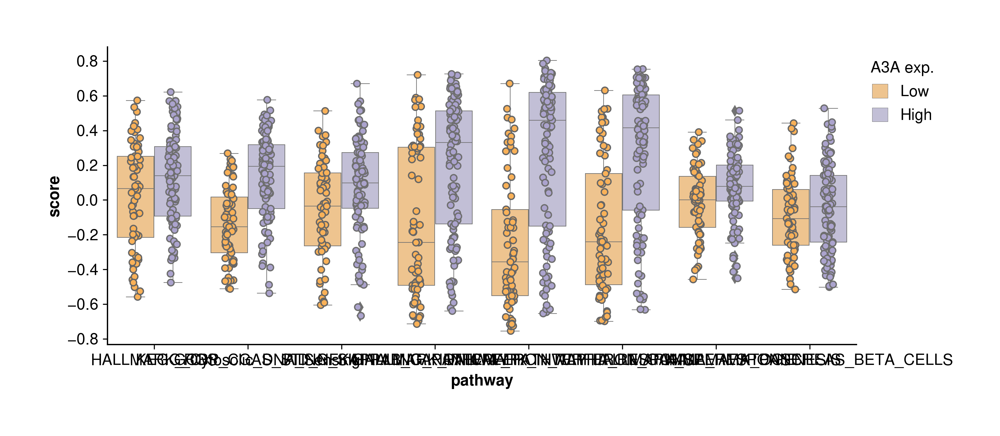

In [394]:
plt.figure(figsize=(10,4), dpi=300)
sns.boxplot(data=dfpathwaymelt, x="pathway", y="score", hue="A3A", palette="PuOr")
sns.stripplot(data=dfpathwaymelt, x="pathway", y="score", hue="A3A", dodge=True, legend=False,
              linewidth=1, palette=["#f9b158","#aba3cd"])
# plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1,1), title="A3A exp.")
# plt.savefig(f"/stereoseq/all_samples/images/paper1/updated.RNAseq.TNBC.all.A3A.box.pdf", format="pdf", dpi=300)